# Explainable Machine Learning for Customer Churn Prediction and Retention Strategy Design


## 1. Project Introduction


This capstone develops an explainable customer churn workflow that connects predictive modeling with retention strategy design. The notebook prepares the raw banking churn dataset, documents data quality, explores churn behavior, engineers modeling-ready features, and sets up the later machine learning, explainability, segmentation, and business impact stages.

This update preserves the existing EDA, visualization, preprocessing, and feature engineering work. The downstream modeling sections are scaffolded for the next phase but are not executed here.


### Dataset Context and Target Definition


Dataset file: `Churn_Modelling.csv`

Target variable:
- `Exited = 1` means the customer churned.
- `Exited = 0` means the customer did not churn.

Columns that should not be used as model features later:
- `RowNumber`
- `CustomerId`
- `Surname`

`CustomerId` should be kept separately for customer-level tracking, risk segmentation, explainability outputs, and retention actions.


## 2. Dataset Loading

The raw bank customer churn dataset is loaded directly from the capstone data folder into the dataframe `df`. The original CSV is treated as read-only; downstream sections create separate working dataframes for analysis, feature engineering, and later modeling setup.


In [1]:
import pathlib
import importlib
import warnings

import pandas as pd
import numpy as np
import matplotlib as mpl

# Some Anaconda/Jupyter environments do not attach matplotlib submodules lazily.
# Import them explicitly before pyplot/seaborn so charts run reliably.
mpl.backends = importlib.import_module("matplotlib.backends")
mpl.colors = importlib.import_module("matplotlib.colors")
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
)

try:
    from xgboost import XGBClassifier
except ImportError:
    XGBClassifier = None
    # pip install xgboost

try:
    from imblearn.over_sampling import RandomOverSampler, SMOTENC
except ImportError:
    RandomOverSampler = None
    SMOTENC = None
    # pip install imbalanced-learn

try:
    import shap
except ImportError:
    shap = None
    # pip install shap

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
DATASET_PATH = r"D:\FPT University\Coding\DSP\data\Churn_Modelling.csv"

# Load the dataset into df. The raw CSV file is read only and is not modified.
df = pd.read_csv(r"D:\FPT University\Coding\DSP\data\Churn_Modelling.csv")

print("Dataset loaded successfully.")
print(f"Dataset path: {DATASET_PATH}")
print("Dataframe name: df")


Dataset loaded successfully.
Dataset path: D:\FPT University\Coding\DSP\data\Churn_Modelling.csv
Dataframe name: df


c:\Users\admin\.conda\envs\dsp\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 3. Data Quality Check

This section verifies the dataset shape, column names, data types, missing values, duplicate records, and target balance. These checks establish whether cleaning or class imbalance handling may be needed later, before any model training is performed.


In [2]:
target_column = "Exited"

print("1. Dataset shape:")
print(df.shape)

print("\n2. Column names:")
print(list(df.columns))

print("\n3. Data types:")
display(df.dtypes.to_frame("data_type"))

print("\n4. First 5 rows:")
display(df.head())

print("\n5. Missing values by column:")
missing_values_by_column = df.isna().sum().to_frame("missing_count")
missing_values_by_column["missing_percentage"] = (df.isna().mean() * 100).round(2)
display(missing_values_by_column)

print("\n6. Total missing values:")
total_missing_values = int(df.isna().sum().sum())
print(total_missing_values)

print("\n7. Duplicate row count:")
duplicate_row_count = int(df.duplicated().sum())
print(duplicate_row_count)

print("\n8. Target distribution:")
target_counts = df[target_column].value_counts().sort_index()
display(target_counts.to_frame("customer_count"))

print("\n9. Target percentage:")
target_percentages = (df[target_column].value_counts(normalize=True).sort_index() * 100).round(2)
display(target_percentages.to_frame("percentage"))

print("\n10. Churn rate:")
churn_rate = float(df[target_column].mean())
print(f"{churn_rate:.4f} ({churn_rate * 100:.2f}%)")


1. Dataset shape:
(10000, 14)

2. Column names:
['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']

3. Data types:


,data_type
RowNumber,int64
CustomerId,int64
Surname,object
CreditScore,int64
Geography,object
Gender,object
Age,int64
Tenure,int64
Balance,float64
NumOfProducts,int64



4. First 5 rows:


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0



5. Missing values by column:


...


6. Total missing values:
0

7. Duplicate row count:
0

8. Target distribution:


,customer_count
Exited,
0,7963
1,2037



9. Target percentage:


,percentage
Exited,
0,79.63
1,20.37



10. Churn rate:
0.2037 (20.37%)


This is a bank customer churn dataset.

- The target variable is `Exited`.
- `Exited = 1` means churn.
- `Exited = 0` means non-churn.
- The target distribution will be used later to decide whether class imbalance handling is needed.


In [3]:
print("DataFrame info:")
df.info()


DataFrame info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [4]:
print("Numeric descriptive statistics:")
display(df.describe().T)

categorical_columns = df.select_dtypes(include=["object", "string", "category"]).columns.tolist()
print("Categorical descriptive statistics:")
if categorical_columns:
    display(df[categorical_columns].describe().T)
else:
    print("No categorical columns detected.")


Numeric descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
RowNumber,10000.0,5.000500e+03,2886.895680,1.00,2500.75,5.000500e+03,7.500250e+03,10000.00
CustomerId,10000.0,1.569094e+07,71936.186123,15565701.00,15628528.25,1.569074e+07,1.575323e+07,15815690.00
CreditScore,10000.0,6.505288e+02,96.653299,350.00,584.00,6.520000e+02,7.180000e+02,850.00
Age,10000.0,3.892180e+01,10.487806,18.00,32.00,3.700000e+01,4.400000e+01,92.00
Tenure,10000.0,5.012800e+00,2.892174,0.00,3.00,5.000000e+00,7.000000e+00,10.00
Balance,10000.0,7.648589e+04,62397.405202,0.00,0.00,9.719854e+04,1.276442e+05,250898.09
NumOfProducts,10000.0,1.530200e+00,0.581654,1.00,1.00,1.000000e+00,2.000000e+00,4.00
HasCrCard,10000.0,7.055000e-01,0.455840,0.00,0.00,1.000000e+00,1.000000e+00,1.00
IsActiveMember,10000.0,5.151000e-01,0.499797,0.00,0.00,1.000000e+00,1.000000e+00,1.00
EstimatedSalary,10000.0,1.000902e+05,57510.492818,11.58,51002.11,1.001939e+05,1.493882e+05,199992.48


Categorical descriptive statistics:


,count,unique,top,freq
Surname,10000,2932,Smith,32
Geography,10000,3,France,5014
Gender,10000,2,Male,5457


In [5]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_rate_%": (df.isna().mean() * 100).round(2),
}).sort_values("missing_count", ascending=False)

duplicate_row_count = int(df.duplicated().sum())

print("Missing value summary:")
display(missing_summary)

print("Duplicate row count:")
print(duplicate_row_count)


Missing value summary:


,missing_count,missing_rate_%
RowNumber,0,0.0
CustomerId,0,0.0
Surname,0,0.0
CreditScore,0,0.0
Geography,0,0.0
Gender,0,0.0
Age,0,0.0
Tenure,0,0.0
Balance,0,0.0
NumOfProducts,0,0.0


Duplicate row count:
0


In [6]:
unique_value_columns = [
    "Geography", "Gender", "HasCrCard", "IsActiveMember", "NumOfProducts", "Exited",
]

unique_values_summary = pd.DataFrame([
    {
        "ColumnName": column,
        "UniqueCount": int(df[column].nunique(dropna=True)),
        "UniqueValues": sorted(df[column].dropna().unique().tolist()),
    }
    for column in unique_value_columns
])

display(unique_values_summary)


,ColumnName,UniqueCount,UniqueValues
0,Geography,3,"[France, Germany, Spain]"
1,Gender,2,"[Female, Male]"
2,HasCrCard,2,"[0, 1]"
3,IsActiveMember,2,"[0, 1]"
4,NumOfProducts,4,"[1, 2, 3, 4]"
5,Exited,2,"[0, 1]"


In [7]:
numeric_range_columns = [
    "CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary",
]

range_rows = []
for column in numeric_range_columns:
    series = df[column].astype(float)
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    iqr_outlier_count = int(((series < lower_bound) | (series > upper_bound)).sum())
    range_rows.append({
        "ColumnName": column,
        "Minimum": series.min(),
        "Q1": q1,
        "Median": series.median(),
        "Q3": q3,
        "Maximum": series.max(),
        "IQR": iqr,
        "IQR_LowerBound": lower_bound,
        "IQR_UpperBound": upper_bound,
        "IQR_OutlierCount": iqr_outlier_count,
    })

numeric_range_summary = pd.DataFrame(range_rows).round(2)
display(numeric_range_summary)


,ColumnName,Minimum,Q1,Median,Q3,Maximum,IQR,IQR_LowerBound,IQR_UpperBound,IQR_OutlierCount
0,CreditScore,350.00,584.00,652.00,718.00,850.00,134.00,383.00,919.00,15
1,Age,18.00,32.00,37.00,44.00,92.00,12.00,14.00,62.00,359
2,Tenure,0.00,3.00,5.00,7.00,10.00,4.00,-3.00,13.00,0
3,Balance,0.00,0.00,97198.54,127644.24,250898.09,127644.24,-191466.36,319110.60,0
4,NumOfProducts,1.00,1.00,1.00,2.00,4.00,1.00,-0.50,3.50,60
5,EstimatedSalary,11.58,51002.11,100193.92,149388.25,199992.48,98386.14,-96577.10,296967.45,0


In [8]:
quality_comments = []

if int(df.isna().sum().sum()) == 0:
    quality_comments.append("No missing values were detected in the raw dataset.")
else:
    quality_comments.append("Missing values are present and should be handled before modeling.")

if duplicate_row_count == 0:
    quality_comments.append("No fully duplicated rows were detected.")
else:
    quality_comments.append(f"{duplicate_row_count} duplicated row(s) were detected and should be reviewed.")

if (df["Balance"] == 0).any():
    quality_comments.append("Zero-balance customers are present; this is a meaningful customer state, not automatically an error.")

outlier_columns = numeric_range_summary.loc[
    numeric_range_summary["IQR_OutlierCount"] > 0,
    "ColumnName",
].tolist()
if outlier_columns:
    quality_comments.append(
        "Possible statistical outliers were detected by the IQR rule in: "
        + ", ".join(outlier_columns)
        + ". These values should be reviewed, but not removed only because they are outliers."
    )
else:
    quality_comments.append("No IQR-based numeric outliers were detected in the selected range-check columns.")

if df["Age"].max() >= 80:
    quality_comments.append("Older customers are present in the dataset; high age values may be valid but should be considered during EDA.")

for comment in quality_comments:
    print("- " + comment)


- No missing values were detected in the raw dataset.
- No fully duplicated rows were detected.
- Zero-balance customers are present; this is a meaningful customer state, not automatically an error.
- Possible statistical outliers were detected by the IQR rule in: CreditScore, Age, NumOfProducts. These values should be reviewed, but not removed only because they are outliers.
- Older customers are present in the dataset; high age values may be valid but should be considered during EDA.


## 4. Exploratory Data Analysis

The EDA section examines churn patterns across customer demographics, account behavior, product usage, and numeric distributions. The goal is to identify interpretable churn signals that can inform both modeling choices and retention strategy design.


This section explores churn patterns using summary tables and charts only. The raw dataframe `df` is not modified, and no model training is performed.


In [9]:
# EDA setup: use a copy for display labels and grouping variables.
required_columns = [
    "Exited", "Geography", "Gender", "IsActiveMember", "HasCrCard",
    "NumOfProducts", "Age", "Tenure", "Balance", "CreditScore", "EstimatedSalary",
]

missing_required_columns = [column for column in required_columns if column not in df.columns]
if missing_required_columns:
    raise KeyError(f"Missing required columns for EDA: {missing_required_columns}")

eda_df = df.copy()

eda_df["ExitedLabel"] = np.where(
    eda_df["Exited"].eq(1),
    "Churned",
    "Did not churn"
)

eda_df["IsActiveMemberLabel"] = (
    eda_df["IsActiveMember"]
    .map({0: "Inactive", 1: "Active"})
    .fillna("Unknown")
)

eda_df["HasCrCardLabel"] = (
    eda_df["HasCrCard"]
    .map({0: "No credit card", 1: "Has credit card"})
    .fillna("Unknown")
)

age_group_order = ["18-30", "31-40", "41-50", "51-60", "60+"]
balance_group_order = ["Zero balance", "Low balance", "Medium balance", "High balance", "Very high balance"]

eda_df["AgeGroup"] = pd.cut(
    eda_df["Age"],
    bins=[0, 30, 40, 50, 60, np.inf],
    labels=age_group_order,
    include_lowest=True,
)

eda_df["BalanceGroup"] = np.select(
    [
        eda_df["Balance"].eq(0),
        eda_df["Balance"].between(0.01, 50000),
        eda_df["Balance"].between(50000.01, 100000),
        eda_df["Balance"].between(100000.01, 150000),
        eda_df["Balance"].gt(150000),
    ],
    balance_group_order,
    default="Unknown",
)

exit_order = ["Did not churn", "Churned"]
chart_colors = ["#4C78A8", "#F58518", "#54A24B", "#E45756", "#72B7B2", "#B279A2"]

plt.style.use("default")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

print("EDA dataframe prepared for visualization only.")
print(f"Rows: {eda_df.shape[0]} | Columns: {eda_df.shape[1]}")


EDA dataframe prepared for visualization only.
Rows: 10000 | Columns: 19


### 5.1 Exited Distribution


,Exited,customer_count,percentage
0,Did not churn,7963,79.63
1,Churned,2037,20.37


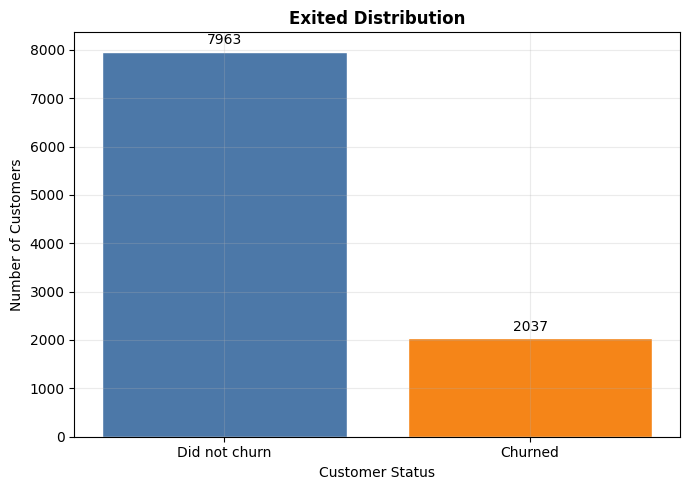

In [10]:
exited_distribution = (
    eda_df["ExitedLabel"]
    .value_counts()
    .reindex(exit_order)
    .rename_axis("Exited")
    .reset_index(name="customer_count")
)
exited_distribution["percentage"] = (
    exited_distribution["customer_count"] / exited_distribution["customer_count"].sum() * 100
).round(2)

display(exited_distribution)

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(
    exited_distribution["Exited"],
    exited_distribution["customer_count"],
    color=chart_colors[:2],
    edgecolor="white",
)
ax.set_title("Exited Distribution")
ax.set_xlabel("Customer Status")
ax.set_ylabel("Number of Customers")
ax.bar_label(bars, padding=3)
plt.tight_layout()
plt.show()


**Business insight:** Biểu đồ phân phối Exited cho thấy dữ liệu bị mất cân bằng giữa hai nhóm khách hàng. Phần lớn khách hàng không rời bỏ ngân hàng, chiếm khoảng 79.63%, trong khi nhóm khách hàng đã rời bỏ chiếm khoảng 20.37%.

Về mặt kinh doanh, điều này cho thấy churn tuy không phải là hành vi chiếm đa số, nhưng vẫn là vấn đề đáng quan tâm vì cứ khoảng 5 khách hàng thì có 1 khách hàng rời bỏ ngân hàng. Vì vậy, doanh nghiệp cần phân tích sâu hơn nhóm khách hàng churn để tìm ra các đặc điểm chung và nguyên nhân tiềm ẩn.

Kết quả này cũng là cơ sở quan trọng cho các bước phân tích tiếp theo. Nếu sau này xây dựng mô hình dự đoán churn, không nên chỉ đánh giá bằng accuracy, vì mô hình có thể dự đoán phần lớn khách hàng là không churn mà vẫn đạt độ chính xác cao nhưng lại bỏ sót nhóm khách hàng có nguy cơ rời bỏ.


### 5.2 Churn Rate by Customer Attributes


In [11]:
def churn_summary_by(column):
    summary = (
        eda_df.groupby(column, dropna=False, observed=False)["Exited"]
        .agg(["count", "sum", "mean"])
        .rename(columns={"count": "customer_count", "sum": "churn_count", "mean": "churn_rate"})
        .reset_index()
    )
    summary["churn_rate_%"] = (summary["churn_rate"] * 100).round(2)
    summary = summary.drop(columns="churn_rate")
    return summary


def plot_churn_rate(column, title, xlabel, order=None, rotation=0):
    summary = churn_summary_by(column)
    if order is not None:
        summary[column] = pd.Categorical(summary[column], categories=order, ordered=True)
        summary = summary.sort_values(column)
    else:
        summary = summary.sort_values("churn_rate_%", ascending=False)

    display(summary)

    labels = summary[column].astype(str).tolist()
    values = summary["churn_rate_%"].to_numpy()
    colors = [chart_colors[i % len(chart_colors)] for i in range(len(labels))]

    fig, ax = plt.subplots(figsize=(8, 5))
    bars = ax.bar(labels, values, color=colors, edgecolor="white")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Churn Rate (%)")
    upper_limit = max(values.max() * 1.25, 5)
    ax.set_ylim(0, upper_limit)
    ax.bar_label(bars, labels=[f"{value:.1f}%" for value in values], padding=3)
    plt.xticks(rotation=rotation, ha="right" if rotation else "center")
    plt.tight_layout()
    plt.show()

    return summary


,Geography,customer_count,churn_count,churn_rate_%
1,Germany,2509,814,32.44
2,Spain,2477,413,16.67
0,France,5014,810,16.15


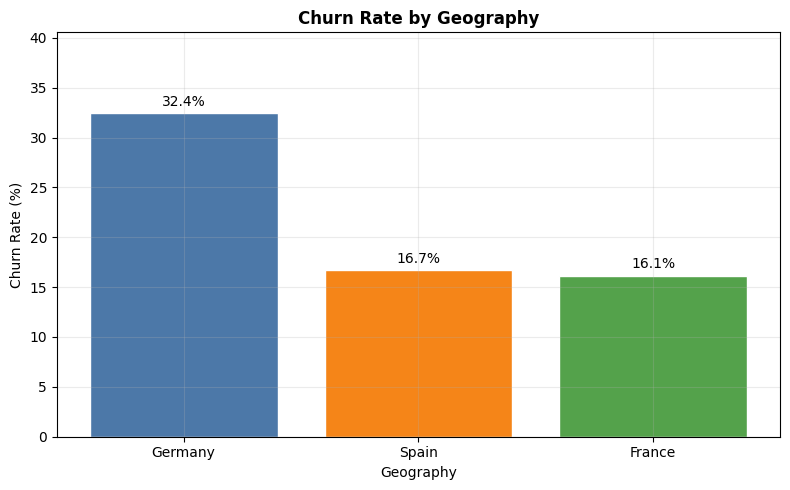

In [12]:
geography_churn = plot_churn_rate("Geography", "Churn Rate by Geography", "Geography")


**Business insight:** Khách hàng ở Germany có tỷ lệ churn cao nhất, khoảng 32.44%, gần gấp đôi so với France và Spain. Điều này cho thấy thị trường Germany có thể đang tồn tại vấn đề về trải nghiệm khách hàng, chính sách phí, mức độ cạnh tranh hoặc sự phù hợp của sản phẩm. Đây là nhóm cần được phân tích sâu hơn trong các bước tiếp theo.


,Gender,customer_count,churn_count,churn_rate_%
0,Female,4543,1139,25.07
1,Male,5457,898,16.46


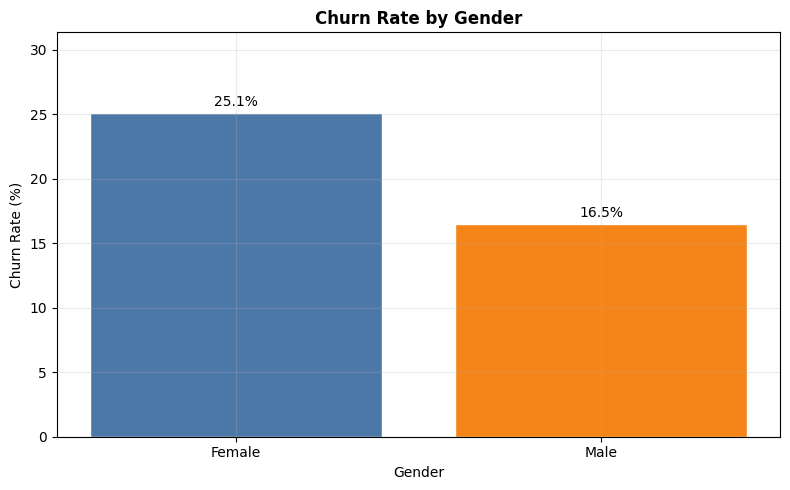

In [13]:
gender_churn = plot_churn_rate("Gender", "Churn Rate by Gender", "Gender")


**Business insight:** Nhóm Female có tỷ lệ churn khoảng 25.07%, cao hơn nhóm Male với khoảng 16.46%. Điều này cho thấy trong dataset này, khách hàng nữ có xu hướng rời bỏ ngân hàng nhiều hơn. Tuy nhiên, vì Gender là biến nhạy cảm, kết quả này chỉ nên được xem là tín hiệu mô tả ban đầu và cần phân tích thêm cùng các biến như Age, Balance, IsActiveMember, NumOfProducts và Geography để hiểu nguyên nhân thực tế.


,IsActiveMemberLabel,customer_count,churn_count,churn_rate_%
1,Inactive,4849,1302,26.85
0,Active,5151,735,14.27


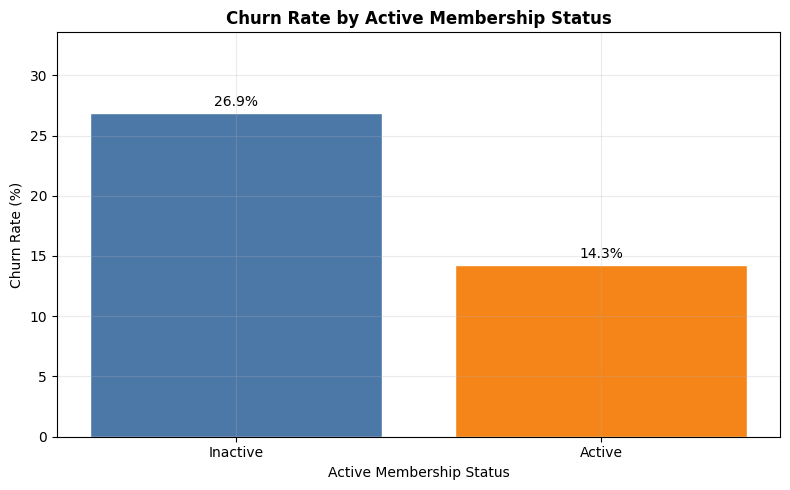

In [14]:
active_member_churn = plot_churn_rate("IsActiveMemberLabel", "Churn Rate by Active Membership Status", "Active Membership Status", order=["Inactive", "Active"])


**Business insight:** Khách hàng Inactive có tỷ lệ churn khoảng 26.85%, cao hơn nhiều so với nhóm Active với khoảng 14.27%. Điều này cho thấy mức độ hoạt động của khách hàng là một yếu tố quan trọng liên quan đến churn. Về mặt kinh doanh, ngân hàng nên tập trung vào các chiến dịch re-engagement như ưu đãi giao dịch, cashback hoặc nhắc sử dụng app để kích hoạt lại nhóm khách hàng ít hoạt động.

,HasCrCardLabel,customer_count,churn_count,churn_rate_%
1,No credit card,2945,613,20.81
0,Has credit card,7055,1424,20.18


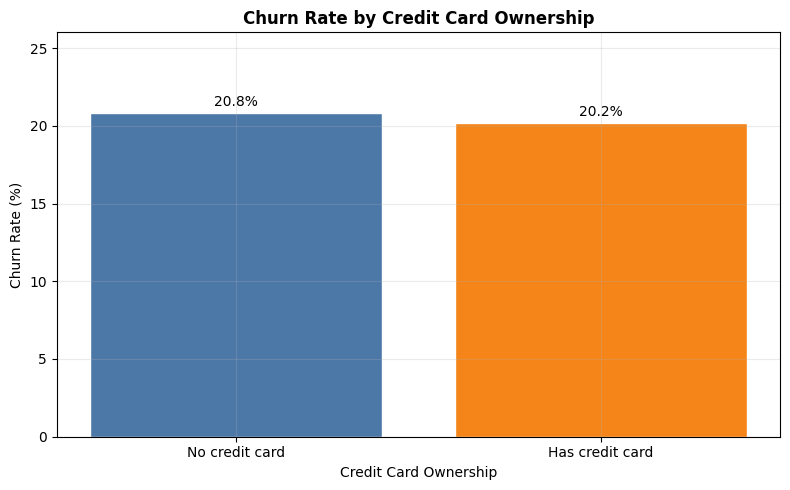

In [15]:
credit_card_churn = plot_churn_rate("HasCrCardLabel", "Churn Rate by Credit Card Ownership", "Credit Card Ownership", order=["No credit card", "Has credit card"])


**Business insight:** Tỷ lệ churn giữa khách hàng có thẻ tín dụng và không có thẻ tín dụng gần như tương đương nhau, lần lượt khoảng 20.18% và 20.81%. Điều này cho thấy riêng biến HasCrCard không phải là yếu tố phân biệt mạnh về churn. Biến này nên được phân tích kết hợp với các yếu tố khác như IsActiveMember, NumOfProducts, Balance và Tenure để có nhận định chính xác hơn.

,NumOfProducts,customer_count,churn_count,churn_rate_%
0,1,5084,1409,27.71
1,2,4590,348,7.58
2,3,266,220,82.71
3,4,60,60,100.00


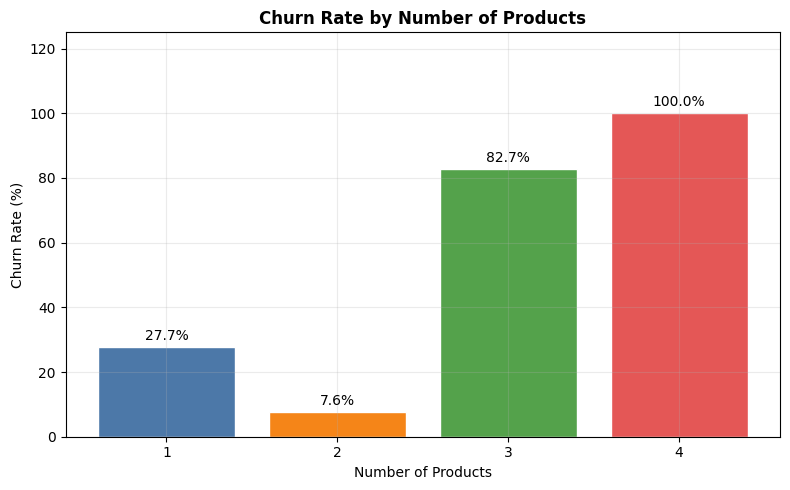

In [16]:
product_churn = plot_churn_rate("NumOfProducts", "Churn Rate by Number of Products", "Number of Products", order=sorted(eda_df["NumOfProducts"].dropna().unique()))


**Business insight:** Nhóm khách hàng sử dụng 2 sản phẩm có tỷ lệ churn thấp nhất, khoảng 7.58%, cho thấy mức độ sử dụng sản phẩm hợp lý có thể giúp tăng sự gắn bó. Tuy nhiên, nhóm dùng 3 sản phẩm có churn rate khoảng 82.71% và nhóm dùng 4 sản phẩm lên tới 100%, đây là dấu hiệu bất thường. Ngân hàng nên phân tích sâu hơn nhóm này vì có thể tồn tại vấn đề về phí, trải nghiệm phức tạp, sản phẩm không phù hợp hoặc cross-sell quá mức.


,AgeGroup,customer_count,churn_count,churn_rate_%
0,18-30,1968,148,7.52
1,31-40,4451,538,12.09
2,41-50,2320,788,33.97
3,51-60,797,448,56.21
4,60+,464,115,24.78


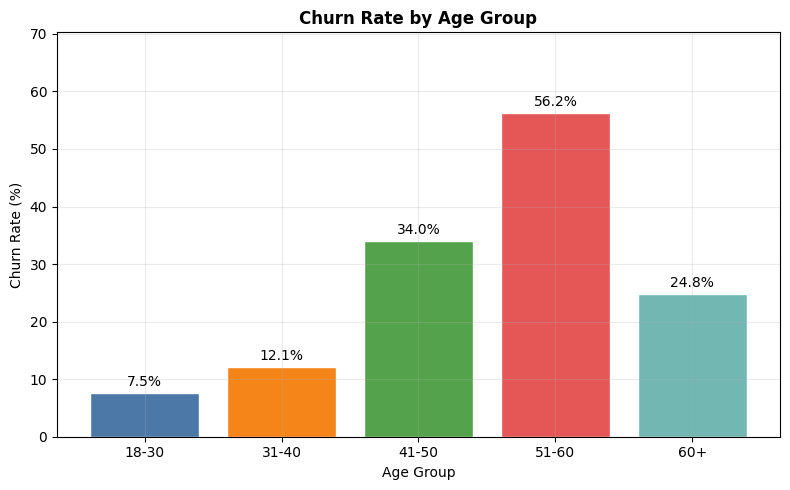

In [17]:
age_group_churn = plot_churn_rate("AgeGroup", "Churn Rate by Age Group", "Age Group", order=age_group_order)


**Business insight:** Tỷ lệ churn có xu hướng tăng rõ ở các nhóm tuổi lớn hơn. Nhóm 51–60 có churn rate cao nhất, khoảng 56.21%, cho thấy đây là nhóm khách hàng cần được chú ý. Về mặt kinh doanh, ngân hàng nên phân tích sâu hơn nhu cầu của khách hàng trung niên và lớn tuổi, đồng thời cân nhắc các chiến lược chăm sóc cá nhân hóa, tư vấn tài chính và cải thiện chất lượng hỗ trợ cho nhóm này.


,BalanceGroup,customer_count,churn_count,churn_rate_%
4,Zero balance,3617,500,13.82
1,Low balance,75,26,34.67
2,Medium balance,1509,300,19.88
0,High balance,3830,987,25.77
3,Very high balance,969,224,23.12


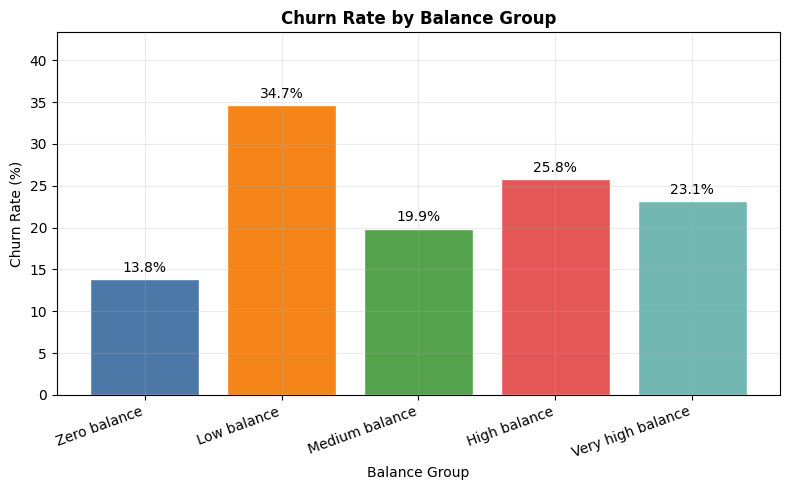

In [18]:
balance_group_churn = plot_churn_rate("BalanceGroup", "Churn Rate by Balance Group", "Balance Group", order=balance_group_order, rotation=20)


**Business insight:** Nhóm Low balance có tỷ lệ churn cao nhất, khoảng 34.67%, nhưng số lượng khách hàng trong nhóm này nhỏ nên cần diễn giải cẩn thận. Đáng chú ý hơn, nhóm High balance cũng có churn rate khá cao, khoảng 25.77%. Đây là nhóm khách hàng có giá trị tài chính lớn, vì vậy ngân hàng nên ưu tiên phân tích và chăm sóc nhóm này thông qua tư vấn cá nhân hóa, ưu đãi lãi suất hoặc dịch vụ hỗ trợ tốt hơn.

### 5.3 Numeric Feature Distributions by Exited


In [19]:
def display_numeric_distribution(column, title, xlabel):
    summary = (
        eda_df.groupby("ExitedLabel")[column]
        .agg(["count", "mean", "median", "std", "min", "max"])
        .reindex(exit_order)
        .round(2)
    )
    display(summary)

    grouped_values = [
        eda_df.loc[eda_df["ExitedLabel"].eq(label), column].dropna()
        for label in exit_order
    ]

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    for label, values, color in zip(exit_order, grouped_values, chart_colors[:2]):
        axes[0].hist(
            values,
            bins=30,
            density=True,
            alpha=0.45,
            label=label,
            color=color,
            edgecolor="white",
        )
    axes[0].set_title(f"{title} Distribution by Exited")
    axes[0].set_xlabel(xlabel)
    axes[0].set_ylabel("Density")
    axes[0].legend(title="Customer Status")

    box = axes[1].boxplot(
        grouped_values,
        labels=exit_order,
        patch_artist=True,
        medianprops={"color": "black"},
    )
    for patch, color in zip(box["boxes"], chart_colors[:2]):
        patch.set_facecolor(color)
        patch.set_alpha(0.65)
    axes[1].set_title(f"{title} Boxplot by Exited")
    axes[1].set_xlabel("Customer Status")
    axes[1].set_ylabel(xlabel)

    plt.tight_layout()
    plt.show()

    return summary


,count,mean,median,std,min,max
ExitedLabel,,,,,,
Did not churn,7963,37.41,36.0,10.13,18,92
Churned,2037,44.84,45.0,9.76,18,84


C:\Users\admin\AppData\Local\Temp\ipykernel_13540\3439841589.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = axes[1].boxplot(


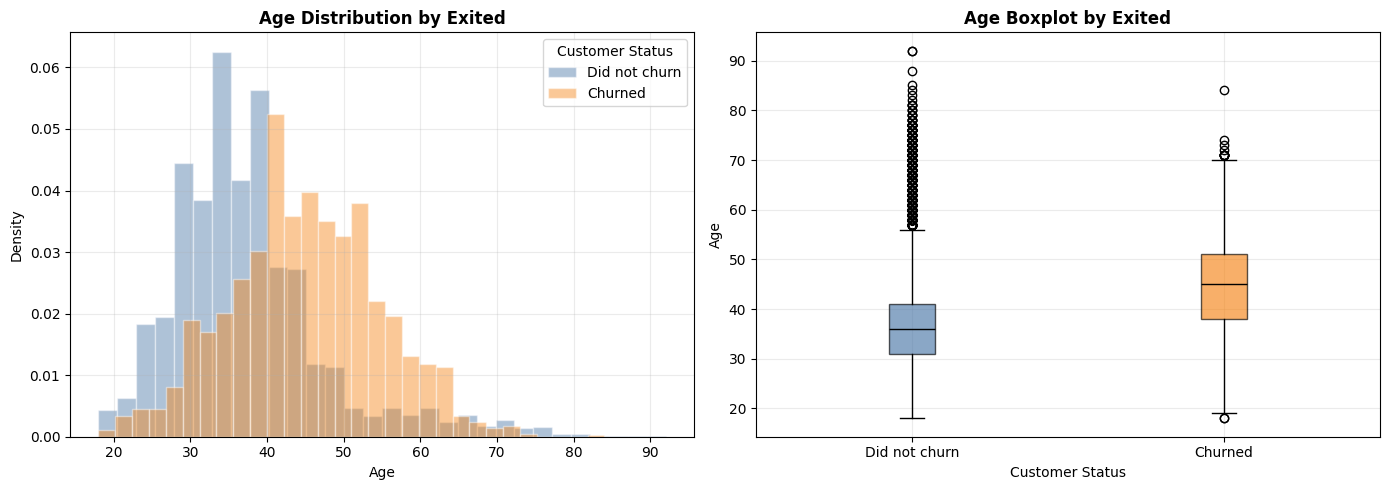

In [20]:
age_by_exited = display_numeric_distribution("Age", "Age", "Age")


**Business insight:** Khách hàng churn có xu hướng lớn tuổi hơn khách hàng không churn. Tuổi trung bình của nhóm churn khoảng 44.84, cao hơn nhóm không churn khoảng 37.41. Điều này cho thấy Age là một biến quan trọng trong phân tích churn. Ngân hàng nên chú ý hơn đến nhóm khách hàng trung niên và lớn tuổi, vì họ có thể cần dịch vụ hỗ trợ cá nhân hóa, tư vấn tài chính hoặc chính sách chăm sóc phù hợp hơn.


,count,mean,median,std,min,max
ExitedLabel,,,,,,
Did not churn,7963,5.03,5.0,2.88,0,10
Churned,2037,4.93,5.0,2.94,0,10


C:\Users\admin\AppData\Local\Temp\ipykernel_13540\3439841589.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = axes[1].boxplot(


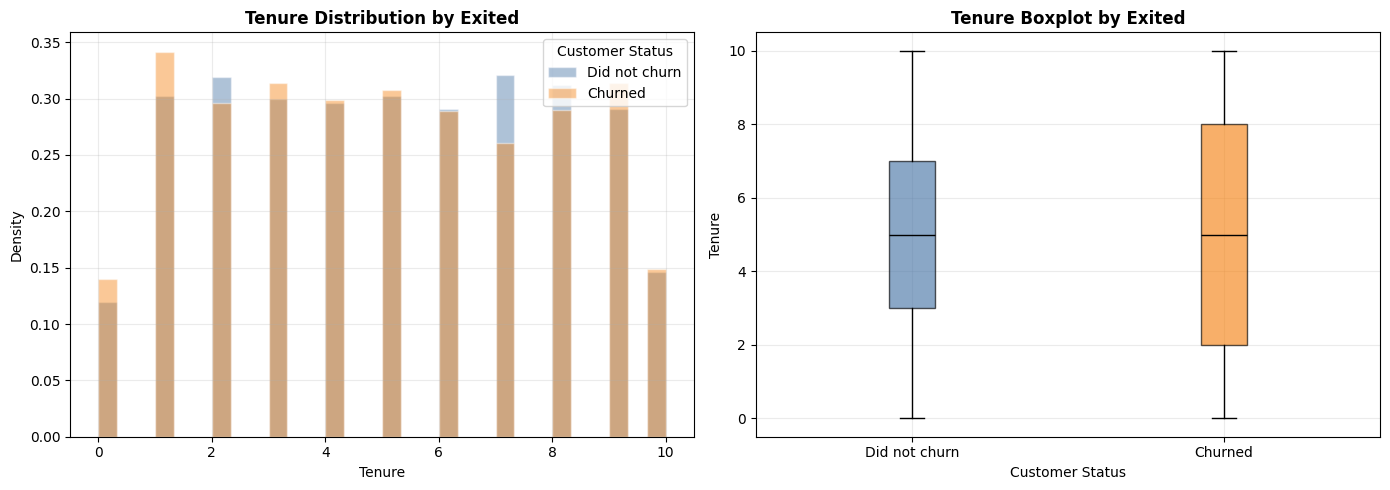

In [21]:
tenure_by_exited = display_numeric_distribution("Tenure", "Tenure", "Tenure")


**Business insight:** Tenure không cho thấy sự khác biệt rõ rệt giữa nhóm churn và không churn. Tenure trung bình của nhóm không churn khoảng 5.03 năm, còn nhóm churn khoảng 4.93 năm, gần như tương đương nhau. Điều này cho thấy thời gian gắn bó với ngân hàng không đủ để giải thích churn nếu xét riêng lẻ, và nên được phân tích cùng các biến khác như IsActiveMember, NumOfProducts, Balance và Age.

,count,mean,median,std,min,max
ExitedLabel,,,,,,
Did not churn,7963,72745.30,92072.68,62848.04,0.0,221532.80
Churned,2037,91108.54,109349.29,58360.79,0.0,250898.09


C:\Users\admin\AppData\Local\Temp\ipykernel_13540\3439841589.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = axes[1].boxplot(


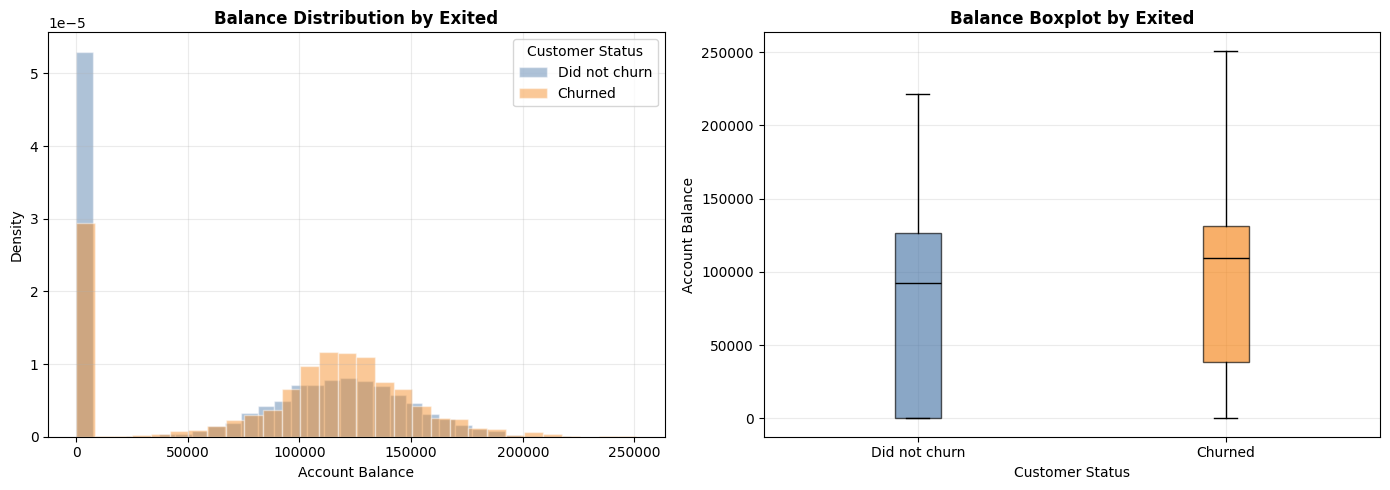

In [22]:
balance_by_exited = display_numeric_distribution("Balance", "Balance", "Account Balance")


**Business insight:** Nhóm khách hàng churn có số dư tài khoản trung bình cao hơn nhóm không churn, khoảng 91,108.54 so với 72,745.30. Điều này cho thấy ngân hàng có thể đang mất một số khách hàng có giá trị tài chính cao. Vì vậy, nhóm khách hàng có balance cao cần được chú ý hơn thông qua các chiến lược như chăm sóc cá nhân hóa, ưu đãi lãi suất, tư vấn tài chính hoặc dịch vụ hỗ trợ ưu tiên.

,count,mean,median,std,min,max
ExitedLabel,,,,,,
Did not churn,7963,99738.39,99645.04,57405.59,90.07,199992.48
Churned,2037,101465.68,102460.84,57912.42,11.58,199808.10


C:\Users\admin\AppData\Local\Temp\ipykernel_13540\3439841589.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = axes[1].boxplot(


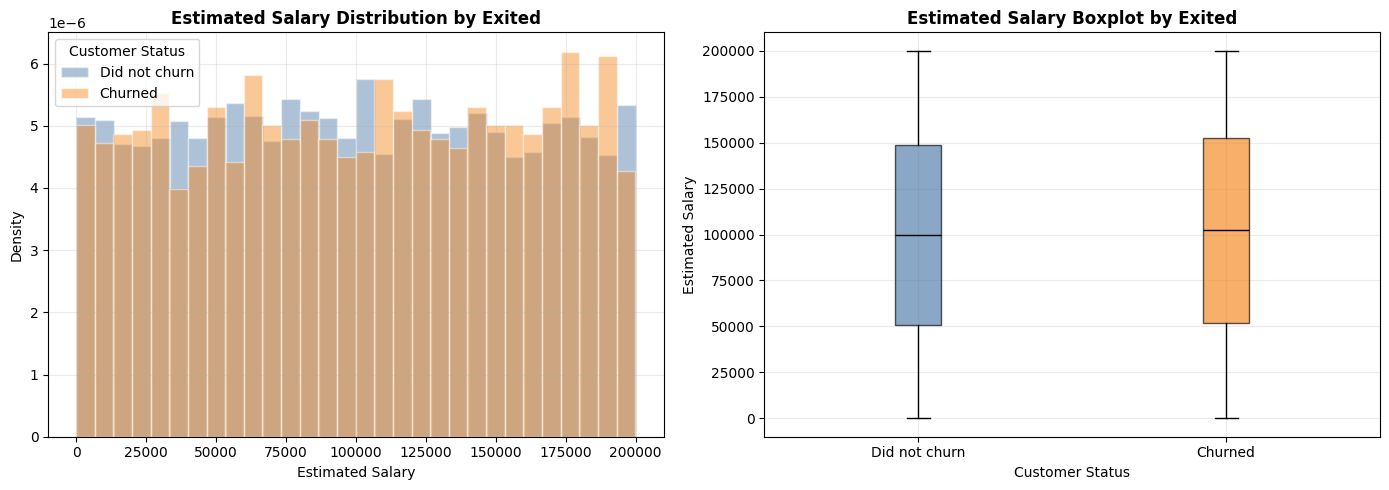

In [23]:
estimated_salary_by_exited = display_numeric_distribution("EstimatedSalary", "Estimated Salary", "Estimated Salary")


**Business insight:** EstimatedSalary không cho thấy sự khác biệt rõ rệt giữa nhóm churn và không churn. Mức lương ước tính trung bình của nhóm churn khoảng 101,465.68, chỉ cao hơn nhẹ so với nhóm không churn khoảng 99,738.39. Điều này cho thấy EstimatedSalary không phải là yếu tố phân biệt mạnh nếu xét riêng lẻ, nhưng vẫn có thể hữu ích khi kết hợp với Balance hoặc các biến tỷ lệ như BalanceSalaryRatio.


,count,mean,median,std,min,max
ExitedLabel,,,,,,
Did not churn,7963,651.85,653.0,95.65,405,850
Churned,2037,645.35,646.0,100.32,350,850


C:\Users\admin\AppData\Local\Temp\ipykernel_13540\3439841589.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = axes[1].boxplot(


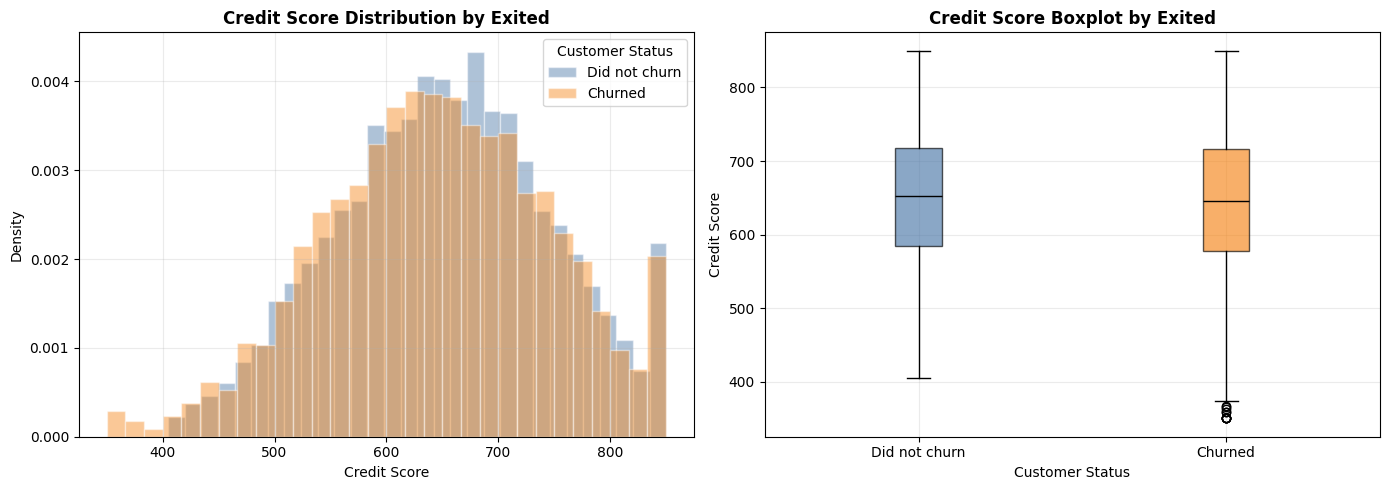

In [24]:
credit_score_by_exited = display_numeric_distribution("CreditScore", "Credit Score", "Credit Score")


**Business insight:** CreditScore của nhóm churn thấp hơn nhẹ so với nhóm không churn, với điểm trung bình khoảng 645.35 so với 651.85. Tuy nhiên, mức chênh lệch này không lớn, nên CreditScore không phải là yếu tố phân biệt mạnh nếu xét riêng lẻ. Biến này nên được phân tích kết hợp với các yếu tố khác như IsActiveMember, NumOfProducts, Age, Balance và Geography.

### 5.4 Correlation Heatmap for Numeric Columns


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
RowNumber,1.000,0.004,0.006,0.001,-0.006,-0.009,0.007,0.001,0.012,-0.006,-0.017
CustomerId,0.004,1.000,0.005,0.009,-0.015,-0.012,0.017,-0.014,0.002,0.015,-0.006
CreditScore,0.006,0.005,1.000,-0.004,0.001,0.006,0.012,-0.005,0.026,-0.001,-0.027
Age,0.001,0.009,-0.004,1.000,-0.010,0.028,-0.031,-0.012,0.085,-0.007,0.285
Tenure,-0.006,-0.015,0.001,-0.010,1.000,-0.012,0.013,0.023,-0.028,0.008,-0.014
Balance,-0.009,-0.012,0.006,0.028,-0.012,1.000,-0.304,-0.015,-0.010,0.013,0.119
NumOfProducts,0.007,0.017,0.012,-0.031,0.013,-0.304,1.000,0.003,0.010,0.014,-0.048
HasCrCard,0.001,-0.014,-0.005,-0.012,0.023,-0.015,0.003,1.000,-0.012,-0.010,-0.007
IsActiveMember,0.012,0.002,0.026,0.085,-0.028,-0.010,0.010,-0.012,1.000,-0.011,-0.156
EstimatedSalary,-0.006,0.015,-0.001,-0.007,0.008,0.013,0.014,-0.010,-0.011,1.000,0.012


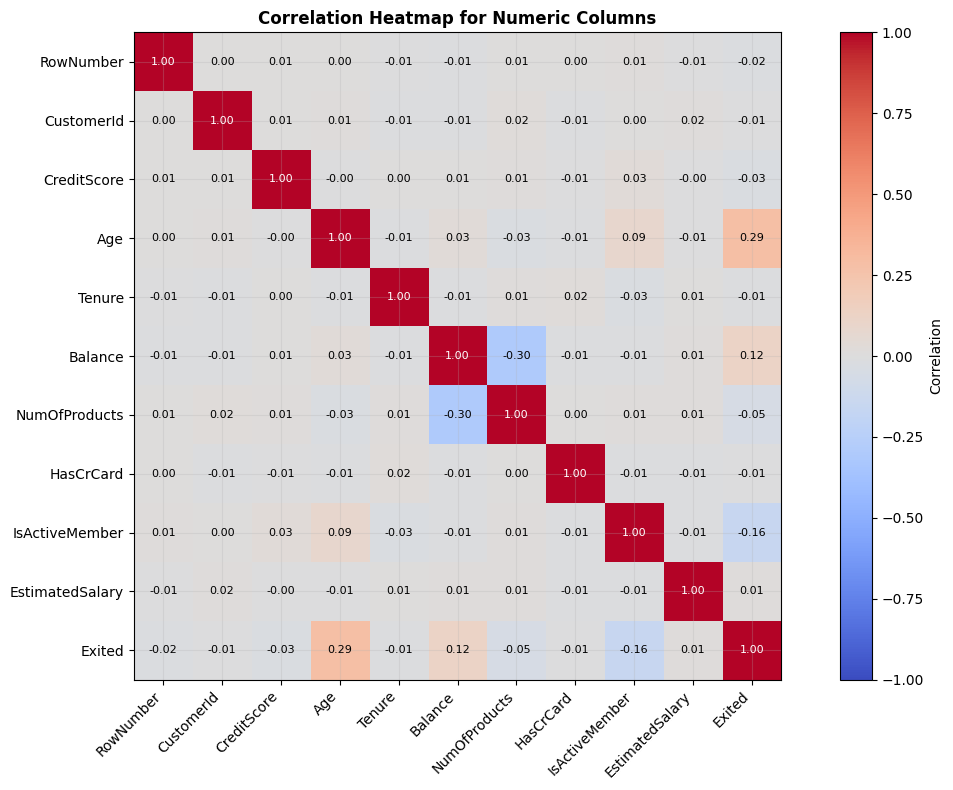

In [25]:
numeric_columns = eda_df.select_dtypes(include=np.number).columns
correlation_matrix = eda_df[numeric_columns].corr()

display(correlation_matrix.round(3))

fig, ax = plt.subplots(figsize=(12, 8))
heatmap = ax.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_title("Correlation Heatmap for Numeric Columns")
ax.set_xticks(range(len(numeric_columns)))
ax.set_yticks(range(len(numeric_columns)))
ax.set_xticklabels(numeric_columns, rotation=45, ha="right")
ax.set_yticklabels(numeric_columns)

for row in range(len(numeric_columns)):
    for col in range(len(numeric_columns)):
        value = correlation_matrix.iloc[row, col]
        text_color = "white" if abs(value) >= 0.55 else "black"
        ax.text(col, row, f"{value:.2f}", ha="center", va="center", color=text_color, fontsize=8)

colorbar = fig.colorbar(heatmap, ax=ax)
colorbar.set_label("Correlation")
plt.tight_layout()
plt.show()


**Business insight:** Correlation heatmap cho thấy Age, Balance và IsActiveMember là các biến có mối liên hệ đáng chú ý hơn với Exited. Age và Balance có tương quan dương với churn, trong khi IsActiveMember có tương quan âm, nghĩa là khách hàng active có xu hướng churn thấp hơn. Các biến như Tenure, EstimatedSalary và CreditScore có tương quan yếu hơn. Tuy nhiên, correlation chỉ phản ánh quan hệ tuyến tính và không chứng minh nguyên nhân, nên kết quả này cần được kết hợp với các phân tích EDA khác.

## 5. Data Cleaning and Feature Engineering

This section creates the working dataset `processed_df` from the raw dataframe `df`. It removes technical identifiers that do not describe churn behavior, preserves `CustomerId` for later retention tracking, handles basic data quality issues, and creates customer behavior features for later modeling and explainability.


### 5.1 Data Cleaning

The cleaning step copies the raw dataset, removes fully duplicated records, handles missing values if present, standardizes the target type, and removes non-informative columns. No train-test split, resampling, or model fitting is performed in this section.


In [26]:
import pandas as pd
import numpy as np

DATASET_PATH = r"D:\FPT University\Coding\DSP\data\Churn_Modelling.csv"

if "df" not in globals():
    df = pd.read_csv(DATASET_PATH)
    print(f"df was not available in memory, so it was loaded from: {DATASET_PATH}")

processed_df = df.copy()
initial_shape = processed_df.shape
initial_duplicate_rows = int(processed_df.duplicated().sum())

if initial_duplicate_rows > 0:
    processed_df = processed_df.drop_duplicates().reset_index(drop=True)

target_column = "Exited"
if target_column not in processed_df.columns:
    raise KeyError(f"Required target column '{target_column}' was not found in the dataset.")

missing_target_rows = int(processed_df[target_column].isna().sum())
if missing_target_rows > 0:
    processed_df = processed_df.dropna(subset=[target_column]).reset_index(drop=True)

numeric_missing_columns = [
    column for column in processed_df.select_dtypes(include=[np.number]).columns
    if column != target_column and processed_df[column].isna().any()
]

for column in numeric_missing_columns:
    median_value = processed_df[column].median()
    fill_value = 0 if pd.isna(median_value) else median_value
    processed_df[column] = processed_df[column].fillna(fill_value)

categorical_missing_columns = [
    column for column in processed_df.select_dtypes(include=["object", "category", "string"]).columns
    if processed_df[column].isna().any()
]

for column in categorical_missing_columns:
    mode_values = processed_df[column].mode(dropna=True)
    fill_value = mode_values.iloc[0] if not mode_values.empty else "Unknown"
    processed_df[column] = processed_df[column].fillna(fill_value)

processed_df[target_column] = processed_df[target_column].astype(int)

# Preserve CustomerId for later retention tracking, but remove fields that are not useful for modeling.
identifier_columns_not_for_modeling = ["RowNumber", "CustomerId", "Surname"]
columns_removed_from_processed_df = [
    column for column in ["RowNumber", "Surname"] if column in processed_df.columns
]
processed_df = processed_df.drop(columns=columns_removed_from_processed_df, errors="ignore")

print("Data cleaning completed.")
print(f"Initial shape: {initial_shape}")
print(f"Duplicate rows removed: {initial_duplicate_rows}")
print(f"Rows removed because target was missing: {missing_target_rows}")
print(f"Numeric columns imputed: {numeric_missing_columns if numeric_missing_columns else 'None'}")
print(f"Categorical columns imputed: {categorical_missing_columns if categorical_missing_columns else 'None'}")
print(f"Columns removed from processed_df: {columns_removed_from_processed_df if columns_removed_from_processed_df else 'None'}")
print(f"CustomerId preserved: {'CustomerId' in processed_df.columns}")
print(f"Columns excluded from model features later: {identifier_columns_not_for_modeling}")


Data cleaning completed.
Initial shape: (10000, 14)
Duplicate rows removed: 0
Rows removed because target was missing: 0
Numeric columns imputed: None
Categorical columns imputed: None
Columns removed from processed_df: ['RowNumber', 'Surname']
CustomerId preserved: True
Columns excluded from model features later: ['RowNumber', 'CustomerId', 'Surname']


### 5.2 Feature Engineering

The engineered features below are calculated row by row from existing customer attributes. They do not use the target variable or future modeling outputs.


In [27]:
required_feature_columns = [
    "Balance", "EstimatedSalary", "CreditScore", "Age", "Tenure", "NumOfProducts",
]
missing_feature_columns = [column for column in required_feature_columns if column not in processed_df.columns]
if missing_feature_columns:
    raise KeyError(f"Missing required columns for feature engineering: {missing_feature_columns}")

numeric_engineered_features = [
    "BalanceSalaryRatio",
    "CreditScoreAgeRatio",
    "TenureAgeRatio",
    "IsZeroBalance",
    "ProductsPerTenure",
]

categorical_engineered_features = [
    "AgeGroup",
    "BalanceGroup",
]

engineered_features = numeric_engineered_features + categorical_engineered_features

processed_df["BalanceSalaryRatio"] = processed_df["Balance"] / (processed_df["EstimatedSalary"] + 1)
upper_limit = processed_df["BalanceSalaryRatio"].quantile(0.99)
processed_df["BalanceSalaryRatio"] = processed_df["BalanceSalaryRatio"].clip(upper=upper_limit)

processed_df["CreditScoreAgeRatio"] = processed_df["CreditScore"] / (processed_df["Age"] + 1)
processed_df["TenureAgeRatio"] = processed_df["Tenure"] / (processed_df["Age"] + 1)
processed_df["IsZeroBalance"] = np.where(processed_df["Balance"].eq(0), 1, 0)
processed_df["ProductsPerTenure"] = processed_df["NumOfProducts"] / (processed_df["Tenure"] + 1)

age_group_order = ["18-30", "31-40", "41-50", "51-60", "60+"]
processed_df["AgeGroup"] = pd.cut(
    processed_df["Age"],
    bins=[0, 30, 40, 50, 60, np.inf],
    labels=age_group_order,
    include_lowest=True,
)

balance_group_order = [
    "Zero balance", "Low balance", "Medium balance", "High balance", "Very high balance",
]
non_zero_balance_labels = ["Low balance", "Medium balance", "High balance", "Very high balance"]
processed_df["BalanceGroup"] = "Zero balance"

non_zero_balance_mask = processed_df["Balance"].gt(0)
non_zero_balance = processed_df.loc[non_zero_balance_mask, "Balance"]

if not non_zero_balance.empty:
    if non_zero_balance.nunique(dropna=True) >= 2:
        try:
            quantile_count = min(4, non_zero_balance.nunique(dropna=True))
            quantile_codes = pd.qcut(
                non_zero_balance,
                q=quantile_count,
                labels=False,
                duplicates="drop",
            )
            processed_df.loc[non_zero_balance_mask, "BalanceGroup"] = quantile_codes.map(
                lambda bin_code: non_zero_balance_labels[int(bin_code)]
                if pd.notna(bin_code) else "Low balance"
            ).to_numpy()
        except ValueError:
            processed_df.loc[non_zero_balance_mask, "BalanceGroup"] = "Low balance"
    else:
        processed_df.loc[non_zero_balance_mask, "BalanceGroup"] = "Low balance"

processed_df["BalanceGroup"] = pd.Categorical(
    processed_df["BalanceGroup"],
    categories=balance_group_order,
    ordered=True,
)

# Compatibility aliases for existing downstream export and scaffold cells.
df_fe = processed_df.copy()
df_processed = processed_df.copy()

processed_total_missing_values = int(processed_df.isna().sum().sum())
processed_duplicate_rows = int(processed_df.duplicated().sum())
engineered_infinite_summary = pd.DataFrame({
    "infinite_count": np.isinf(processed_df[numeric_engineered_features].to_numpy(dtype=float)).sum(axis=0),
}, index=numeric_engineered_features)

print("processed_df.shape:")
print(processed_df.shape)

print("\nprocessed_df.head():")
display(processed_df.head())

print("\nprocessed_df.dtypes:")
display(processed_df.dtypes.to_frame("data_type"))

print("\nTotal missing values in processed_df:")
print(processed_total_missing_values)

print("\nDuplicate rows in processed_df:")
print(processed_duplicate_rows)

print("\nNew engineered features:")
print(engineered_features)

print("\nSummary statistics for engineered numerical features:")
display(processed_df[numeric_engineered_features].describe().T.round(4))

print("\nInfinite values in engineered numerical features:")
display(engineered_infinite_summary)

print("\nAgeGroup value counts:")
display(processed_df["AgeGroup"].value_counts(dropna=False).sort_index().to_frame("count"))

print("\nBalanceGroup value counts:")
display(processed_df["BalanceGroup"].value_counts(dropna=False).sort_index().to_frame("count"))

assert processed_total_missing_values == 0, "processed_df still contains missing values."
assert processed_duplicate_rows == 0, "processed_df still contains duplicate rows."
assert engineered_infinite_summary["infinite_count"].sum() == 0, "Engineered features contain infinite values."
print("\nData cleaning and feature engineering validation passed.")


processed_df.shape:
(10000, 19)

processed_df.head():


,CustomerId,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,BalanceSalaryRatio,CreditScoreAgeRatio,TenureAgeRatio,IsZeroBalance,ProductsPerTenure,AgeGroup,BalanceGroup
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1,0.000000,14.395349,0.046512,1,0.333333,41-50,Zero balance
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,0.744670,14.476190,0.023810,0,0.500000,41-50,Low balance
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1.401362,11.674419,0.186047,0,0.333333,41-50,Very high balance
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0.000000,17.475000,0.025000,1,1.000000,31-40,Zero balance
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,1.587035,19.318182,0.045455,0,0.333333,41-50,High balance



processed_df.dtypes:


,data_type
CustomerId,int64
CreditScore,int64
Geography,object
Gender,object
Age,int64
Tenure,int64
Balance,float64
NumOfProducts,int64
HasCrCard,int64
IsActiveMember,int64



Total missing values in processed_df:
0

Duplicate rows in processed_df:
0

New engineered features:
['BalanceSalaryRatio', 'CreditScoreAgeRatio', 'TenureAgeRatio', 'IsZeroBalance', 'ProductsPerTenure', 'AgeGroup', 'BalanceGroup']

Summary statistics for engineered numerical features:


...


AgeGroup value counts:


,count
AgeGroup,
18-30,1968
31-40,4451
41-50,2320
51-60,797
60+,464



BalanceGroup value counts:


,count
BalanceGroup,
Zero balance,3617
Low balance,1596
Medium balance,1596
High balance,1595
Very high balance,1596



Data cleaning and feature engineering validation passed.


Feature engineering creates additional customer behavior and financial ratio variables.

- `BalanceSalaryRatio` is clipped at the 99th percentile to reduce the effect of extreme outliers caused by very low `EstimatedSalary`.
- `CustomerId` is preserved only for later retention tracking and must not be used as a model feature.
- `RowNumber` and `Surname` are removed because they are identifiers and do not represent useful churn behavior.


## 6. Processed Dataset Export

This section saves the cleaned and feature-engineered dataset for the later modeling phase. The exported file keeps `CustomerId` for retention tracking, keeps useful churn predictors and engineered features, and excludes technical identifier fields that should not be used for modeling.


The processed dataset has been saved as `churn_processed_data.csv` and will be used for modeling. `CustomerId` is kept only for tracking customers in retention outputs and must not be used as a model feature.


### Exported Modeling Assets


In [28]:
import pathlib
import pandas as pd
import numpy as np

RAW_DATASET_PATH = r"D:\FPT University\Coding\DSP\data\Churn_Modelling.csv"
PROCESSED_DATASET_PATH = r"D:\FPT University\Coding\DSP\churn_processed_data.csv"

numeric_engineered_features = [
    "BalanceSalaryRatio",
    "CreditScoreAgeRatio",
    "TenureAgeRatio",
    "IsZeroBalance",
    "ProductsPerTenure",
]

categorical_engineered_features = [
    "AgeGroup",
    "BalanceGroup",
]

engineered_features = numeric_engineered_features + categorical_engineered_features
age_group_order = ["18-30", "31-40", "41-50", "51-60", "60+"]
balance_group_order = [
    "Zero balance", "Low balance", "Medium balance", "High balance", "Very high balance",
]


def recreate_processed_dataframe():
    recreated_df = pd.read_csv(RAW_DATASET_PATH)
    recreated_df = recreated_df.copy()

    duplicate_rows = int(recreated_df.duplicated().sum())
    if duplicate_rows > 0:
        recreated_df = recreated_df.drop_duplicates().reset_index(drop=True)

    target_column = "Exited"
    if target_column not in recreated_df.columns:
        raise KeyError(f"Required target column '{target_column}' was not found in the raw dataset.")

    if recreated_df[target_column].isna().any():
        recreated_df = recreated_df.dropna(subset=[target_column]).reset_index(drop=True)

    numeric_missing_columns = [
        column for column in recreated_df.select_dtypes(include=[np.number]).columns
        if column != target_column and recreated_df[column].isna().any()
    ]
    for column in numeric_missing_columns:
        median_value = recreated_df[column].median()
        fill_value = 0 if pd.isna(median_value) else median_value
        recreated_df[column] = recreated_df[column].fillna(fill_value)

    categorical_missing_columns = [
        column for column in recreated_df.select_dtypes(include=["object", "category", "string"]).columns
        if recreated_df[column].isna().any()
    ]
    for column in categorical_missing_columns:
        mode_values = recreated_df[column].mode(dropna=True)
        fill_value = mode_values.iloc[0] if not mode_values.empty else "Unknown"
        recreated_df[column] = recreated_df[column].fillna(fill_value)

    recreated_df[target_column] = recreated_df[target_column].astype(int)
    recreated_df = recreated_df.drop(columns=["RowNumber", "Surname"], errors="ignore")

    recreated_df["BalanceSalaryRatio"] = recreated_df["Balance"] / (recreated_df["EstimatedSalary"] + 1)
    upper_limit = recreated_df["BalanceSalaryRatio"].quantile(0.99)
    recreated_df["BalanceSalaryRatio"] = recreated_df["BalanceSalaryRatio"].clip(upper=upper_limit)
    recreated_df["CreditScoreAgeRatio"] = recreated_df["CreditScore"] / (recreated_df["Age"] + 1)
    recreated_df["TenureAgeRatio"] = recreated_df["Tenure"] / (recreated_df["Age"] + 1)
    recreated_df["IsZeroBalance"] = np.where(recreated_df["Balance"].eq(0), 1, 0)
    recreated_df["ProductsPerTenure"] = recreated_df["NumOfProducts"] / (recreated_df["Tenure"] + 1)

    recreated_df["AgeGroup"] = pd.cut(
        recreated_df["Age"],
        bins=[0, 30, 40, 50, 60, np.inf],
        labels=age_group_order,
        include_lowest=True,
    )

    non_zero_balance_labels = ["Low balance", "Medium balance", "High balance", "Very high balance"]
    recreated_df["BalanceGroup"] = "Zero balance"
    non_zero_balance_mask = recreated_df["Balance"].gt(0)
    non_zero_balance = recreated_df.loc[non_zero_balance_mask, "Balance"]

    if not non_zero_balance.empty:
        if non_zero_balance.nunique(dropna=True) >= 2:
            try:
                quantile_count = min(4, non_zero_balance.nunique(dropna=True))
                quantile_codes = pd.qcut(
                    non_zero_balance,
                    q=quantile_count,
                    labels=False,
                    duplicates="drop",
                )
                recreated_df.loc[non_zero_balance_mask, "BalanceGroup"] = quantile_codes.map(
                    lambda bin_code: non_zero_balance_labels[int(bin_code)]
                    if pd.notna(bin_code) else "Low balance"
                ).to_numpy()
            except ValueError:
                recreated_df.loc[non_zero_balance_mask, "BalanceGroup"] = "Low balance"
        else:
            recreated_df.loc[non_zero_balance_mask, "BalanceGroup"] = "Low balance"

    recreated_df["BalanceGroup"] = pd.Categorical(
        recreated_df["BalanceGroup"],
        categories=balance_group_order,
        ordered=True,
    )

    return recreated_df


if "processed_df" in globals():
    export_df = processed_df.copy()
elif "df_processed" in globals():
    export_df = df_processed.copy()
elif "df_fe" in globals():
    export_df = df_fe.copy()
else:
    export_df = recreate_processed_dataframe()

export_df = export_df.drop(columns=["RowNumber", "Surname"], errors="ignore").copy()

missing_engineered_features = [feature for feature in engineered_features if feature not in export_df.columns]
if missing_engineered_features:
    export_df = recreate_processed_dataframe()

preferred_column_order = [
    "CustomerId",
    "CreditScore",
    "Geography",
    "Gender",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "HasCrCard",
    "IsActiveMember",
    "EstimatedSalary",
    *engineered_features,
    "Exited",
]

export_columns = [column for column in preferred_column_order if column in export_df.columns]
remaining_columns = [
    column for column in export_df.columns
    if column not in export_columns and column not in ["RowNumber", "Surname"]
]
if "Exited" in export_columns:
    export_columns = [column for column in export_columns if column != "Exited"] + remaining_columns + ["Exited"]
else:
    export_columns = export_columns + remaining_columns

export_df = export_df[export_columns].copy()

processed_data_path = pathlib.Path(PROCESSED_DATASET_PATH)
outputs_dir = processed_data_path.parent
outputs_dir.mkdir(parents=True, exist_ok=True)

export_df.to_csv(processed_data_path, index=False)

# Reload the processed dataset from disk so later notebook cells use the saved artifact.
processed_df = pd.read_csv(r"D:\FPT University\Coding\DSP\churn_processed_data.csv")
df_processed = processed_df.copy()
df_fe = processed_df.copy()

print("1. Saved file path:")
print(str(processed_data_path.resolve()))

print("\n2. processed_df.shape:")
print(processed_df.shape)

print("\n3. processed_df.head():")
display(processed_df.head())

print("\n4. Total missing values:")
print(int(processed_df.isna().sum().sum()))

print("\n5. Duplicate rows:")
print(int(processed_df.duplicated().sum()))

print("\n6. processed_df['Exited'].value_counts():")
display(processed_df["Exited"].value_counts().sort_index().to_frame("count"))

print("\n7. processed_df['Exited'].value_counts(normalize=True):")
display(processed_df["Exited"].value_counts(normalize=True).sort_index().to_frame("percentage"))

print("\n8. processed_df.columns.tolist():")
print(processed_df.columns.tolist())


1. Saved file path:
D:\FPT University\Coding\DSP\churn_processed_data.csv

2. processed_df.shape:
(10000, 19)

3. processed_df.head():


,CustomerId,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,BalanceSalaryRatio,CreditScoreAgeRatio,TenureAgeRatio,IsZeroBalance,ProductsPerTenure,AgeGroup,BalanceGroup,Exited
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,0.000000,14.395349,0.046512,1,0.333333,41-50,Zero balance,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0.744670,14.476190,0.023810,0,0.500000,41-50,Low balance,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1.401362,11.674419,0.186047,0,0.333333,41-50,Very high balance,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0.000000,17.475000,0.025000,1,1.000000,31-40,Zero balance,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,1.587035,19.318182,0.045455,0,0.333333,41-50,High balance,0



4. Total missing values:
0

5. Duplicate rows:
0

6. processed_df['Exited'].value_counts():


,count
Exited,
0,7963
1,2037



7. processed_df['Exited'].value_counts(normalize=True):


,percentage
Exited,
0,0.7963
1,0.2037



8. processed_df.columns.tolist():
['CustomerId', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'BalanceSalaryRatio', 'CreditScoreAgeRatio', 'TenureAgeRatio', 'IsZeroBalance', 'ProductsPerTenure', 'AgeGroup', 'BalanceGroup', 'Exited']


In [29]:
description_map = {
    "CustomerId": "Unique customer identifier kept for customer-level tracking.",
    "CreditScore": "Customer credit score.",
    "Geography": "Customer country or region.",
    "Gender": "Customer gender.",
    "Age": "Customer age in years.",
    "Tenure": "Number of years the customer has stayed with the bank.",
    "Balance": "Customer account balance.",
    "NumOfProducts": "Number of bank products used by the customer.",
    "HasCrCard": "Whether the customer has a credit card: 1=yes, 0=no.",
    "IsActiveMember": "Whether the customer is an active member: 1=yes, 0=no.",
    "EstimatedSalary": "Estimated customer salary.",
    "Exited": "Target variable: 1=customer churned, 0=customer did not churn.",
    "BalanceSalaryRatio": "Engineered ratio of balance to estimated salary plus one.",
    "CreditScoreAgeRatio": "Engineered ratio of credit score to age.",
    "TenureAgeRatio": "Engineered ratio of tenure to age.",
    "IsZeroBalance": "Engineered flag: 1 if balance equals zero, otherwise 0.",
    "ProductsPerTenure": "Engineered ratio of number of products to tenure plus one.",
    "AgeGroup": "Engineered age segment.",
    "BalanceGroup": "Engineered balance segment.",
}

binary_features = {"HasCrCard", "IsActiveMember", "IsZeroBalance"}
original_categorical_features = {"Geography", "Gender"}

def infer_column_role(column):
    if column == "CustomerId":
        return "Identifier"
    if column == "Exited":
        return "Target"
    if column in numeric_engineered_features:
        return "Engineered Numeric Feature"
    if column in categorical_engineered_features:
        return "Engineered Categorical Feature"
    if column in binary_features:
        return "Binary Feature"
    if column in original_categorical_features:
        return "Categorical Feature"
    if pd.api.types.is_numeric_dtype(df_processed[column]):
        return "Numeric Feature"
    return "Feature"


data_dictionary = pd.DataFrame([
    {
        "ColumnName": column,
        "DataType": str(df_processed[column].dtype),
        "Role": infer_column_role(column),
        "Description": description_map.get(column, "Processed dataset column."),
    }
    for column in df_processed.columns
])

data_dictionary_path = outputs_dir / "data_dictionary.csv"
data_dictionary.to_csv(data_dictionary_path, index=False)

print(f"Data dictionary saved to: {data_dictionary_path.resolve()}")
display(data_dictionary)


Data dictionary saved to: D:\FPT University\Coding\DSP\data_dictionary.csv


,ColumnName,DataType,Role,Description
0,CustomerId,int64,Identifier,Unique customer identifier kept for customer-l...
1,CreditScore,int64,Numeric Feature,Customer credit score.
2,Geography,object,Categorical Feature,Customer country or region.
3,Gender,object,Categorical Feature,Customer gender.
4,Age,int64,Numeric Feature,Customer age in years.
5,Tenure,int64,Numeric Feature,Number of years the customer has stayed with t...
6,Balance,float64,Numeric Feature,Customer account balance.
7,NumOfProducts,int64,Numeric Feature,Number of bank products used by the customer.
8,HasCrCard,int64,Binary Feature,"Whether the customer has a credit card: 1=yes,..."
9,IsActiveMember,int64,Binary Feature,Whether the customer is an active member: 1=ye...


In [30]:
def export_churn_summary(frame, column, summary_type):
    summary = (
        frame.groupby(column, dropna=False, observed=False)["Exited"]
        .agg(CustomerCount="count", ChurnCount="sum", ChurnRate="mean")
        .reset_index()
    )
    return pd.DataFrame({
        "SummaryType": summary_type,
        "Segment": summary[column].astype(str),
        "CustomerCount": summary["CustomerCount"].astype(int),
        "ChurnCount": summary["ChurnCount"].astype(int),
        "ChurnRatePercent": (summary["ChurnRate"] * 100).round(2),
    })

eda_summary_parts = [
    pd.DataFrame([
        {
            "SummaryType": "Overall",
            "Segment": "All customers",
            "CustomerCount": int(len(df_processed)),
            "ChurnCount": int(df_processed["Exited"].sum()),
            "ChurnRatePercent": round(float(df_processed["Exited"].mean() * 100), 2),
        }
    ]),
]

for column in [
    "Geography", "Gender", "IsActiveMember", "HasCrCard", "NumOfProducts", "AgeGroup", "BalanceGroup",
]:
    eda_summary_parts.append(export_churn_summary(df_processed, column, f"ChurnRateBy{column}"))

eda_summary = pd.concat(eda_summary_parts, ignore_index=True)

eda_summary_path = outputs_dir / "eda_summary.csv"
eda_summary.to_csv(eda_summary_path, index=False)

print(f"EDA summary saved to: {eda_summary_path.resolve()}")
display(eda_summary)


EDA summary saved to: D:\FPT University\Coding\DSP\eda_summary.csv


,SummaryType,Segment,CustomerCount,ChurnCount,ChurnRatePercent
0,Overall,All customers,10000,2037,20.37
1,ChurnRateByGeography,France,5014,810,16.15
2,ChurnRateByGeography,Germany,2509,814,32.44
3,ChurnRateByGeography,Spain,2477,413,16.67
4,ChurnRateByGender,Female,4543,1139,25.07
5,ChurnRateByGender,Male,5457,898,16.46
6,ChurnRateByIsActiveMember,0,4849,1302,26.85
7,ChurnRateByIsActiveMember,1,5151,735,14.27
8,ChurnRateByHasCrCard,0,2945,613,20.81
9,ChurnRateByHasCrCard,1,7055,1424,20.18


## 7. Train-Test Split

Train-test split is performed before any class imbalance handling to prevent data leakage. The test set keeps the original real-world churn distribution and will be used as the untouched holdout set for all models.


In [31]:
import pandas as pd
from sklearn.model_selection import train_test_split

if "RANDOM_STATE" not in globals():
    RANDOM_STATE = 42

PROCESSED_DATASET_PATH = r"D:\FPT University\Coding\DSP\churn_processed_data.csv"

if "processed_df" not in globals():
    processed_df = pd.read_csv(PROCESSED_DATASET_PATH)
    print(f"processed_df was loaded from: {PROCESSED_DATASET_PATH}")

target_column = "Exited"
columns_to_drop = ["Exited", "RowNumber", "Surname", "CustomerId"]

if target_column not in processed_df.columns:
    raise KeyError(f"Required target column '{target_column}' was not found in processed_df.")

y = processed_df[target_column].astype(int)
X = processed_df.drop(columns=columns_to_drop, errors="ignore").copy()

if "CustomerId" in processed_df.columns:
    customer_ids = processed_df["CustomerId"].copy()
else:
    customer_ids = None

if customer_ids is not None:
    (
        X_train_original,
        X_test,
        y_train_original,
        y_test,
        customer_id_train,
        customer_id_test,
    ) = train_test_split(
        X,
        y,
        customer_ids,
        test_size=0.2,
        random_state=RANDOM_STATE,
        stratify=y,
    )
else:
    X_train_original, X_test, y_train_original, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=RANDOM_STATE,
        stratify=y,
    )
    customer_id_train = None
    customer_id_test = None

# Compatibility aliases for downstream scaffold cells. These remain unresampled training data.
X_train = X_train_original
y_train = y_train_original


def print_target_distribution(label, target_series):
    counts = target_series.value_counts().sort_index()
    percentages = (target_series.value_counts(normalize=True).sort_index() * 100).round(2)
    churn_rate_value = float(target_series.mean())

    print(f"{label} class distribution:")
    print(counts)
    print(f"{label} class percentage:")
    print(percentages)
    print(f"{label} churn rate: {churn_rate_value:.4f} ({churn_rate_value * 100:.2f}%)")
    print()

print("Train-test split completed.")
print(f"X_train_original shape: {X_train_original.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train_original shape: {y_train_original.shape}")
print(f"y_test shape: {y_test.shape}")
print(f"CustomerId split available: {customer_id_train is not None and customer_id_test is not None}")
print()

print_target_distribution("Full dataset", y)
print_target_distribution("Training set", y_train_original)
print_target_distribution("Test set", y_test)


Train-test split completed.
X_train_original shape: (8000, 17)
X_test shape: (2000, 17)
y_train_original shape: (8000,)
y_test shape: (2000,)
CustomerId split available: True

Full dataset class distribution:
Exited
0    7963
1    2037
Name: count, dtype: int64
Full dataset class percentage:
Exited
0    79.63
1    20.37
Name: proportion, dtype: float64
Full dataset churn rate: 0.2037 (20.37%)

Training set class distribution:
Exited
0    6370
1    1630
Name: count, dtype: int64
Training set class percentage:
Exited
0    79.62
1    20.38
Name: proportion, dtype: float64
Training set churn rate: 0.2037 (20.38%)

Test set class distribution:
Exited
0    1593
1     407
Name: count, dtype: int64
Test set class percentage:
Exited
0    79.65
1    20.35
Name: proportion, dtype: float64
Test set churn rate: 0.2035 (20.35%)



### 7.1 Preprocessing Pipeline

The preprocessing pipeline is defined after the split using the training feature columns. It is not fitted in this section; it should be placed inside an sklearn `Pipeline` with a model during later training so preprocessing is learned only from the training data.


In [32]:
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

if "X_train_original" not in globals():
    raise NameError("Run the train-test split cell before creating the preprocessing pipeline.")

categorical_like_candidates = [
    "Geography",
    "Gender",
    "NumOfProducts",
    "HasCrCard",
    "IsActiveMember",
    "IsZeroBalance",
    "AgeGroup",
    "BalanceGroup",
]

continuous_numeric_candidates = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "EstimatedSalary",
    "BalanceSalaryRatio",
    "CreditScoreAgeRatio",
    "TenureAgeRatio",
    "ProductsPerTenure",
]

object_or_category_features = X_train_original.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

categorical_features = [
    column for column in X_train_original.columns
    if column in object_or_category_features or column in categorical_like_candidates
]

numeric_features = [
    column for column in continuous_numeric_candidates
    if column in X_train_original.columns and column not in categorical_features
]

additional_numeric_features = [
    column for column in X_train_original.select_dtypes(include=[np.number]).columns.tolist()
    if column not in numeric_features and column not in categorical_features
]
numeric_features.extend(additional_numeric_features)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ]
)

print("Numeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nPreprocessor created successfully. It has not been fitted.")


Numeric features:
['CreditScore', 'Age', 'Tenure', 'Balance', 'EstimatedSalary', 'BalanceSalaryRatio', 'CreditScoreAgeRatio', 'TenureAgeRatio', 'ProductsPerTenure']

Categorical features:
['Geography', 'Gender', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'IsZeroBalance', 'AgeGroup', 'BalanceGroup']

Preprocessor created successfully. It has not been fitted.


## 8. Class Imbalance Handling

The churn class is the minority class. Imbalance handling is needed because models can otherwise overfocus on the majority non-churn class.

Logistic Regression and Random Forest will later use `class_weight="balanced"`. XGBoost will later use `scale_pos_weight`.

This section only calculates imbalance diagnostics and class-weighting inputs. It does not resample the full dataset, does not resample the test set, does not fit the preprocessor, and does not train any model.


In [33]:
import pathlib
import pandas as pd

PROCESSED_DATASET_PATH = r"D:\FPT University\Coding\DSP\churn_processed_data.csv"
IMBALANCE_SUMMARY_PATH = r"D:\FPT University\Coding\DSP\imbalance_summary.csv"

if "processed_df" not in globals():
    processed_df = pd.read_csv(PROCESSED_DATASET_PATH)
    print(f"processed_df was loaded from: {PROCESSED_DATASET_PATH}")

required_split_variables = ["X_train_original", "y_train_original", "X_test", "y_test"]
missing_split_variables = [name for name in required_split_variables if name not in globals()]
if missing_split_variables:
    raise NameError(
        "Run the train-test split cell before class imbalance handling. "
        f"Missing variables: {missing_split_variables}"
    )

y_full = processed_df["Exited"].astype(int)
y_train_original = y_train_original.astype(int)
y_test = y_test.astype(int)

negative_count = int((y_train_original == 0).sum())
positive_count = int((y_train_original == 1).sum())

if positive_count == 0:
    raise ValueError("The training set contains no positive churn cases, so scale_pos_weight cannot be calculated.")

scale_pos_weight = negative_count / positive_count

print("negative_count:")
print(negative_count)

print("\npositive_count:")
print(positive_count)

print("\nscale_pos_weight:")
print(round(scale_pos_weight, 4))


def class_balance_summary(y, name):
    y_series = pd.Series(y).astype(int)
    non_churn_count = int((y_series == 0).sum())
    churn_count = int((y_series == 1).sum())
    total_samples = int(len(y_series))
    churn_rate = float(churn_count / total_samples) if total_samples else 0.0

    return {
        "Dataset": name,
        "Total Samples": total_samples,
        "Non-Churn Count": non_churn_count,
        "Churn Count": churn_count,
        "Churn Rate": churn_rate,
    }


imbalance_summary_df = pd.DataFrame([
    class_balance_summary(y_full, "Full dataset"),
    class_balance_summary(y_train_original, "Original training set"),
    class_balance_summary(y_test, "Test set"),
])

imbalance_summary_path = pathlib.Path(IMBALANCE_SUMMARY_PATH)
imbalance_summary_path.parent.mkdir(parents=True, exist_ok=True)
imbalance_summary_df.to_csv(imbalance_summary_path, index=False)

print("\nClass balance summary:")
display(imbalance_summary_df)

print("\nimbalance_summary.csv saved to:")
print(str(imbalance_summary_path.resolve()))


negative_count:
6370

positive_count:
1630

scale_pos_weight:
3.908

Class balance summary:


,Dataset,Total Samples,Non-Churn Count,Churn Count,Churn Rate
0,Full dataset,10000,7963,2037,0.20370
1,Original training set,8000,6370,1630,0.20375
2,Test set,2000,1593,407,0.20350



imbalance_summary.csv saved to:
D:\FPT University\Coding\DSP\imbalance_summary.csv


### 8.1 RandomOverSampler Training Data

RandomOverSampler is applied only to the original training set. The full dataset and test set are never resampled, so the holdout set remains a realistic evaluation sample.

If `imbalanced-learn` is not installed or RandomOverSampler fails, this subsection records a note and the notebook continues without stopping.


In [34]:
import pathlib
import pandas as pd

IMBALANCE_SUMMARY_PATH = r"D:\FPT University\Coding\DSP\imbalance_summary.csv"
ROS_TRAINING_DATA_PATH = r"D:\FPT University\Coding\DSP\churn_train_ros_balanced.csv"


def show_markdown_note(message):
    try:
        from IPython.display import Markdown, display
        display(Markdown(message))
    except Exception:
        print(message)


def class_balance_summary(y, name):
    y_series = pd.Series(y).astype(int)
    non_churn_count = int((y_series == 0).sum())
    churn_count = int((y_series == 1).sum())
    total_samples = int(len(y_series))
    churn_rate = float(churn_count / total_samples) if total_samples else 0.0

    return {
        "Dataset": name,
        "Total Samples": total_samples,
        "Non-Churn Count": non_churn_count,
        "Churn Count": churn_count,
        "Churn Rate": churn_rate,
    }


X_train_ros = None
y_train_ros = None
random_oversampler_note = None

try:
    from imblearn.over_sampling import RandomOverSampler
except ImportError as import_error:
    RandomOverSampler = None
    random_oversampler_note = (
        "**RandomOverSampler note:** `imbalanced-learn` is not installed, so the balanced "
        "training dataset was not created in this run. Install it with `pip install imbalanced-learn` "
        "and rerun this cell if RandomOverSampler output is required."
    )
    show_markdown_note(random_oversampler_note)

if RandomOverSampler is not None:
    try:
        required_ros_variables = ["X_train_original", "y_train_original", "imbalance_summary_df"]
        missing_ros_variables = [name for name in required_ros_variables if name not in globals()]
        if missing_ros_variables:
            raise NameError(
                "Run the train-test split and imbalance summary cells before RandomOverSampler. "
                f"Missing variables: {missing_ros_variables}"
            )

        print("Class distribution before RandomOverSampler:")
        print(pd.Series(y_train_original).astype(int).value_counts().sort_index())

        ros = RandomOverSampler(random_state=RANDOM_STATE if "RANDOM_STATE" in globals() else 42)
        X_train_ros_array, y_train_ros_array = ros.fit_resample(X_train_original, y_train_original.astype(int))

        X_train_ros = pd.DataFrame(X_train_ros_array, columns=X_train_original.columns)
        y_train_ros = pd.Series(y_train_ros_array, name="Exited").astype(int)

        print("\nClass distribution after RandomOverSampler:")
        print(y_train_ros.value_counts().sort_index())

        ros_summary_row = pd.DataFrame([
            class_balance_summary(y_train_ros, "RandomOverSampler training set")
        ])

        imbalance_summary_df = imbalance_summary_df[
            imbalance_summary_df["Dataset"] != "RandomOverSampler training set"
        ].copy()
        imbalance_summary_df = pd.concat(
            [imbalance_summary_df, ros_summary_row],
            ignore_index=True,
        )

        imbalance_summary_path = pathlib.Path(IMBALANCE_SUMMARY_PATH)
        imbalance_summary_df.to_csv(imbalance_summary_path, index=False)

        ros_training_df = X_train_ros.copy()
        ros_training_df["Exited"] = y_train_ros.values

        ros_training_data_path = pathlib.Path(ROS_TRAINING_DATA_PATH)
        ros_training_df.to_csv(ros_training_data_path, index=False)

        print("\nUpdated imbalance summary:")
        display(imbalance_summary_df)

        print("\nimbalance_summary.csv saved to:")
        print(str(imbalance_summary_path.resolve()))

        print("\nchurn_train_ros_balanced.csv saved to:")
        print(str(ros_training_data_path.resolve()))

    except Exception as ros_error:
        X_train_ros = None
        y_train_ros = None
        random_oversampler_note = (
            "**RandomOverSampler note:** RandomOverSampler failed, so the balanced training "
            f"dataset was not created in this run. Error: `{ros_error}`"
        )
        show_markdown_note(random_oversampler_note)


Class distribution before RandomOverSampler:
Exited
0    6370
1    1630
Name: count, dtype: int64

Class distribution after RandomOverSampler:
Exited
0    6370
1    6370
Name: count, dtype: int64

Updated imbalance summary:


,Dataset,Total Samples,Non-Churn Count,Churn Count,Churn Rate
0,Full dataset,10000,7963,2037,0.20370
1,Original training set,8000,6370,1630,0.20375
2,Test set,2000,1593,407,0.20350
3,RandomOverSampler training set,12740,6370,6370,0.50000



imbalance_summary.csv saved to:
D:\FPT University\Coding\DSP\imbalance_summary.csv

churn_train_ros_balanced.csv saved to:
D:\FPT University\Coding\DSP\churn_train_ros_balanced.csv


**RandomOverSampler environment note:** `imbalanced-learn` is not installed in the current verification environment, so the notebook will skip RandomOverSampler output until the package is available. After installing it with `pip install imbalanced-learn`, rerun this subsection to create `X_train_ros`, `y_train_ros`, update `imbalance_summary.csv`, and save `churn_train_ros_balanced.csv`.


### 8.2 SMOTENC Training Data

SMOTENC is designed for datasets with both continuous numerical features and categorical features. It is applied only to the original training set; the full dataset and test set are not resampled.

If `imbalanced-learn` is not installed or SMOTENC fails, this subsection records a note and the notebook continues without stopping.


In [35]:
import pathlib
import pandas as pd

IMBALANCE_SUMMARY_PATH = r"D:\FPT University\Coding\DSP\imbalance_summary.csv"
SMOTENC_TRAINING_DATA_PATH = r"D:\FPT University\Coding\DSP\churn_train_smotenc_balanced.csv"


def show_markdown_note(message):
    try:
        from IPython.display import Markdown, display
        display(Markdown(message))
    except Exception:
        print(message)


def class_balance_summary(y, name):
    y_series = pd.Series(y).astype(int)
    non_churn_count = int((y_series == 0).sum())
    churn_count = int((y_series == 1).sum())
    total_samples = int(len(y_series))
    churn_rate = float(churn_count / total_samples) if total_samples else 0.0

    return {
        "Dataset": name,
        "Total Samples": total_samples,
        "Non-Churn Count": non_churn_count,
        "Churn Count": churn_count,
        "Churn Rate": churn_rate,
    }


X_train_smotenc = None
y_train_smotenc = None
smotenc_note = None
categorical_columns_smotenc = []
categorical_indices = []

required_smotenc_variables = ["X_train_original", "y_train_original", "imbalance_summary_df"]
missing_smotenc_variables = [name for name in required_smotenc_variables if name not in globals()]
if missing_smotenc_variables:
    raise NameError(
        "Run the train-test split and imbalance summary cells before SMOTENC. "
        f"Missing variables: {missing_smotenc_variables}"
    )

categorical_like_columns = {
    "HasCrCard",
    "IsActiveMember",
    "IsZeroBalance",
    "NumOfProducts",
    "AgeGroup",
    "BalanceGroup",
}
continuous_numeric_columns = {
    "Age",
    "Balance",
    "CreditScore",
    "EstimatedSalary",
    "BalanceSalaryRatio",
    "CreditScoreAgeRatio",
    "TenureAgeRatio",
    "ProductsPerTenure",
}
object_or_category_columns = set(
    X_train_original.select_dtypes(include=["object", "category", "string"]).columns.tolist()
)

categorical_columns_smotenc = [
    column for column in X_train_original.columns
    if (
        column in object_or_category_columns or column in categorical_like_columns
    ) and column not in continuous_numeric_columns
]
categorical_indices = [
    X_train_original.columns.get_loc(column)
    for column in categorical_columns_smotenc
]

print("Detected categorical columns for SMOTENC:")
print(categorical_columns_smotenc)

print("\nCategorical indices for SMOTENC:")
print(categorical_indices)

try:
    from imblearn.over_sampling import SMOTENC
except ImportError as import_error:
    SMOTENC = None
    smotenc_note = (
        "**SMOTENC note:** `imbalanced-learn` is not installed, so the SMOTENC-balanced "
        "training dataset was not created in this run. Install it with `pip install imbalanced-learn` "
        "and rerun this cell if SMOTENC output is required."
    )
    show_markdown_note(smotenc_note)

if SMOTENC is not None:
    try:
        if not categorical_indices:
            raise ValueError("No categorical indices were detected for SMOTENC.")

        print("\nClass distribution before SMOTENC:")
        print(pd.Series(y_train_original).astype(int).value_counts().sort_index())

        smotenc = SMOTENC(
            categorical_features=categorical_indices,
            sampling_strategy="auto",
            random_state=RANDOM_STATE if "RANDOM_STATE" in globals() else 42,
            k_neighbors=5,
        )
        X_train_smotenc_array, y_train_smotenc_array = smotenc.fit_resample(
            X_train_original,
            y_train_original.astype(int),
        )

        X_train_smotenc = pd.DataFrame(
            X_train_smotenc_array,
            columns=X_train_original.columns,
        ).reset_index(drop=True)
        y_train_smotenc = pd.Series(y_train_smotenc_array, name="Exited").astype(int)

        print("\nClass distribution after SMOTENC:")
        print(y_train_smotenc.value_counts().sort_index())

        smotenc_summary_row = pd.DataFrame([
            class_balance_summary(y_train_smotenc, "SMOTENC training set")
        ])

        imbalance_summary_df = imbalance_summary_df[
            imbalance_summary_df["Dataset"] != "SMOTENC training set"
        ].copy()
        imbalance_summary_df = pd.concat(
            [imbalance_summary_df, smotenc_summary_row],
            ignore_index=True,
        )

        imbalance_summary_path = pathlib.Path(IMBALANCE_SUMMARY_PATH)
        imbalance_summary_df.to_csv(imbalance_summary_path, index=False)

        smotenc_training_df = X_train_smotenc.copy()
        smotenc_training_df["Exited"] = y_train_smotenc.values

        smotenc_training_data_path = pathlib.Path(SMOTENC_TRAINING_DATA_PATH)
        smotenc_training_df.to_csv(smotenc_training_data_path, index=False)

        print("\nUpdated imbalance summary:")
        display(imbalance_summary_df)

        print("\nimbalance_summary.csv saved to:")
        print(str(imbalance_summary_path.resolve()))

        print("\nchurn_train_smotenc_balanced.csv saved to:")
        print(str(smotenc_training_data_path.resolve()))

    except Exception as smotenc_error:
        X_train_smotenc = None
        y_train_smotenc = None
        smotenc_note = (
            "**SMOTENC note:** SMOTENC failed, so the balanced training dataset was not "
            f"created in this run. Error: `{smotenc_error}`"
        )
        show_markdown_note(smotenc_note)


Detected categorical columns for SMOTENC:
['Geography', 'Gender', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'IsZeroBalance', 'AgeGroup', 'BalanceGroup']

Categorical indices for SMOTENC:
[1, 2, 6, 7, 8, 13, 15, 16]

Class distribution before SMOTENC:
Exited
0    6370
1    1630
Name: count, dtype: int64

Class distribution after SMOTENC:
Exited
0    6370
1    6370
Name: count, dtype: int64

Updated imbalance summary:


,Dataset,Total Samples,Non-Churn Count,Churn Count,Churn Rate
0,Full dataset,10000,7963,2037,0.20370
1,Original training set,8000,6370,1630,0.20375
2,Test set,2000,1593,407,0.20350
3,RandomOverSampler training set,12740,6370,6370,0.50000
4,SMOTENC training set,12740,6370,6370,0.50000



imbalance_summary.csv saved to:
D:\FPT University\Coding\DSP\imbalance_summary.csv

churn_train_smotenc_balanced.csv saved to:
D:\FPT University\Coding\DSP\churn_train_smotenc_balanced.csv


**SMOTENC environment note:** `imbalanced-learn` is not installed in the current verification environment, so the notebook will skip SMOTENC output until the package is available. After installing it with `pip install imbalanced-learn`, rerun this subsection to create `X_train_smotenc`, `y_train_smotenc`, update `imbalance_summary.csv`, and save `churn_train_smotenc_balanced.csv`.


### 8.3 Final Class Imbalance Exports

The test holdout set remains untouched and preserves the original churn distribution. All model evaluations must use this same test set.


In [36]:
import pathlib
import pandas as pd

TRAIN_ORIGINAL_PATH = r"D:\FPT University\Coding\DSP\churn_train_original.csv"
TEST_HOLDOUT_PATH = r"D:\FPT University\Coding\DSP\churn_test_holdout.csv"
IMBALANCE_SUMMARY_PATH = r"D:\FPT University\Coding\DSP\imbalance_summary.csv"

required_export_variables = [
    "X_train_original",
    "y_train_original",
    "X_test",
    "y_test",
    "imbalance_summary_df",
]
missing_export_variables = [name for name in required_export_variables if name not in globals()]
if missing_export_variables:
    raise NameError(
        "Run the train-test split and class imbalance summary cells before final exports. "
        f"Missing variables: {missing_export_variables}"
    )

train_export_df = X_train_original.reset_index(drop=True).copy()
if "customer_id_train" in globals() and customer_id_train is not None:
    train_export_df.insert(0, "CustomerId", pd.Series(customer_id_train).reset_index(drop=True).values)
train_export_df["Exited"] = pd.Series(y_train_original).reset_index(drop=True).astype(int).values

test_export_df = X_test.reset_index(drop=True).copy()
if "customer_id_test" in globals() and customer_id_test is not None:
    test_export_df.insert(0, "CustomerId", pd.Series(customer_id_test).reset_index(drop=True).values)
test_export_df["Exited"] = pd.Series(y_test).reset_index(drop=True).astype(int).values

train_original_path = pathlib.Path(TRAIN_ORIGINAL_PATH)
test_holdout_path = pathlib.Path(TEST_HOLDOUT_PATH)
imbalance_summary_path = pathlib.Path(IMBALANCE_SUMMARY_PATH)

train_original_path.parent.mkdir(parents=True, exist_ok=True)
test_holdout_path.parent.mkdir(parents=True, exist_ok=True)
imbalance_summary_path.parent.mkdir(parents=True, exist_ok=True)

train_export_df.to_csv(train_original_path, index=False)
test_export_df.to_csv(test_holdout_path, index=False)
imbalance_summary_df.to_csv(imbalance_summary_path, index=False)

print("Original training set saved to:")
print(str(train_original_path.resolve()))
print(f"Shape: {train_export_df.shape}")

print("\nUntouched test holdout set saved to:")
print(str(test_holdout_path.resolve()))
print(f"Shape: {test_export_df.shape}")

print("\nFinal imbalance summary saved to:")
print(str(imbalance_summary_path.resolve()))

print("\nFinal imbalance_summary_df:")
display(imbalance_summary_df)


Original training set saved to:
D:\FPT University\Coding\DSP\churn_train_original.csv
Shape: (8000, 19)

Untouched test holdout set saved to:
D:\FPT University\Coding\DSP\churn_test_holdout.csv
Shape: (2000, 19)

Final imbalance summary saved to:
D:\FPT University\Coding\DSP\imbalance_summary.csv

Final imbalance_summary_df:


,Dataset,Total Samples,Non-Churn Count,Churn Count,Churn Rate
0,Full dataset,10000,7963,2037,0.20370
1,Original training set,8000,6370,1630,0.20375
2,Test set,2000,1593,407,0.20350
3,RandomOverSampler training set,12740,6370,6370,0.50000
4,SMOTENC training set,12740,6370,6370,0.50000


## 9. Machine Learning Modeling

This section trains the first baseline classification models using sklearn `Pipeline` objects. The `preprocessor` is placed inside each model pipeline so imputation, scaling, and encoding are learned only from the training data.

- Logistic Regression is used as an interpretable baseline.
- Random Forest is used as a tree-based baseline.
- XGBoost Baseline is used as a strong gradient boosting model for tabular data.

No model evaluation, threshold tuning, or SHAP analysis is performed in this section.


In [37]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

try:
    from xgboost import XGBClassifier
except ImportError:
    XGBClassifier = None
    try:
        from IPython.display import Markdown, display
        display(Markdown("`# pip install xgboost`"))
    except Exception:
        print("# pip install xgboost")

if "RANDOM_STATE" not in globals():
    RANDOM_STATE = 42

PROCESSED_DATASET_PATH = r"D:\FPT University\Coding\DSP\churn_processed_data.csv"

required_modeling_variables = ["X_train_original", "y_train_original", "preprocessor"]
missing_modeling_variables = [name for name in required_modeling_variables if name not in globals()]

if missing_modeling_variables:
    print("Recreating train-test split and preprocessing pipeline because variables were missing:")
    print(missing_modeling_variables)

    processed_df = pd.read_csv(PROCESSED_DATASET_PATH)
    y = processed_df["Exited"].astype(int)
    X = processed_df.drop(columns=["Exited", "RowNumber", "Surname", "CustomerId"], errors="ignore").copy()

    if "CustomerId" in processed_df.columns:
        customer_ids = processed_df["CustomerId"].copy()
        (
            X_train_original,
            X_test,
            y_train_original,
            y_test,
            customer_id_train,
            customer_id_test,
        ) = train_test_split(
            X,
            y,
            customer_ids,
            test_size=0.2,
            random_state=RANDOM_STATE,
            stratify=y,
        )
    else:
        X_train_original, X_test, y_train_original, y_test = train_test_split(
            X,
            y,
            test_size=0.2,
            random_state=RANDOM_STATE,
            stratify=y,
        )
        customer_id_train = None
        customer_id_test = None

    categorical_like_candidates = [
        "Geography",
        "Gender",
        "NumOfProducts",
        "HasCrCard",
        "IsActiveMember",
        "IsZeroBalance",
        "AgeGroup",
        "BalanceGroup",
    ]
    continuous_numeric_candidates = [
        "CreditScore",
        "Age",
        "Tenure",
        "Balance",
        "EstimatedSalary",
        "BalanceSalaryRatio",
        "CreditScoreAgeRatio",
        "TenureAgeRatio",
        "ProductsPerTenure",
    ]
    object_or_category_features = X_train_original.select_dtypes(
        include=["object", "category", "string"]
    ).columns.tolist()

    categorical_features = [
        column for column in X_train_original.columns
        if column in object_or_category_features or column in categorical_like_candidates
    ]
    numeric_features = [
        column for column in continuous_numeric_candidates
        if column in X_train_original.columns and column not in categorical_features
    ]
    additional_numeric_features = [
        column for column in X_train_original.select_dtypes(include=[np.number]).columns.tolist()
        if column not in numeric_features and column not in categorical_features
    ]
    numeric_features.extend(additional_numeric_features)

    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])

    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_transformer, numeric_features),
            ("cat", categorical_transformer, categorical_features),
        ]
    )

X_train_original = X_train_original.copy()
y_train_original = pd.Series(y_train_original, name="Exited").astype(int)

log_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    )),
])
log_model.fit(X_train_original, y_train_original)
print("Logistic Regression Balanced fit completed.")

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )),
])
rf_model.fit(X_train_original, y_train_original)
print("Random Forest Balanced fit completed.")

xgb_baseline_model = None
if XGBClassifier is not None:
    xgb_baseline_model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=4,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )),
    ])
    xgb_baseline_model.fit(X_train_original, y_train_original)
    print("XGBoost Baseline fit completed.")
else:
    print("XGBClassifier is not available. Install xgboost to train the XGBoost baseline.")

trained_models = {
    "Logistic Regression Balanced": log_model,
    "Random Forest Balanced": rf_model,
}

if xgb_baseline_model is not None:
    trained_models["XGBoost Baseline"] = xgb_baseline_model

print("\nTrained model objects:")
print(list(trained_models.keys()))


Logistic Regression Balanced fit completed.
Random Forest Balanced fit completed.
XGBoost Baseline fit completed.

Trained model objects:
['Logistic Regression Balanced', 'Random Forest Balanced', 'XGBoost Baseline']


### 9.1 XGBoost Weighted Model

XGBoost Weighted handles class imbalance using `scale_pos_weight`. This increases the penalty for mistakes on the minority churn class and may improve churn recall or PR-AUC.


In [38]:
import pandas as pd
from sklearn.pipeline import Pipeline

try:
    from xgboost import XGBClassifier
except ImportError:
    XGBClassifier = None
    try:
        from IPython.display import Markdown, display
        display(Markdown("`# pip install xgboost`"))
    except Exception:
        print("# pip install xgboost")

if "RANDOM_STATE" not in globals():
    RANDOM_STATE = 42

required_weighted_model_variables = ["X_train_original", "y_train_original", "preprocessor"]
missing_weighted_model_variables = [
    name for name in required_weighted_model_variables if name not in globals()
]
if missing_weighted_model_variables:
    raise NameError(
        "Run the baseline Machine Learning Modeling cell before training XGBoost Weighted. "
        f"Missing variables: {missing_weighted_model_variables}"
    )

y_train_original = pd.Series(y_train_original, name="Exited").astype(int)

if "scale_pos_weight" not in globals():
    negative_count = int((y_train_original == 0).sum())
    positive_count = int((y_train_original == 1).sum())
    if positive_count == 0:
        raise ValueError("The training set contains no positive churn cases, so scale_pos_weight cannot be calculated.")
    scale_pos_weight = negative_count / positive_count

print("scale_pos_weight:")
print(round(scale_pos_weight, 4))

xgb_weighted_model = None
if XGBClassifier is not None:
    xgb_weighted_model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            n_estimators=400,
            learning_rate=0.04,
            max_depth=4,
            subsample=0.85,
            colsample_bytree=0.85,
            scale_pos_weight=scale_pos_weight,
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )),
    ])

    xgb_weighted_model.fit(X_train_original, y_train_original)
    print("XGBoost Weighted training completed.")

    if "trained_models" in globals():
        trained_models["XGBoost Weighted"] = xgb_weighted_model
else:
    print("XGBClassifier is not available. Install xgboost to train the weighted XGBoost model.")


scale_pos_weight:
3.908
XGBoost Weighted training completed.


### 9.2 XGBoost Tuned Weighted Model

XGBoost Tuned Weighted uses a pipeline containing the existing `preprocessor` and `XGBClassifier`. Hyperparameters are selected only from the training data with stratified cross-validation, and the holdout test set is not used for tuning.

`QUICK_TUNING_MODE=True` is intended for quickly validating that the notebook runs correctly with fewer iterations and folds. `QUICK_TUNING_MODE=False` is intended for final model training and reporting. The default is `False`.


In [39]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import randint, uniform, loguniform

try:
    from xgboost import XGBClassifier
except ImportError:
    XGBClassifier = None
    try:
        from IPython.display import Markdown, display
        display(Markdown("`# pip install xgboost`"))
    except Exception:
        print("# pip install xgboost")

if "RANDOM_STATE" not in globals():
    RANDOM_STATE = 42

required_tuned_model_variables = ["X_train_original", "y_train_original", "preprocessor"]
missing_tuned_model_variables = [
    name for name in required_tuned_model_variables if name not in globals()
]
if missing_tuned_model_variables:
    raise NameError(
        "Run the baseline Machine Learning Modeling cell before tuning XGBoost. "
        f"Missing variables: {missing_tuned_model_variables}"
    )

y_train_original = pd.Series(y_train_original, name="Exited").astype(int)

QUICK_TUNING_MODE = False
N_ITER_SEARCH = 20 if QUICK_TUNING_MODE else 100
CV_SPLITS = 3 if QUICK_TUNING_MODE else 5

cv_strategy = StratifiedKFold(
    n_splits=CV_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

xgb_tuned_pipeline_v2 = None
xgb_tuned_search_v2 = None
xgb_tuned_best_model_v2 = None

# Backward-compatible aliases used by later notebook sections.
xgb_tuned_pipeline = None
xgb_tuned_search = None
xgb_tuned_best_model = None

if XGBClassifier is not None:
    xgb_tuned_pipeline_v2 = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=-1,
            tree_method="hist",
        )),
    ])

    param_distributions = {
        "classifier__n_estimators": randint(300, 1501),
        "classifier__learning_rate": loguniform(0.005, 0.10),
        "classifier__max_depth": randint(2, 7),
        "classifier__min_child_weight": [1, 2, 3, 5, 8, 10, 15],
        "classifier__gamma": [0, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 1.0],
        "classifier__subsample": uniform(0.65, 0.35),
        "classifier__colsample_bytree": uniform(0.50, 0.50),
        "classifier__reg_alpha": [0, 0.0001, 0.001, 0.01, 0.1, 0.5, 1, 5, 10],
        "classifier__reg_lambda": loguniform(0.1, 30),
        "classifier__scale_pos_weight": [1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 3.9, 4.5, 5.0, 6.0],
        "classifier__max_delta_step": [0, 1, 2, 3, 5],
    }

    xgb_tuned_search_v2 = RandomizedSearchCV(
        estimator=xgb_tuned_pipeline_v2,
        param_distributions=param_distributions,
        n_iter=N_ITER_SEARCH,
        scoring={
            "pr_auc": "average_precision",
            "roc_auc": "roc_auc",
            "recall": "recall",
            "precision": "precision",
            "f1": "f1",
        },
        refit="pr_auc",
        cv=cv_strategy,
        verbose=2,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        return_train_score=True,
    )

    xgb_tuned_search_v2.fit(X_train_original, y_train_original)
    xgb_tuned_best_model_v2 = xgb_tuned_search_v2.best_estimator_

    # Keep the original variable names available for downstream compatibility.
    xgb_tuned_pipeline = xgb_tuned_pipeline_v2
    xgb_tuned_search = xgb_tuned_search_v2
    xgb_tuned_best_model = xgb_tuned_best_model_v2

    print("XGBoost tuned training completed.")
    print(f"QUICK_TUNING_MODE: {QUICK_TUNING_MODE}")
    print(f"RandomizedSearchCV iterations: {N_ITER_SEARCH}")
    print(f"CV splits: {CV_SPLITS}")
    print("Best parameters:")
    print(xgb_tuned_search_v2.best_params_)
    print("Best cross-validation PR-AUC:")
    print(round(float(xgb_tuned_search_v2.best_score_), 4))

    if "trained_models" in globals():
        trained_models["XGBoost Tuned Weighted"] = xgb_tuned_best_model
else:
    print("XGBClassifier is not available. Install xgboost to tune the weighted XGBoost model.")


Fitting 5 folds for each of 100 candidates, totalling 500 fits
XGBoost tuned training completed.
QUICK_TUNING_MODE: False
RandomizedSearchCV iterations: 100
CV splits: 5
Best parameters:
{'classifier__colsample_bytree': np.float64(0.694084963103261), 'classifier__gamma': 0.1, 'classifier__learning_rate': np.float64(0.007347723723532555), 'classifier__max_delta_step': 5, 'classifier__max_depth': 4, 'classifier__min_child_weight': 3, 'classifier__n_estimators': 1491, 'classifier__reg_alpha': 0.0001, 'classifier__reg_lambda': np.float64(0.12488676131232634), 'classifier__scale_pos_weight': 1.5, 'classifier__subsample': np.float64(0.889052370695725)}
Best cross-validation PR-AUC:
0.7004


### 9.3 XGBoost Tuning Cross-Validation Diagnostics

The tuning diagnostics convert `cv_results_` into a table sorted by PR-AUC rank. The overfit gap compares mean training PR-AUC with mean validation PR-AUC so configurations with unusually large training-validation differences can be reviewed before interpreting the tuned model.


In [40]:
import numpy as np
import pandas as pd

expected_cv_result_columns = [
    "mean_test_pr_auc",
    "std_test_pr_auc",
    "mean_train_pr_auc",
    "rank_test_pr_auc",
    "mean_test_roc_auc",
    "mean_test_recall",
    "mean_test_precision",
    "mean_test_f1",
    "params",
]

xgb_tuned_cv_results_df = pd.DataFrame()
xgb_cv_diagnostic_message = ""

if "xgb_tuned_search" not in globals() or xgb_tuned_search is None:
    xgb_cv_diagnostic_message = (
        "XGBoost tuning results are not available. Run the tuning cell before this diagnostic cell."
    )
    print(xgb_cv_diagnostic_message)
else:
    raw_cv_results_df = pd.DataFrame(xgb_tuned_search.cv_results_)
    missing_cv_result_columns = [
        column for column in expected_cv_result_columns
        if column not in raw_cv_results_df.columns
    ]

    if missing_cv_result_columns:
        xgb_cv_diagnostic_message = (
            "Some expected RandomizedSearchCV metric columns are unavailable: "
            f"{missing_cv_result_columns}. Available columns include: "
            f"{raw_cv_results_df.columns.tolist()}"
        )
        print(xgb_cv_diagnostic_message)

    available_cv_result_columns = [
        column for column in expected_cv_result_columns
        if column in raw_cv_results_df.columns
    ]
    xgb_tuned_cv_results_df = raw_cv_results_df[available_cv_result_columns].copy()

    if {"mean_train_pr_auc", "mean_test_pr_auc"}.issubset(xgb_tuned_cv_results_df.columns):
        xgb_tuned_cv_results_df["pr_auc_overfit_gap"] = (
            xgb_tuned_cv_results_df["mean_train_pr_auc"]
            - xgb_tuned_cv_results_df["mean_test_pr_auc"]
        )
    else:
        xgb_tuned_cv_results_df["pr_auc_overfit_gap"] = np.nan
        print(
            "Cannot calculate pr_auc_overfit_gap because mean_train_pr_auc or "
            "mean_test_pr_auc is missing."
        )

    if "rank_test_pr_auc" in xgb_tuned_cv_results_df.columns:
        xgb_tuned_cv_results_df = xgb_tuned_cv_results_df.sort_values(
            "rank_test_pr_auc",
            ascending=True,
        ).reset_index(drop=True)

    top_10_xgb_tuning_results = xgb_tuned_cv_results_df.head(10)

    print("Top 10 XGBoost tuning configurations by validation PR-AUC rank:")
    display(top_10_xgb_tuning_results)

    if "pr_auc_overfit_gap" in xgb_tuned_cv_results_df.columns:
        print("\nLargest PR-AUC overfit gaps among the top-ranked configurations:")
        display(
            xgb_tuned_cv_results_df.head(10)
            .sort_values("pr_auc_overfit_gap", ascending=False)
            [["rank_test_pr_auc", "mean_train_pr_auc", "mean_test_pr_auc", "pr_auc_overfit_gap", "params"]]
            .head(5)
        )


Top 10 XGBoost tuning configurations by validation PR-AUC rank:


,mean_test_pr_auc,std_test_pr_auc,mean_train_pr_auc,rank_test_pr_auc,mean_test_roc_auc,mean_test_recall,mean_test_precision,mean_test_f1,params,pr_auc_overfit_gap
0,0.700399,0.025079,0.807312,1,0.864418,0.552761,0.693703,0.615158,{'classifier__colsample_bytree': 0.69408496310...,0.106913
1,0.700206,0.022493,0.760042,2,0.865203,0.825767,0.441024,0.574784,{'classifier__colsample_bytree': 0.90345648852...,0.059836
2,0.699844,0.021177,0.754313,3,0.864863,0.774847,0.479883,0.592414,{'classifier__colsample_bytree': 0.71257793724...,0.054469
3,0.698569,0.021704,0.741920,4,0.863241,0.741104,0.508852,0.603157,{'classifier__colsample_bytree': 0.78538915233...,0.043352
4,0.698431,0.019770,0.747362,5,0.864707,0.663804,0.588534,0.623675,{'classifier__colsample_bytree': 0.53559432423...,0.048931
5,0.698211,0.025426,0.802246,6,0.862125,0.803067,0.453150,0.579179,{'classifier__colsample_bytree': 0.58474637334...,0.104035
6,0.697707,0.024493,0.784830,7,0.863117,0.814724,0.451545,0.580863,{'classifier__colsample_bytree': 0.77920212486...,0.087123
7,0.697271,0.027100,0.831105,8,0.862571,0.647853,0.599118,0.622278,{'classifier__colsample_bytree': 0.80582658024...,0.133834
8,0.697056,0.019535,0.727105,9,0.862616,0.543558,0.692722,0.609034,{'classifier__colsample_bytree': 0.68847221471...,0.030049
9,0.696656,0.024704,0.781065,10,0.861816,0.713497,0.526537,0.605568,{'classifier__colsample_bytree': 0.92461170524...,0.084409



Largest PR-AUC overfit gaps among the top-ranked configurations:


,rank_test_pr_auc,mean_train_pr_auc,mean_test_pr_auc,pr_auc_overfit_gap,params
7,8,0.831105,0.697271,0.133834,{'classifier__colsample_bytree': 0.80582658024...
0,1,0.807312,0.700399,0.106913,{'classifier__colsample_bytree': 0.69408496310...
5,6,0.802246,0.698211,0.104035,{'classifier__colsample_bytree': 0.58474637334...
6,7,0.784830,0.697707,0.087123,{'classifier__colsample_bytree': 0.77920212486...
9,10,0.781065,0.696656,0.084409,{'classifier__colsample_bytree': 0.92461170524...


## 10. Model Evaluation

This section evaluates important models with training-only cross-validation before the holdout test set is touched. Out-of-fold scores are generated from `X_train_original` and `y_train_original`, so they can be reused later for threshold selection without leaking information from `X_test` or `y_test`.

The final test-set evaluation is delayed until after the model and threshold are fixed.


In [41]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    make_scorer,
)

required_evaluation_variables = [
    "log_model",
    "rf_model",
    "X_train_original",
    "y_train_original",
]
missing_evaluation_variables = [name for name in required_evaluation_variables if name not in globals()]
if missing_evaluation_variables:
    raise NameError(
        "Run the Machine Learning Modeling cells before evaluating models. "
        f"Missing variables: {missing_evaluation_variables}"
    )

if "RANDOM_STATE" not in globals():
    RANDOM_STATE = 42

if "CV_SPLITS" not in globals():
    CV_SPLITS = 5

if "cv_strategy" not in globals():
    cv_strategy = StratifiedKFold(
        n_splits=CV_SPLITS,
        shuffle=True,
        random_state=RANDOM_STATE,
    )

models = {
    "Logistic Regression Balanced": log_model,
    "Random Forest Balanced": rf_model,
    "XGBoost Baseline": globals().get("xgb_baseline_model"),
    "XGBoost Weighted": globals().get("xgb_weighted_model"),
    "XGBoost Tuned Weighted": globals().get("xgb_tuned_best_model"),
}

available_models = {
    model_name: model
    for model_name, model in models.items()
    if model is not None
}

if not available_models:
    raise ValueError("No fitted models are available for cross-validated evaluation.")

y_train_original = pd.Series(y_train_original, name="Exited").astype(int)

cv_scoring = {
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc",
    "recall": make_scorer(recall_score, zero_division=0),
    "precision": make_scorer(precision_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
}


def get_score_method(model):
    if callable(getattr(model, "predict_proba", None)):
        return "predict_proba"
    if callable(getattr(model, "decision_function", None)):
        return "decision_function"
    return None


def extract_positive_scores(raw_scores, score_method):
    score_array = np.asarray(raw_scores)
    if score_method == "predict_proba":
        if score_array.ndim != 2 or score_array.shape[1] < 2:
            raise ValueError("predict_proba output does not contain a positive-class column.")
        return score_array[:, 1]
    return score_array.ravel()


model_oof_scores = {}
model_oof_predictions = {}
model_score_methods = {}
model_cv_fold_scores = {}
model_evaluation_notes = []
model_results = []

for model_name, model in available_models.items():
    score_method = get_score_method(model)
    if score_method is None:
        model_evaluation_notes.append(
            f"Skipped {model_name}: model supports neither predict_proba nor decision_function."
        )
        continue

    try:
        fold_scores = cross_validate(
            model,
            X_train_original,
            y_train_original,
            cv=cv_strategy,
            scoring=cv_scoring,
            n_jobs=-1,
            return_train_score=True,
        )

        raw_oof_scores = cross_val_predict(
            model,
            X_train_original,
            y_train_original,
            cv=cv_strategy,
            method=score_method,
            n_jobs=-1,
        )
        oof_scores = extract_positive_scores(raw_oof_scores, score_method)

        default_threshold = 0.50 if score_method == "predict_proba" else 0.0
        oof_predictions = (oof_scores >= default_threshold).astype(int)

        model_oof_scores[model_name] = oof_scores
        model_oof_predictions[model_name] = oof_predictions
        model_score_methods[model_name] = score_method
        model_cv_fold_scores[model_name] = fold_scores

        cv_pr_auc_mean = float(np.mean(fold_scores["test_pr_auc"]))
        cv_pr_auc_std = float(np.std(fold_scores["test_pr_auc"], ddof=1))
        cv_train_pr_auc_mean = float(np.mean(fold_scores["train_pr_auc"]))

        model_results.append({
            "Model": model_name,
            "Score Method": score_method,
            "Default Threshold": default_threshold,
            "Accuracy": accuracy_score(y_train_original, oof_predictions),
            "Precision": precision_score(y_train_original, oof_predictions, zero_division=0),
            "Recall": recall_score(y_train_original, oof_predictions, zero_division=0),
            "F1-score": f1_score(y_train_original, oof_predictions, zero_division=0),
            "ROC-AUC": roc_auc_score(y_train_original, oof_scores),
            "PR-AUC": average_precision_score(y_train_original, oof_scores),
            "CV PR-AUC Mean": cv_pr_auc_mean,
            "CV PR-AUC Std": cv_pr_auc_std,
            "CV Train PR-AUC Mean": cv_train_pr_auc_mean,
            "CV PR-AUC Overfit Gap": cv_train_pr_auc_mean - cv_pr_auc_mean,
            "CV ROC-AUC Mean": float(np.mean(fold_scores["test_roc_auc"])),
            "CV Recall Mean": float(np.mean(fold_scores["test_recall"])),
            "CV Precision Mean": float(np.mean(fold_scores["test_precision"])),
            "CV F1-score Mean": float(np.mean(fold_scores["test_f1"])),
        })
    except Exception as evaluation_error:
        model_evaluation_notes.append(
            f"Skipped {model_name}: cross-validated evaluation failed with `{evaluation_error}`."
        )

if not model_results:
    raise ValueError("No models could be evaluated with cross-validation.")

model_results_df = pd.DataFrame(model_results).sort_values(
    by=["CV PR-AUC Mean", "PR-AUC", "Recall", "F1-score"],
    ascending=False,
).reset_index(drop=True)
model_results_df["F1"] = model_results_df["F1-score"]
model_cv_results_df = model_results_df.copy()

print("Training-only cross-validated model results:")
display(model_results_df)

if model_evaluation_notes:
    print("\nModel evaluation notes:")
    for note in model_evaluation_notes:
        print(f"- {note}")


Training-only cross-validated model results:


,Model,Score Method,Default Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,CV PR-AUC Mean,CV PR-AUC Std,CV Train PR-AUC Mean,CV PR-AUC Overfit Gap,CV ROC-AUC Mean,CV Recall Mean,CV Precision Mean,CV F1-score Mean,F1
0,XGBoost Tuned Weighted,predict_proba,0.5,0.859250,0.694145,0.552761,0.615437,0.864103,0.700032,0.700399,0.028039,0.807312,0.106913,0.864418,0.552761,0.693703,0.615158,0.615437
1,XGBoost Baseline,predict_proba,0.5,0.863125,0.754036,0.487117,0.591875,0.861952,0.696833,0.697235,0.028676,0.838965,0.141730,0.862313,0.487117,0.753624,0.591619,0.591875
2,XGBoost Weighted,predict_proba,0.5,0.811125,0.526670,0.720859,0.608651,0.860595,0.696180,0.696366,0.030871,0.842815,0.146449,0.861046,0.720859,0.526662,0.608207,0.608651
3,Random Forest Balanced,predict_proba,0.5,0.857500,0.760085,0.439264,0.556765,0.850208,0.662182,0.663194,0.024209,1.000000,0.336806,0.850230,0.435583,0.761375,0.553976,0.556765
4,Logistic Regression Balanced,predict_proba,0.5,0.776250,0.469183,0.747239,0.576432,0.841471,0.648688,0.649440,0.016023,0.656597,0.007157,0.841757,0.747239,0.469513,0.576448,0.576432


### 10.1 Classification Reports and Confusion Matrices

These reports use out-of-fold training predictions at each model's default decision threshold. They are diagnostics for model behavior before threshold optimization; they do not use the holdout test set.


In [42]:
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

required_report_variables = ["model_oof_predictions", "y_train_original"]
missing_report_variables = [name for name in required_report_variables if name not in globals()]
if missing_report_variables:
    raise NameError(
        "Run the cross-validated Model Evaluation section before detailed reports. "
        f"Missing variables: {missing_report_variables}"
    )

y_train_original = pd.Series(y_train_original, name="Exited").astype(int)
classification_reports = {}
confusion_matrices = {}

for model_name, y_pred in model_oof_predictions.items():
    print("=" * 80)
    print(model_name)
    print("Out-of-fold classification report at the default threshold:")
    print(classification_report(y_train_original, y_pred, zero_division=0))

    print("Out-of-fold confusion matrix:")
    matrix = confusion_matrix(y_train_original, y_pred, labels=[0, 1])
    print(matrix)

    classification_reports[model_name] = classification_report(
        y_train_original,
        y_pred,
        output_dict=True,
        zero_division=0,
    )
    confusion_matrices[model_name] = matrix


Logistic Regression Balanced
Out-of-fold classification report at the default threshold:
              precision    recall  f1-score   support

           0       0.92      0.78      0.85      6370
           1       0.47      0.75      0.58      1630

    accuracy                           0.78      8000
   macro avg       0.70      0.77      0.71      8000
weighted avg       0.83      0.78      0.79      8000

Out-of-fold confusion matrix:
[[4992 1378]
 [ 412 1218]]
Random Forest Balanced
Out-of-fold classification report at the default threshold:
              precision    recall  f1-score   support

           0       0.87      0.96      0.92      6370
           1       0.76      0.44      0.56      1630

    accuracy                           0.86      8000
   macro avg       0.82      0.70      0.74      8000
weighted avg       0.85      0.86      0.84      8000

Out-of-fold confusion matrix:
[[6144  226]
 [ 914  716]]
XGBoost Baseline
Out-of-fold classification report at the de

## 11. Best Model Selection

The pre-threshold model candidate is selected from cross-validated training metrics only. PR-AUC remains the primary signal for the imbalanced churn problem, while recall, F1-score, and PR-AUC stability are included so the choice is not based on a single metric.

The final model recommendation is revisited after threshold optimization adds the business-cost objective, still without using the holdout test set.


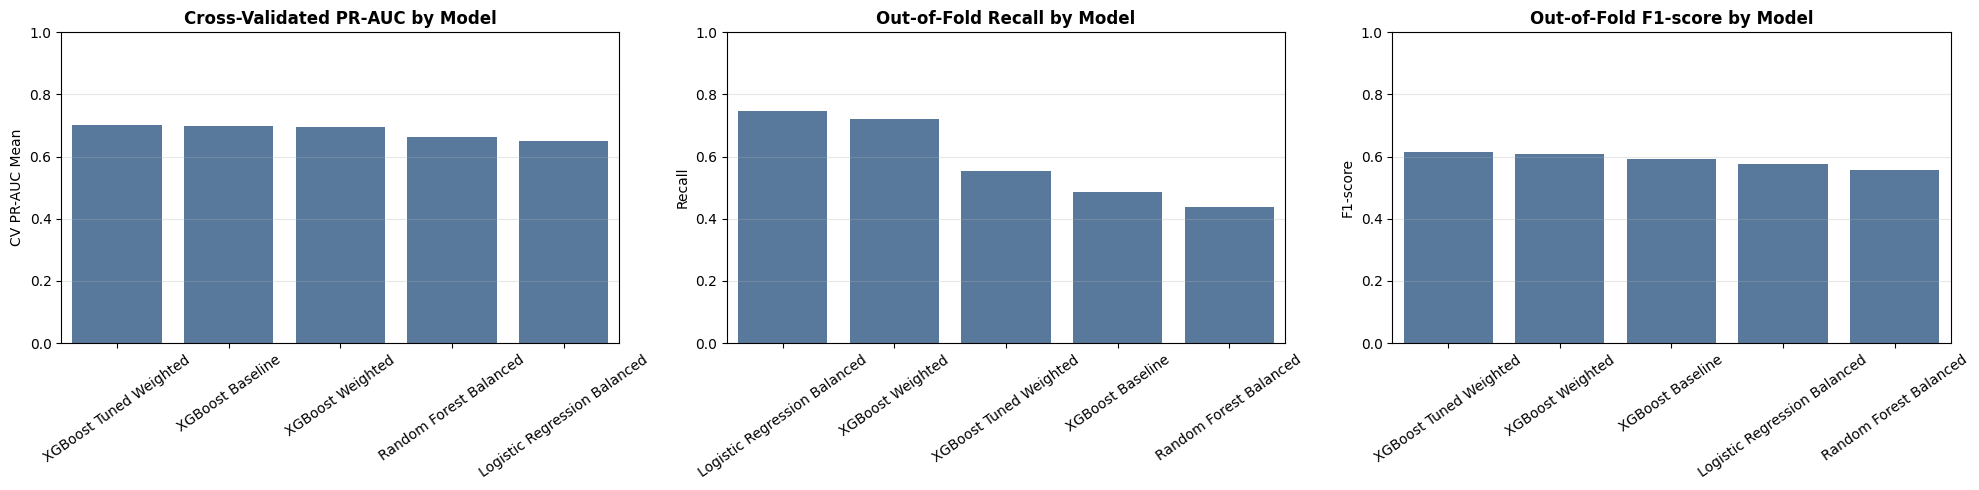

Model with the best cross-validation PR-AUC:
XGBoost Tuned Weighted

Pre-threshold selected model candidate:
XGBoost Tuned Weighted

Training-only model selection table:


,Model,Score Method,Default Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,CV PR-AUC Mean,...,CV ROC-AUC Mean,CV Recall Mean,CV Precision Mean,CV F1-score Mean,F1,PR-AUC Rank,Recall Rank,F1-score Rank,Stability Rank,Pre-Threshold Selection Score
0,XGBoost Tuned Weighted,predict_proba,0.5,0.859250,0.694145,0.552761,0.615437,0.864103,0.700032,0.700399,...,0.864418,0.552761,0.693703,0.615158,0.615437,1.0,3.0,1.0,3.0,1.6
1,XGBoost Weighted,predict_proba,0.5,0.811125,0.526670,0.720859,0.608651,0.860595,0.696180,0.696366,...,0.861046,0.720859,0.526662,0.608207,0.608651,3.0,2.0,2.0,5.0,2.8
2,XGBoost Baseline,predict_proba,0.5,0.863125,0.754036,0.487117,0.591875,0.861952,0.696833,0.697235,...,0.862313,0.487117,0.753624,0.591619,0.591875,2.0,4.0,3.0,4.0,2.8
3,Logistic Regression Balanced,predict_proba,0.5,0.776250,0.469183,0.747239,0.576432,0.841471,0.648688,0.649440,...,0.841757,0.747239,0.469513,0.576448,0.576432,5.0,1.0,4.0,1.0,3.6
4,Random Forest Balanced,predict_proba,0.5,0.857500,0.760085,0.439264,0.556765,0.850208,0.662182,0.663194,...,0.850230,0.435583,0.761375,0.553976,0.556765,4.0,5.0,5.0,2.0,4.2


In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

required_selection_variables = ["model_results_df", "models"]
missing_selection_variables = [name for name in required_selection_variables if name not in globals()]
if missing_selection_variables:
    raise NameError(
        "Run the cross-validated Model Evaluation section before selecting the best model. "
        f"Missing variables: {missing_selection_variables}"
    )

plot_df = model_results_df.copy()

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
chart_specs = [
    ("CV PR-AUC Mean", "Cross-Validated PR-AUC by Model"),
    ("Recall", "Out-of-Fold Recall by Model"),
    ("F1-score", "Out-of-Fold F1-score by Model"),
]

for axis, (metric, title) in zip(axes, chart_specs):
    ordered_df = plot_df.sort_values(metric, ascending=False)
    sns.barplot(
        data=ordered_df,
        x="Model",
        y=metric,
        ax=axis,
        color="#4C78A8",
    )
    axis.set_title(title)
    axis.set_xlabel("")
    axis.set_ylabel(metric)
    axis.tick_params(axis="x", rotation=35)
    axis.set_ylim(0, max(1.0, ordered_df[metric].max() * 1.1))
    axis.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

model_selection_df = model_results_df.copy()
model_selection_df["PR-AUC Rank"] = model_selection_df["CV PR-AUC Mean"].rank(ascending=False, method="min")
model_selection_df["Recall Rank"] = model_selection_df["Recall"].rank(ascending=False, method="min")
model_selection_df["F1-score Rank"] = model_selection_df["F1-score"].rank(ascending=False, method="min")
model_selection_df["Stability Rank"] = model_selection_df["CV PR-AUC Std"].rank(ascending=True, method="min")
model_selection_df["Pre-Threshold Selection Score"] = (
    0.50 * model_selection_df["PR-AUC Rank"]
    + 0.20 * model_selection_df["Recall Rank"]
    + 0.20 * model_selection_df["F1-score Rank"]
    + 0.10 * model_selection_df["Stability Rank"]
)
model_selection_df = model_selection_df.sort_values(
    by=["Pre-Threshold Selection Score", "CV PR-AUC Mean", "Recall", "F1-score"],
    ascending=[True, False, False, False],
).reset_index(drop=True)

cv_best_model_name = model_results_df.sort_values(
    by=["CV PR-AUC Mean", "CV ROC-AUC Mean", "Recall", "F1-score"],
    ascending=False,
).iloc[0]["Model"]

best_model_name = model_selection_df.iloc[0]["Model"]
best_model = models[best_model_name]
best_model_metrics = model_selection_df.iloc[0].to_dict()

print("Model with the best cross-validation PR-AUC:")
print(cv_best_model_name)

print("\nPre-threshold selected model candidate:")
print(best_model_name)

print("\nTraining-only model selection table:")
display(model_selection_df)


## 12. Threshold Tuning

Threshold tuning is needed because the default threshold of 0.50 may not match the business goal. The threshold is now selected from out-of-fold training predictions only, so `X_test` and `y_test` remain untouched until final evaluation.

The table below evaluates thresholds from approximately 0.10 to 0.90 for probability-producing models. Three candidate thresholds are tracked for each model: best F1-score, minimum recall of 0.80 while maximizing precision, and minimum assumed business cost.

`COST_FALSE_NEGATIVE = 5` and `COST_FALSE_POSITIVE = 1` are illustrative assumptions for comparing threshold trade-offs. They are not verified real business costs and should be changed when the bank defines a validated retention policy.


In [44]:
import pathlib
import numpy as np
import pandas as pd

from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

THRESHOLD_RESULTS_PATH = r"D:\FPT University\Coding\DSP\threshold_results.csv"

required_threshold_variables = [
    "model_oof_scores",
    "model_score_methods",
    "model_results_df",
    "models",
    "X_train_original",
    "y_train_original",
]
missing_threshold_variables = [name for name in required_threshold_variables if name not in globals()]
if missing_threshold_variables:
    raise NameError(
        "Run cross-validated model evaluation before threshold tuning. "
        f"Missing variables: {missing_threshold_variables}"
    )

y_train_original = pd.Series(y_train_original, name="Exited").astype(int)

COST_FALSE_NEGATIVE = 5
COST_FALSE_POSITIVE = 1
MIN_RECALL_REQUIREMENT = 0.80
THRESHOLD_SELECTION_OBJECTIVE = "Minimum Business Cost"


def make_threshold_grid(scores, score_method):
    if score_method == "predict_proba":
        return np.round(np.arange(0.10, 0.901, 0.01), 2)

    score_series = pd.Series(scores).dropna()
    if score_series.empty:
        raise ValueError("Cannot create a threshold grid from empty decision scores.")

    lower = float(score_series.quantile(0.10))
    upper = float(score_series.quantile(0.90))
    if np.isclose(lower, upper):
        lower = float(score_series.min())
        upper = float(score_series.max())
    return np.linspace(lower, upper, 81)


def evaluate_threshold_table(y_true, scores, thresholds):
    rows = []
    for threshold in thresholds:
        y_pred_threshold = (scores >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred_threshold, labels=[0, 1]).ravel()
        total_cost = fn * COST_FALSE_NEGATIVE + fp * COST_FALSE_POSITIVE

        rows.append({
            "Threshold": float(threshold),
            "Precision": precision_score(y_true, y_pred_threshold, zero_division=0),
            "Recall": recall_score(y_true, y_pred_threshold, zero_division=0),
            "F1-score": f1_score(y_true, y_pred_threshold, zero_division=0),
            "False Positives": int(fp),
            "False Negatives": int(fn),
            "Predicted Churn Count": int(y_pred_threshold.sum()),
            "Business Cost": int(total_cost),
        })
    return pd.DataFrame(rows)


def threshold_candidate_row(model_name, objective, row, available=True, diagnostic=""):
    if row is None:
        return {
            "Model": model_name,
            "Candidate Objective": objective,
            "Threshold": np.nan,
            "Precision": np.nan,
            "Recall": np.nan,
            "F1-score": np.nan,
            "False Positives": np.nan,
            "False Negatives": np.nan,
            "Predicted Churn Count": np.nan,
            "Business Cost": np.nan,
            "Candidate Available": False,
            "Diagnostic": diagnostic,
        }

    return {
        "Model": model_name,
        "Candidate Objective": objective,
        "Threshold": float(row["Threshold"]),
        "Precision": float(row["Precision"]),
        "Recall": float(row["Recall"]),
        "F1-score": float(row["F1-score"]),
        "False Positives": int(row["False Positives"]),
        "False Negatives": int(row["False Negatives"]),
        "Predicted Churn Count": int(row["Predicted Churn Count"]),
        "Business Cost": int(row["Business Cost"]),
        "Candidate Available": bool(available),
        "Diagnostic": diagnostic,
    }


model_threshold_tables = {}
selected_thresholds_by_model = {}
selected_threshold_objectives_by_model = {}
threshold_candidate_rows = []
selected_threshold_rows = []
threshold_tuning_notes = []

for model_name, oof_scores in model_oof_scores.items():
    score_method = model_score_methods.get(model_name)
    if score_method is None:
        threshold_tuning_notes.append(f"Skipped {model_name}: no score method was recorded.")
        continue

    try:
        oof_scores = np.asarray(oof_scores).ravel()
        threshold_values = make_threshold_grid(oof_scores, score_method)
        model_threshold_df = evaluate_threshold_table(y_train_original, oof_scores, threshold_values)
        model_threshold_df.insert(0, "Model", model_name)
        model_threshold_df.insert(1, "Score Method", score_method)
        model_threshold_tables[model_name] = model_threshold_df

        best_f1_row = model_threshold_df.sort_values(
            ["F1-score", "Recall", "Precision"],
            ascending=False,
        ).iloc[0]

        recall_candidates = model_threshold_df[model_threshold_df["Recall"].ge(MIN_RECALL_REQUIREMENT)]
        if recall_candidates.empty:
            recall_precision_row = None
            recall_diagnostic = f"No threshold met recall >= {MIN_RECALL_REQUIREMENT:.2f}."
        else:
            recall_precision_row = recall_candidates.sort_values(
                ["Precision", "Recall", "F1-score"],
                ascending=False,
            ).iloc[0]
            recall_diagnostic = ""

        business_cost_row = model_threshold_df.sort_values(
            ["Business Cost", "False Negatives", "False Positives", "F1-score"],
            ascending=[True, True, True, False],
        ).iloc[0]

        threshold_candidate_rows.append(
            threshold_candidate_row(model_name, "Maximize F1-score", best_f1_row)
        )
        threshold_candidate_rows.append(
            threshold_candidate_row(
                model_name,
                f"Recall >= {MIN_RECALL_REQUIREMENT:.2f}, then maximize Precision",
                recall_precision_row,
                available=recall_precision_row is not None,
                diagnostic=recall_diagnostic,
            )
        )
        threshold_candidate_rows.append(
            threshold_candidate_row(model_name, THRESHOLD_SELECTION_OBJECTIVE, business_cost_row)
        )

        selected_thresholds_by_model[model_name] = float(business_cost_row["Threshold"])
        selected_threshold_objectives_by_model[model_name] = THRESHOLD_SELECTION_OBJECTIVE
        selected_threshold_rows.append({
            "Model": model_name,
            "Threshold": float(business_cost_row["Threshold"]),
            "Threshold Selection Objective": THRESHOLD_SELECTION_OBJECTIVE,
            "OOF Selected Precision": float(business_cost_row["Precision"]),
            "OOF Selected Recall": float(business_cost_row["Recall"]),
            "OOF Selected F1-score": float(business_cost_row["F1-score"]),
            "OOF Selected False Positives": int(business_cost_row["False Positives"]),
            "OOF Selected False Negatives": int(business_cost_row["False Negatives"]),
            "OOF Selected Predicted Churn Count": int(business_cost_row["Predicted Churn Count"]),
            "OOF Selected Business Cost": int(business_cost_row["Business Cost"]),
        })
    except Exception as threshold_error:
        threshold_tuning_notes.append(
            f"Skipped {model_name}: threshold tuning failed with `{threshold_error}`."
        )

if not model_threshold_tables:
    raise ValueError("Threshold tuning did not produce results for any model.")

threshold_results_long_df = pd.concat(
    model_threshold_tables.values(),
    ignore_index=True,
)
threshold_candidate_summary_df = pd.DataFrame(threshold_candidate_rows)
selected_threshold_summary_df = pd.DataFrame(selected_threshold_rows)

model_selection_df = model_results_df.merge(
    selected_threshold_summary_df,
    on="Model",
    how="inner",
)

if model_selection_df.empty:
    raise ValueError("No models have both cross-validation results and selected thresholds.")

model_selection_df["PR-AUC Rank"] = model_selection_df["CV PR-AUC Mean"].rank(ascending=False, method="min")
model_selection_df["Recall Rank"] = model_selection_df["OOF Selected Recall"].rank(ascending=False, method="min")
model_selection_df["F1-score Rank"] = model_selection_df["OOF Selected F1-score"].rank(ascending=False, method="min")
model_selection_df["Business Cost Rank"] = model_selection_df["OOF Selected Business Cost"].rank(ascending=True, method="min")
model_selection_df["Stability Rank"] = model_selection_df["CV PR-AUC Std"].rank(ascending=True, method="min")
model_selection_df["Final Selection Score"] = (
    0.35 * model_selection_df["PR-AUC Rank"]
    + 0.25 * model_selection_df["Recall Rank"]
    + 0.20 * model_selection_df["F1-score Rank"]
    + 0.15 * model_selection_df["Business Cost Rank"]
    + 0.05 * model_selection_df["Stability Rank"]
)
model_selection_df = model_selection_df.sort_values(
    by=[
        "Final Selection Score",
        "CV PR-AUC Mean",
        "OOF Selected Recall",
        "OOF Selected F1-score",
        "OOF Selected Business Cost",
    ],
    ascending=[True, False, False, False, True],
).reset_index(drop=True)

final_model_name = model_selection_df.iloc[0]["Model"]
final_model = models[final_model_name]
best_model_name = final_model_name
best_model = final_model
SELECTED_THRESHOLD = float(selected_thresholds_by_model[final_model_name])
SELECTED_THRESHOLD_OBJECTIVE = selected_threshold_objectives_by_model[final_model_name]
threshold_results_df = model_threshold_tables[final_model_name].copy()

threshold_results_path = pathlib.Path(THRESHOLD_RESULTS_PATH)
threshold_results_path.parent.mkdir(parents=True, exist_ok=True)
threshold_results_long_df.to_csv(threshold_results_path, index=False)

print("Threshold candidate summary from out-of-fold training predictions:")
display(threshold_candidate_summary_df)

print("\nSelected threshold by model:")
display(selected_threshold_summary_df)

print("\nTraining-only final model selection table:")
display(model_selection_df)

print("\nFinal selected model before holdout evaluation:")
print(final_model_name)
print("Selected threshold:")
print(SELECTED_THRESHOLD)
print("Threshold selection objective:")
print(SELECTED_THRESHOLD_OBJECTIVE)

if threshold_tuning_notes:
    print("\nThreshold tuning notes:")
    for note in threshold_tuning_notes:
        print(f"- {note}")

print("\nthreshold_results.csv saved to:")
print(str(threshold_results_path.resolve()))


Threshold candidate summary from out-of-fold training predictions:


,Model,Candidate Objective,Threshold,Precision,Recall,F1-score,False Positives,False Negatives,Predicted Churn Count,Business Cost,Candidate Available,Diagnostic
0,Logistic Regression Balanced,Maximize F1-score,0.61,0.550725,0.652761,0.597417,868,566,1932,3698,True,
1,Logistic Regression Balanced,"Recall >= 0.80, then maximize Precision",0.43,0.415527,0.801227,0.547245,1837,324,3143,3457,True,
2,Logistic Regression Balanced,Minimum Business Cost,0.50,0.469183,0.747239,0.576432,1378,412,2596,3438,True,
3,Random Forest Balanced,Maximize F1-score,0.35,0.625495,0.580982,0.602417,567,683,1514,3982,True,
4,Random Forest Balanced,"Recall >= 0.80, then maximize Precision",0.17,0.427077,0.801227,0.557167,1752,324,3058,3372,True,
5,Random Forest Balanced,Minimum Business Cost,0.18,0.438160,0.788957,0.563417,1649,344,2935,3369,True,
6,XGBoost Baseline,Maximize F1-score,0.34,0.626782,0.620245,0.623497,602,619,1613,3697,True,
7,XGBoost Baseline,"Recall >= 0.80, then maximize Precision",0.15,0.441541,0.808589,0.571181,1667,312,2985,3227,True,
8,XGBoost Baseline,Minimum Business Cost,0.14,0.432111,0.823926,0.566906,1765,287,3108,3200,True,
9,XGBoost Weighted,Maximize F1-score,0.60,0.606916,0.646012,0.625854,682,577,1735,3567,True,



Selected threshold by model:


,Model,Threshold,Threshold Selection Objective,OOF Selected Precision,OOF Selected Recall,OOF Selected F1-score,OOF Selected False Positives,OOF Selected False Negatives,OOF Selected Predicted Churn Count,OOF Selected Business Cost
0,Logistic Regression Balanced,0.50,Minimum Business Cost,0.469183,0.747239,0.576432,1378,412,2596,3438
1,Random Forest Balanced,0.18,Minimum Business Cost,0.438160,0.788957,0.563417,1649,344,2935,3369
2,XGBoost Baseline,0.14,Minimum Business Cost,0.432111,0.823926,0.566906,1765,287,3108,3200
3,XGBoost Weighted,0.37,Minimum Business Cost,0.443174,0.808589,0.572546,1656,312,2974,3216
4,XGBoost Tuned Weighted,0.20,Minimum Business Cost,0.437601,0.832515,0.573663,1744,273,3101,3109



Training-only final model selection table:


,Model,Score Method,Default Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,CV PR-AUC Mean,...,OOF Selected False Positives,OOF Selected False Negatives,OOF Selected Predicted Churn Count,OOF Selected Business Cost,PR-AUC Rank,Recall Rank,F1-score Rank,Business Cost Rank,Stability Rank,Final Selection Score
0,XGBoost Tuned Weighted,predict_proba,0.5,0.859250,0.694145,0.552761,0.615437,0.864103,0.700032,0.700399,...,1744,273,3101,3109,1.0,1.0,2.0,1.0,3.0,1.3
1,XGBoost Baseline,predict_proba,0.5,0.863125,0.754036,0.487117,0.591875,0.861952,0.696833,0.697235,...,1765,287,3108,3200,2.0,2.0,4.0,2.0,4.0,2.5
2,XGBoost Weighted,predict_proba,0.5,0.811125,0.526670,0.720859,0.608651,0.860595,0.696180,0.696366,...,1656,312,2974,3216,3.0,3.0,3.0,3.0,5.0,3.1
3,Logistic Regression Balanced,predict_proba,0.5,0.776250,0.469183,0.747239,0.576432,0.841471,0.648688,0.649440,...,1378,412,2596,3438,5.0,5.0,1.0,5.0,1.0,4.0
4,Random Forest Balanced,predict_proba,0.5,0.857500,0.760085,0.439264,0.556765,0.850208,0.662182,0.663194,...,1649,344,2935,3369,4.0,4.0,5.0,4.0,2.0,4.1



Final selected model before holdout evaluation:
XGBoost Tuned Weighted
Selected threshold:
0.2
Threshold selection objective:
Minimum Business Cost

threshold_results.csv saved to:
D:\FPT University\Coding\DSP\threshold_results.csv


### 12.1 Final Fixed-Threshold Test Evaluation

The model and threshold are fixed before this cell runs. The holdout test set is used here only once for final reporting, confusion-matrix review, PR and ROC curves, and the final model comparison table.


Final fixed-threshold model comparison on untouched holdout test set:


,Model,Threshold,Threshold Selection Objective,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,False Positives,False Negatives,Business Cost,CV PR-AUC Mean,CV PR-AUC Std,CV PR-AUC Overfit Gap,Final Selection Score,F1
0,XGBoost Tuned Weighted,0.20,Minimum Business Cost,0.729,0.416974,0.832924,0.555738,0.865938,0.715560,474,68,814,0.700399,0.028039,0.106913,1.3,0.555738
1,XGBoost Baseline,0.14,Minimum Business Cost,0.724,0.412121,0.835381,0.551948,0.860680,0.709163,485,67,820,0.697235,0.028676,0.141730,2.5,0.551948
2,XGBoost Weighted,0.37,Minimum Business Cost,0.741,0.429658,0.832924,0.566890,0.859186,0.705220,450,68,790,0.696366,0.030871,0.146449,3.1,0.566890
3,Logistic Regression Balanced,0.50,Minimum Business Cost,0.775,0.467075,0.749386,0.575472,0.848766,0.686148,348,102,858,0.649440,0.016023,0.007157,4.0,0.575472
4,Random Forest Balanced,0.18,Minimum Business Cost,0.742,0.428571,0.803440,0.558974,0.849549,0.666559,436,80,836,0.663194,0.024209,0.336806,4.1,0.558974



Final selected model:
XGBoost Tuned Weighted
Selected threshold:
0.2
Threshold selection objective:
Minimum Business Cost

Confusion matrix at selected threshold:
[[1119  474]
 [  68  339]]

Classification report at selected threshold:
              precision    recall  f1-score   support

           0       0.94      0.70      0.81      1593
           1       0.42      0.83      0.56       407

    accuracy                           0.73      2000
   macro avg       0.68      0.77      0.68      2000
weighted avg       0.84      0.73      0.75      2000


model_results.csv saved to:
D:\FPT University\Coding\DSP\model_results.csv


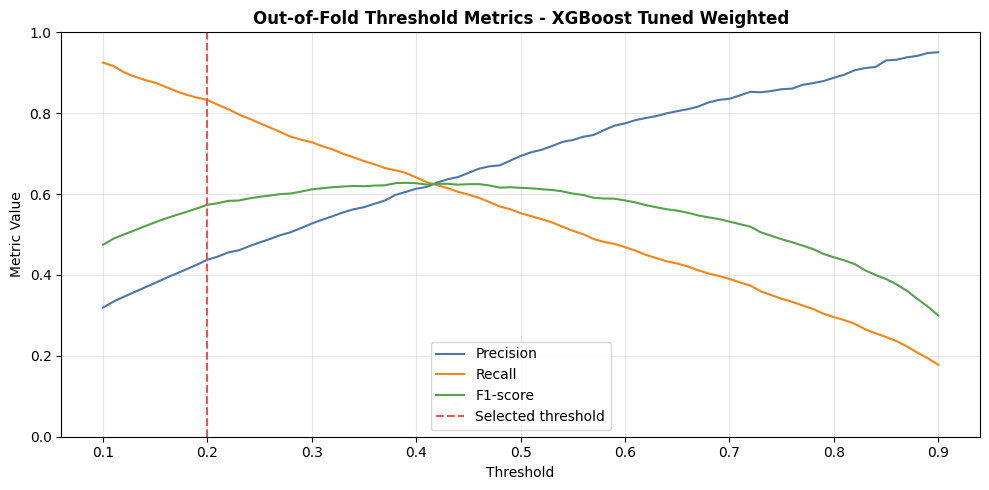

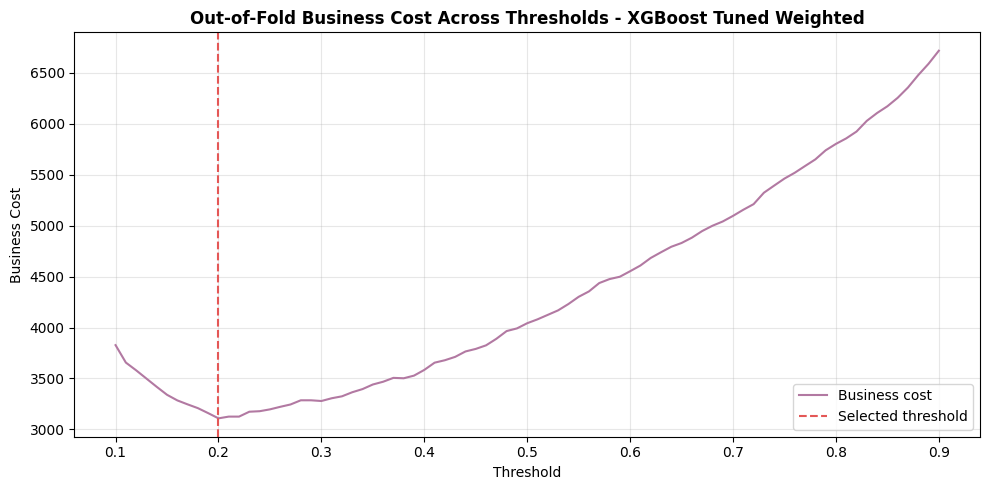

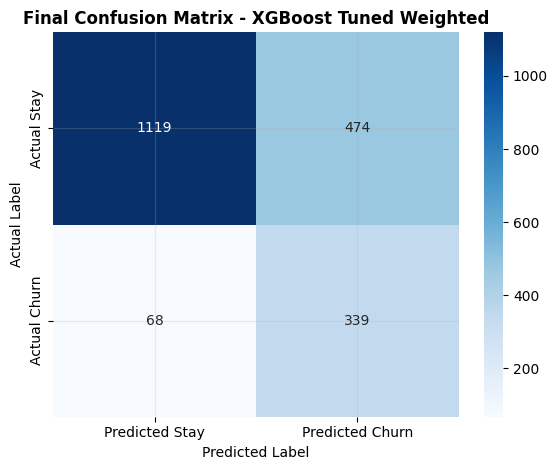

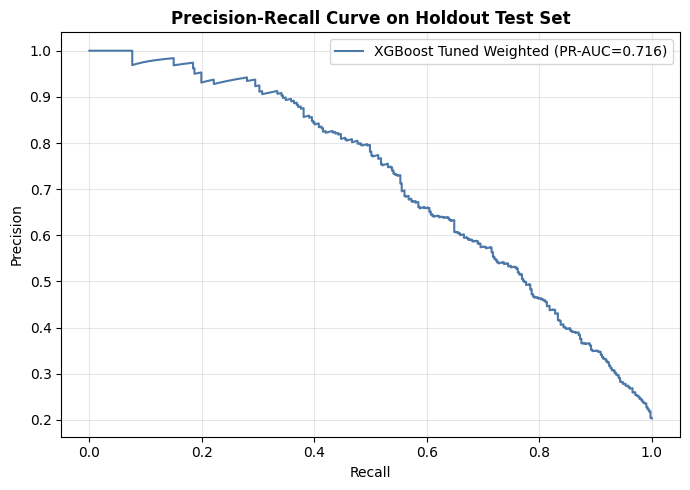

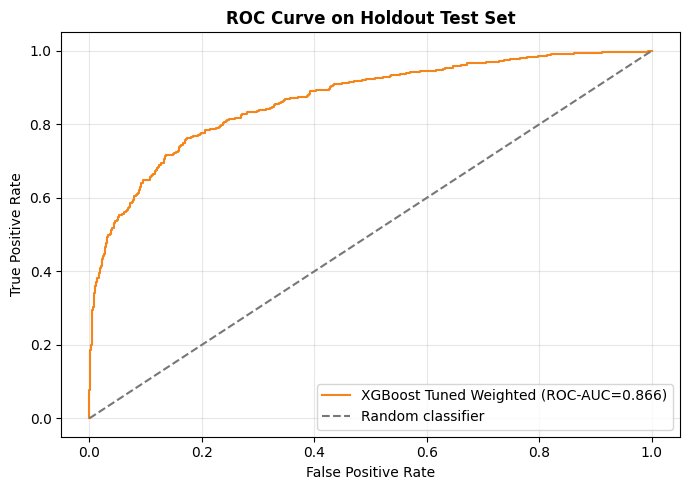

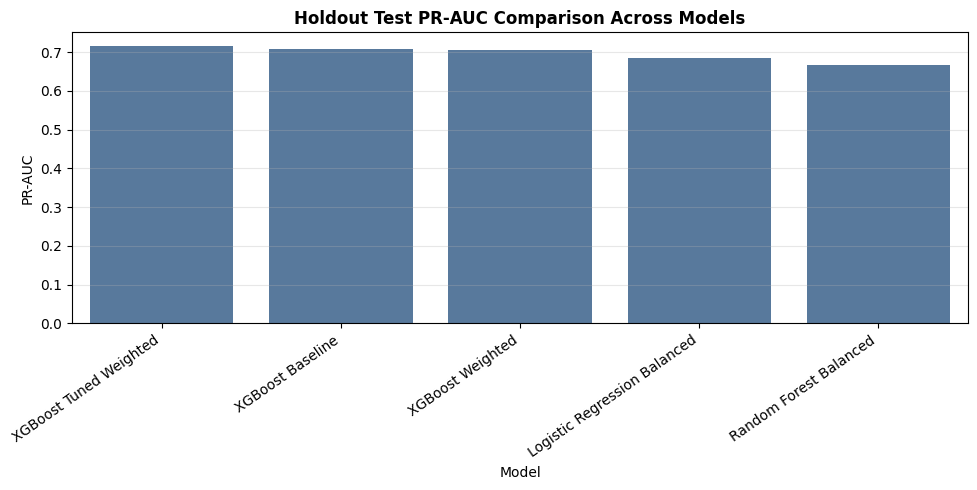

In [45]:
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    roc_curve,
)

MODEL_RESULTS_PATH = r"D:\FPT University\Coding\DSP\model_results.csv"

required_final_evaluation_variables = [
    "models",
    "selected_threshold_summary_df",
    "selected_thresholds_by_model",
    "selected_threshold_objectives_by_model",
    "model_score_methods",
    "model_selection_df",
    "final_model_name",
    "final_model",
    "X_test",
    "y_test",
]
missing_final_evaluation_variables = [
    name for name in required_final_evaluation_variables if name not in globals()
]
if missing_final_evaluation_variables:
    raise NameError(
        "Run threshold tuning before final fixed-threshold test evaluation. "
        f"Missing variables: {missing_final_evaluation_variables}"
    )

y_test = pd.Series(y_test, name="Exited").astype(int)


def predict_continuous_scores(model, X, score_method):
    if score_method == "predict_proba":
        if not callable(getattr(model, "predict_proba", None)):
            raise AttributeError("Model does not support predict_proba.")
        raw_scores = model.predict_proba(X)
        return np.asarray(raw_scores)[:, 1]

    if score_method == "decision_function":
        if not callable(getattr(model, "decision_function", None)):
            raise AttributeError("Model does not support decision_function.")
        return np.asarray(model.decision_function(X)).ravel()

    raise ValueError(f"Unsupported score method: {score_method}")


def safe_auc(metric_func, y_true, scores):
    try:
        return metric_func(y_true, scores)
    except ValueError:
        return np.nan


final_evaluation_rows = []
test_scores_by_model = {}
test_predictions_by_model = {}

for _, selected_row in selected_threshold_summary_df.iterrows():
    model_name = selected_row["Model"]
    model = models.get(model_name)
    threshold = float(selected_row["Threshold"])
    threshold_objective = selected_row["Threshold Selection Objective"]
    score_method = model_score_methods.get(model_name)

    if model is None or score_method is None:
        continue

    try:
        test_scores = predict_continuous_scores(model, X_test, score_method)
        test_predictions = (test_scores >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, test_predictions, labels=[0, 1]).ravel()
        business_cost = fn * COST_FALSE_NEGATIVE + fp * COST_FALSE_POSITIVE

        test_scores_by_model[model_name] = test_scores
        test_predictions_by_model[model_name] = test_predictions

        cv_lookup = model_results_df.set_index("Model").loc[model_name]
        selection_lookup = model_selection_df.set_index("Model").loc[model_name]

        final_evaluation_rows.append({
            "Model": model_name,
            "Threshold": threshold,
            "Threshold Selection Objective": threshold_objective,
            "Accuracy": accuracy_score(y_test, test_predictions),
            "Precision": precision_score(y_test, test_predictions, zero_division=0),
            "Recall": recall_score(y_test, test_predictions, zero_division=0),
            "F1-score": f1_score(y_test, test_predictions, zero_division=0),
            "ROC-AUC": safe_auc(roc_auc_score, y_test, test_scores),
            "PR-AUC": safe_auc(average_precision_score, y_test, test_scores),
            "False Positives": int(fp),
            "False Negatives": int(fn),
            "Business Cost": int(business_cost),
            "CV PR-AUC Mean": float(cv_lookup["CV PR-AUC Mean"]),
            "CV PR-AUC Std": float(cv_lookup["CV PR-AUC Std"]),
            "CV PR-AUC Overfit Gap": float(cv_lookup["CV PR-AUC Overfit Gap"]),
            "Final Selection Score": float(selection_lookup["Final Selection Score"]),
        })
    except Exception as final_evaluation_error:
        print(f"Skipping final evaluation for {model_name}: {final_evaluation_error}")

if not final_evaluation_rows:
    raise ValueError("No models could be evaluated on the holdout test set.")

final_model_comparison_df = pd.DataFrame(final_evaluation_rows).sort_values(
    by=["Final Selection Score", "CV PR-AUC Mean", "Recall", "F1-score", "Business Cost"],
    ascending=[True, False, False, False, True],
).reset_index(drop=True)
final_model_comparison_df["F1"] = final_model_comparison_df["F1-score"]

model_results_path = pathlib.Path(MODEL_RESULTS_PATH)
model_results_path.parent.mkdir(parents=True, exist_ok=True)
final_model_comparison_df.to_csv(model_results_path, index=False)

final_model_test_row = final_model_comparison_df[
    final_model_comparison_df["Model"].eq(final_model_name)
].iloc[0].to_dict()
final_model_test_metrics = final_model_test_row.copy()

SELECTED_THRESHOLD = float(final_model_test_row["Threshold"])
SELECTED_THRESHOLD_OBJECTIVE = final_model_test_row["Threshold Selection Objective"]
best_model_name = final_model_name
best_model = final_model
best_model_metrics = final_model_test_metrics

selected_test_scores = test_scores_by_model[final_model_name]
y_proba_selected = selected_test_scores
selected_test_predictions = test_predictions_by_model[final_model_name]
y_pred_selected = selected_test_predictions
selected_confusion_matrix = confusion_matrix(y_test, selected_test_predictions, labels=[0, 1])
selected_classification_report = classification_report(y_test, selected_test_predictions, zero_division=0)
selected_precision = float(final_model_test_row["Precision"])
selected_recall = float(final_model_test_row["Recall"])
selected_f1 = float(final_model_test_row["F1-score"])

print("Final fixed-threshold model comparison on untouched holdout test set:")
display(final_model_comparison_df)

print("\nFinal selected model:")
print(final_model_name)
print("Selected threshold:")
print(SELECTED_THRESHOLD)
print("Threshold selection objective:")
print(SELECTED_THRESHOLD_OBJECTIVE)
print("\nConfusion matrix at selected threshold:")
print(selected_confusion_matrix)
print("\nClassification report at selected threshold:")
print(selected_classification_report)

print("\nmodel_results.csv saved to:")
print(str(model_results_path.resolve()))

threshold_plot_df = model_threshold_tables[final_model_name].copy()

plt.figure(figsize=(10, 5))
plt.plot(threshold_plot_df["Threshold"], threshold_plot_df["Precision"], label="Precision", color="#4C78A8")
plt.plot(threshold_plot_df["Threshold"], threshold_plot_df["Recall"], label="Recall", color="#F58518")
plt.plot(threshold_plot_df["Threshold"], threshold_plot_df["F1-score"], label="F1-score", color="#54A24B")
plt.axvline(SELECTED_THRESHOLD, color="#E45756", linestyle="--", label="Selected threshold")
plt.title(f"Out-of-Fold Threshold Metrics - {final_model_name}")
plt.xlabel("Threshold")
plt.ylabel("Metric Value")
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(threshold_plot_df["Threshold"], threshold_plot_df["Business Cost"], color="#B279A2", label="Business cost")
plt.axvline(SELECTED_THRESHOLD, color="#E45756", linestyle="--", label="Selected threshold")
plt.title(f"Out-of-Fold Business Cost Across Thresholds - {final_model_name}")
plt.xlabel("Threshold")
plt.ylabel("Business Cost")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(5.8, 4.8))
sns.heatmap(
    selected_confusion_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted Stay", "Predicted Churn"],
    yticklabels=["Actual Stay", "Actual Churn"],
)
plt.title(f"Final Confusion Matrix - {final_model_name}")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

pr_precision, pr_recall, _ = precision_recall_curve(y_test, selected_test_scores)
plt.figure(figsize=(7, 5))
plt.plot(
    pr_recall,
    pr_precision,
    color="#4C78A8",
    label=f"{final_model_name} (PR-AUC={final_model_test_row['PR-AUC']:.3f})",
)
plt.title("Precision-Recall Curve on Holdout Test Set")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

fpr, tpr, _ = roc_curve(y_test, selected_test_scores)
plt.figure(figsize=(7, 5))
plt.plot(
    fpr,
    tpr,
    color="#F58518",
    label=f"{final_model_name} (ROC-AUC={final_model_test_row['ROC-AUC']:.3f})",
)
plt.plot([0, 1], [0, 1], color="#777777", linestyle="--", label="Random classifier")
plt.title("ROC Curve on Holdout Test Set")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
pr_auc_plot_df = final_model_comparison_df.sort_values("PR-AUC", ascending=False)
sns.barplot(
    data=pr_auc_plot_df,
    x="Model",
    y="PR-AUC",
    color="#4C78A8",
)
plt.title("Holdout Test PR-AUC Comparison Across Models")
plt.xlabel("Model")
plt.ylabel("PR-AUC")
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## 13. Explainable Machine Learning

Built-in XGBoost feature importance gives a global view of which transformed features are used most by the model. If the final selected model is an XGBoost pipeline, this section explains that final model. If the final selected model is not XGBoost, the section preserves the existing XGBoost explanation path by selecting the best available fitted XGBoost model from the training-only model-selection results.

The code extracts the fitted `preprocessor`, fitted classifier, transformed feature names, and transformed input data from the scikit-learn `Pipeline` before feature importance and SHAP are calculated.


XAI model selected:
XGBoost Tuned Weighted

XAI model note:
Explaining the final selected XGBoost model.

Top 20 built-in XGBoost feature importances:


,Feature,Importance
0,cat__NumOfProducts_2,0.131069
1,cat__NumOfProducts_1,0.085403
2,cat__AgeGroup_51-60,0.064331
3,cat__AgeGroup_41-50,0.059799
4,num__Age,0.058551
5,cat__NumOfProducts_3,0.046572
6,cat__IsActiveMember_1,0.046472
7,cat__AgeGroup_18-30,0.045220
8,cat__IsActiveMember_0,0.043706
9,cat__AgeGroup_31-40,0.042038


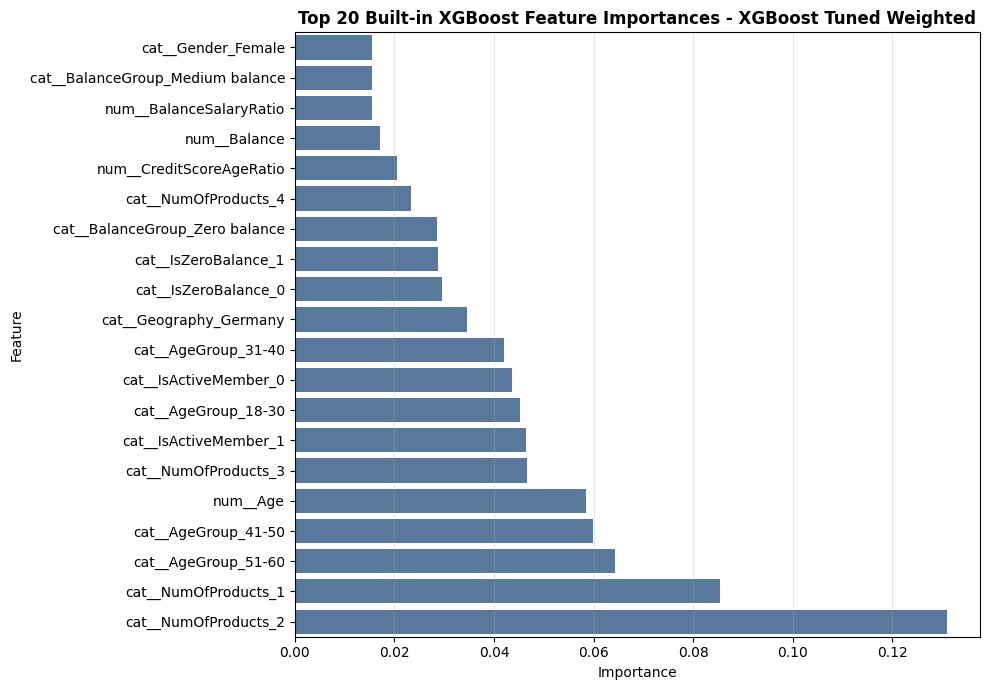

In [46]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

required_xai_variables = ["models", "X_test", "y_test"]
missing_xai_variables = [name for name in required_xai_variables if name not in globals()]
if missing_xai_variables:
    raise NameError(
        "Run model evaluation and best model selection before XAI. "
        f"Missing variables: {missing_xai_variables}"
    )

xgboost_model_objects = {
    "XGBoost Baseline": globals().get("xgb_baseline_model"),
    "XGBoost Weighted": globals().get("xgb_weighted_model"),
    "XGBoost Tuned Weighted": globals().get("xgb_tuned_best_model"),
}

final_or_best_model_name = globals().get("final_model_name", globals().get("best_model_name"))
final_or_best_model = globals().get("final_model", globals().get("best_model"))

if final_or_best_model_name and "XGBoost" in final_or_best_model_name and final_or_best_model is not None:
    xai_model = final_or_best_model
    xai_model_name = final_or_best_model_name
    xai_model_note = "Explaining the final selected XGBoost model."
else:
    available_xgboost_names = [
        model_name for model_name, model_object in xgboost_model_objects.items()
        if model_object is not None
    ]
    if not available_xgboost_names:
        raise ValueError("No fitted XGBoost model is available for explainability.")

    if "model_selection_df" in globals():
        xgboost_results_df = model_selection_df[
            model_selection_df["Model"].isin(available_xgboost_names)
        ].copy()
        if "Final Selection Score" in xgboost_results_df.columns:
            xgboost_results_df = xgboost_results_df.sort_values(
                by=["Final Selection Score", "CV PR-AUC Mean"],
                ascending=[True, False],
            )
        else:
            xgboost_results_df = xgboost_results_df.sort_values(
                by=["CV PR-AUC Mean", "Recall", "F1-score"],
                ascending=False,
            )
    elif "model_results_df" in globals():
        xgboost_results_df = model_results_df[
            model_results_df["Model"].isin(available_xgboost_names)
        ].copy()
        sort_columns = [
            column for column in ["CV PR-AUC Mean", "PR-AUC", "Recall", "F1-score", "F1"]
            if column in xgboost_results_df.columns
        ]
        xgboost_results_df = xgboost_results_df.sort_values(by=sort_columns, ascending=False)
    else:
        xgboost_results_df = pd.DataFrame({"Model": available_xgboost_names})

    if xgboost_results_df.empty:
        xai_model_name = available_xgboost_names[0]
    else:
        xai_model_name = xgboost_results_df.iloc[0]["Model"]

    xai_model = xgboost_model_objects[xai_model_name]
    xai_model_note = (
        "Final selected model is not XGBoost, so the best available fitted XGBoost "
        "pipeline is used for feature importance and SHAP compatibility."
    )

if xai_model is None:
    raise ValueError(f"Selected XAI model is not available: {xai_model_name}")

if not hasattr(xai_model, "named_steps"):
    raise TypeError("The XAI model must be a fitted scikit-learn Pipeline.")

xai_preprocessor = xai_model.named_steps.get("preprocessor")
xai_classifier = xai_model.named_steps.get("classifier")

if xai_preprocessor is None or xai_classifier is None:
    raise KeyError("The XAI pipeline must contain 'preprocessor' and 'classifier' steps.")

X_test_transformed = xai_preprocessor.transform(X_test)
feature_names = xai_preprocessor.get_feature_names_out()

if not hasattr(xai_classifier, "feature_importances_"):
    raise AttributeError(
        f"The selected XAI classifier for {xai_model_name} does not expose feature_importances_."
    )

xgb_feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xai_classifier.feature_importances_,
}).sort_values("Importance", ascending=False).reset_index(drop=True)

top_20_xgb_features = xgb_feature_importance_df.head(20)

print("XAI model selected:")
print(xai_model_name)
print("\nXAI model note:")
print(xai_model_note)

print("\nTop 20 built-in XGBoost feature importances:")
display(top_20_xgb_features)

plt.figure(figsize=(10, 7))
sns.barplot(
    data=top_20_xgb_features.sort_values("Importance", ascending=True),
    x="Importance",
    y="Feature",
    color="#4C78A8",
)
plt.title(f"Top 20 Built-in XGBoost Feature Importances - {xai_model_name}")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


### 13.1 Permutation Importance

Permutation importance measures how much model performance decreases when a feature is randomly shuffled. Since `scoring="average_precision"` is used, the importance values reflect impact on PR-AUC, which is suitable for imbalanced churn prediction.

Permutation importance is easier to interpret at the original feature level than built-in XGBoost importance, because it uses the original columns before one-hot encoding.


Top 20 permutation importances by average precision impact:


,Feature,Importance Mean,Importance Std
0,NumOfProducts,0.263924,0.014813
1,Age,0.160605,0.008934
2,IsActiveMember,0.094260,0.008978
3,Geography,0.042330,0.003873
4,Balance,0.017860,0.004290
5,Gender,0.010643,0.002501
6,BalanceSalaryRatio,0.006681,0.002314
7,CreditScoreAgeRatio,0.004375,0.002168
8,TenureAgeRatio,0.002717,0.001842
9,AgeGroup,0.001867,0.000672


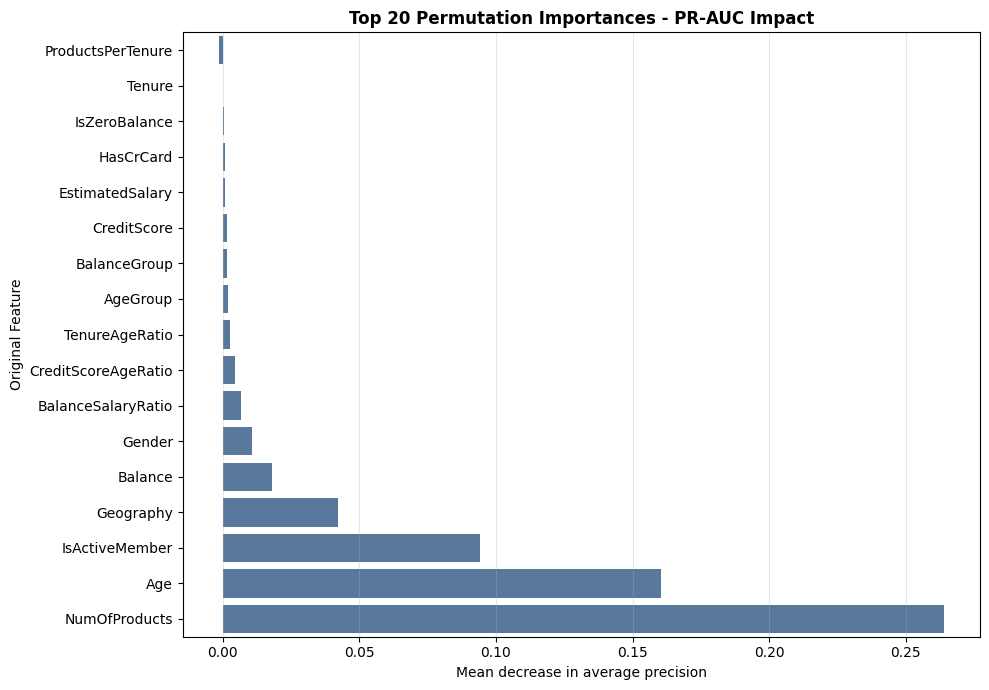

In [47]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.inspection import permutation_importance

required_permutation_variables = ["xai_model", "X_test", "y_test"]
missing_permutation_variables = [name for name in required_permutation_variables if name not in globals()]
if missing_permutation_variables:
    raise NameError(
        "Run the first Explainable Machine Learning cell before permutation importance. "
        f"Missing variables: {missing_permutation_variables}"
    )

if "RANDOM_STATE" not in globals():
    RANDOM_STATE = 42

y_test = pd.Series(y_test, name="Exited").astype(int)

perm_result = permutation_importance(
    xai_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=RANDOM_STATE,
    scoring="average_precision",
    n_jobs=-1,
)

permutation_importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance Mean": perm_result.importances_mean,
    "Importance Std": perm_result.importances_std,
}).sort_values("Importance Mean", ascending=False).reset_index(drop=True)

top_20_permutation_features = permutation_importance_df.head(20)

print("Top 20 permutation importances by average precision impact:")
display(top_20_permutation_features)

plt.figure(figsize=(10, 7))
sns.barplot(
    data=top_20_permutation_features.sort_values("Importance Mean", ascending=True),
    x="Importance Mean",
    y="Feature",
    color="#4C78A8",
)
plt.title("Top 20 Permutation Importances - PR-AUC Impact")
plt.xlabel("Mean decrease in average precision")
plt.ylabel("Original Feature")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


### 13.2 SHAP Explainability

Positive SHAP values push prediction toward churn. Negative SHAP values push prediction toward non-churn.

Churn drivers should be grouped carefully when interpreting the model:
- Age-related features
- Product usage features
- Activity status features
- Geography-related features
- Balance-related features
- Credit score-related features

Do not overclaim engineered features as independent causes. `AgeGroup` is derived from `Age`. `BalanceGroup`, `IsZeroBalance`, and `BalanceSalaryRatio` are derived from `Balance` and `EstimatedSalary`. `ProductsPerTenure` is derived from `NumOfProducts` and `Tenure`.

**SHAP install note:** If SHAP is not installed, run `# pip install shap` and rerun this subsection.


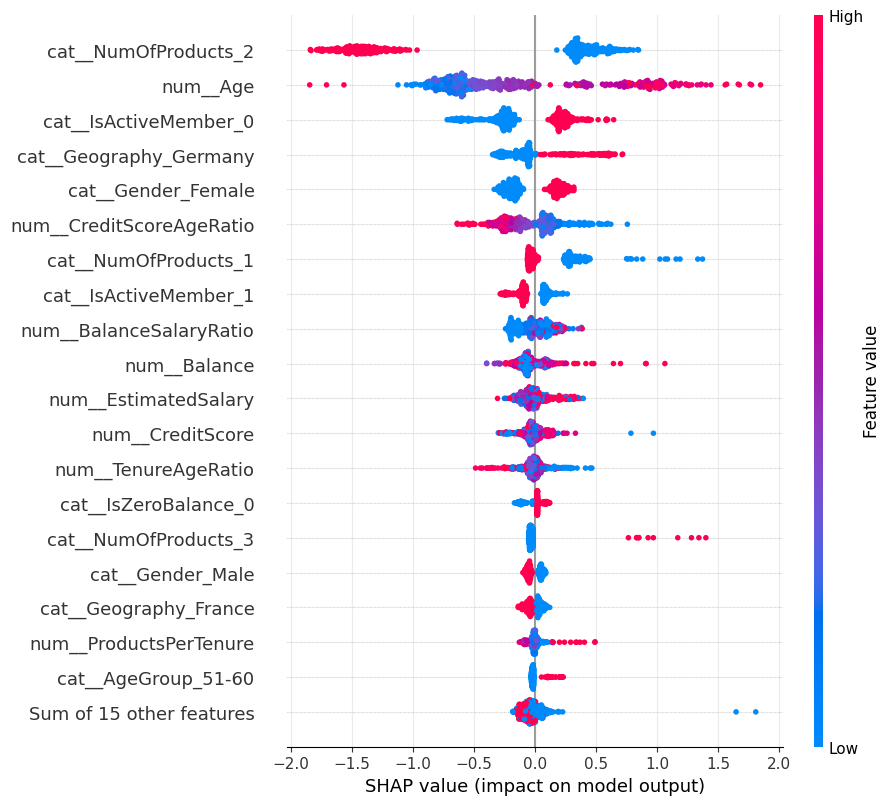

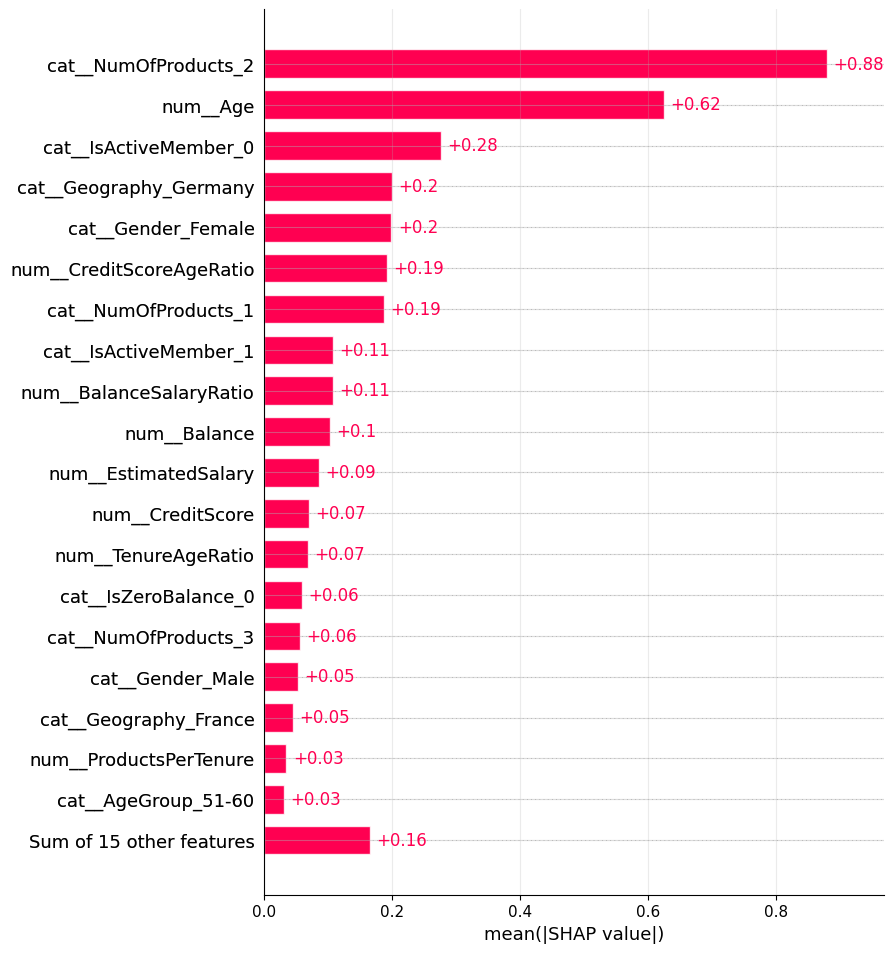

high_risk_index:
70

high_risk_probability:
0.9938


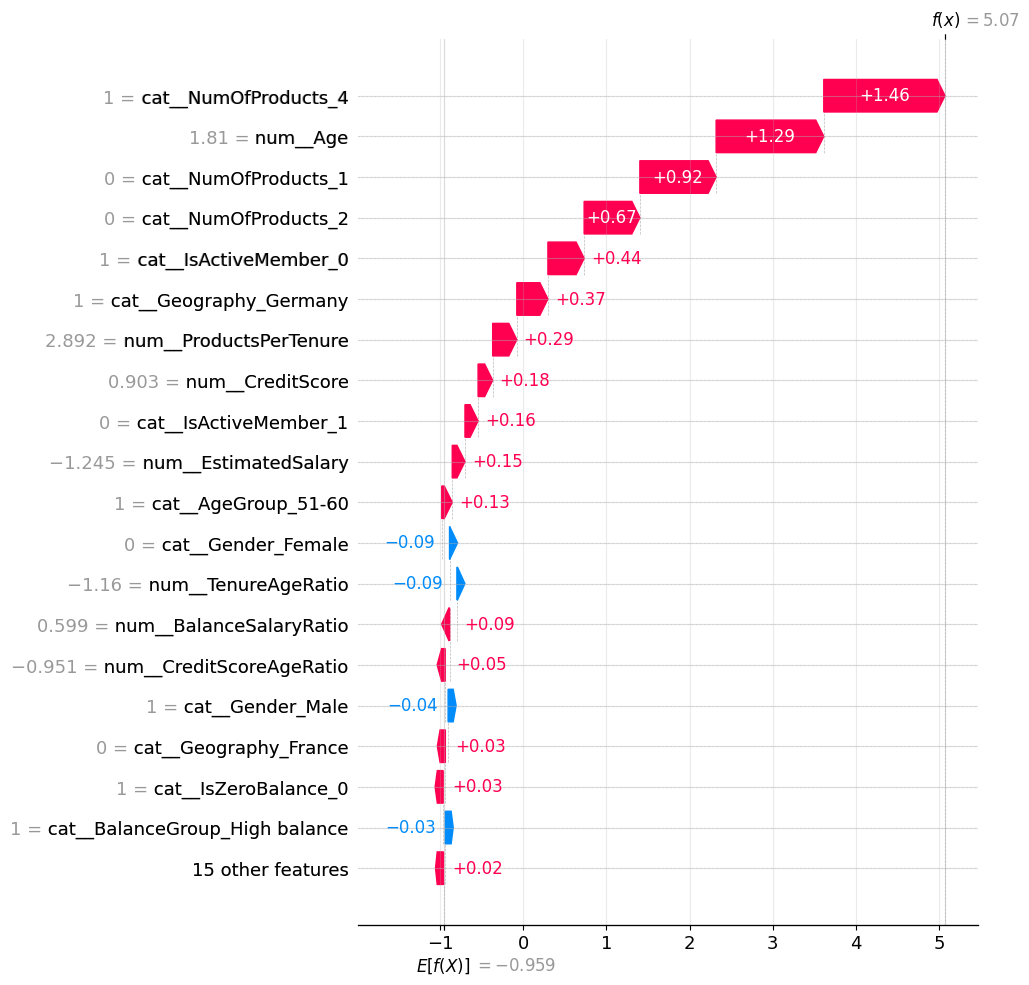

In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def show_markdown_note(message):
    try:
        from IPython.display import Markdown, display
        display(Markdown(message))
    except Exception:
        print(message)


required_shap_variables = [
    "xai_model",
    "xai_preprocessor",
    "xai_classifier",
    "X_test",
    "feature_names",
]

missing_shap_variables = [
    name for name in required_shap_variables if name not in globals()
]

if missing_shap_variables:
    raise NameError(
        "Run the earlier Explainable Machine Learning cells before SHAP explainability. "
        f"Missing variables: {missing_shap_variables}"
    )

if "RANDOM_STATE" not in globals():
    RANDOM_STATE = 42

try:
    import shap
    import xgboost as xgb
    shap_available = True
except ImportError:
    shap_available = False
    show_markdown_note(
        "**SHAP note:** `shap` or `xgboost` is not installed. "
        "Install them with `pip install shap xgboost` and rerun this cell."
    )


if shap_available:
    # 1. Sample test data for SHAP
    X_shap_raw = X_test.sample(
        n=min(500, len(X_test)),
        random_state=RANDOM_STATE
    )

    # 2. Transform data using the fitted preprocessor
    X_shap_transformed = xai_preprocessor.transform(X_shap_raw)

    if hasattr(X_shap_transformed, "toarray"):
        X_shap_dense = X_shap_transformed.toarray()
    else:
        X_shap_dense = X_shap_transformed

    feature_names = np.asarray(feature_names).astype(str)

    # 3. Use native XGBoost pred_contribs instead of shap.TreeExplainer
    booster = xai_classifier.get_booster()

    dmatrix = xgb.DMatrix(
        X_shap_dense,
        feature_names=list(feature_names)
    )

    shap_contribs = booster.predict(
        dmatrix,
        pred_contribs=True
    )

    # Last column is the bias/base value
    shap_values_array = shap_contribs[:, :-1]
    base_values = shap_contribs[:, -1]

    shap_values = shap.Explanation(
        values=shap_values_array,
        base_values=base_values,
        data=X_shap_dense,
        feature_names=list(feature_names)
    )

    # 4. SHAP beeswarm plot
    try:
        shap.plots.beeswarm(
            shap_values,
            max_display=20,
            show=True
        )
    except Exception as beeswarm_error:
        show_markdown_note(
            "**SHAP plotting note:** SHAP beeswarm plot could not be generated. "
            f"Error: `{beeswarm_error}`"
        )

    # 5. SHAP bar plot
    try:
        shap.plots.bar(
            shap_values,
            max_display=20,
            show=True
        )
    except Exception as bar_error:
        show_markdown_note(
            "**SHAP plotting note:** SHAP bar plot could not be generated. "
            f"Error: `{bar_error}`"
        )

    # 6. Select highest-risk customer
    high_risk_probabilities = xai_model.predict_proba(X_test)[:, 1]
    high_risk_position = int(np.argmax(high_risk_probabilities))
    high_risk_index = X_test.index[high_risk_position]
    high_risk_probability = float(high_risk_probabilities[high_risk_position])

    high_risk_customer = X_test.loc[[high_risk_index]].copy()

    high_risk_transformed = xai_preprocessor.transform(high_risk_customer)

    if hasattr(high_risk_transformed, "toarray"):
        high_risk_dense = high_risk_transformed.toarray()
    else:
        high_risk_dense = high_risk_transformed

    high_risk_dmatrix = xgb.DMatrix(
        high_risk_dense,
        feature_names=list(feature_names)
    )

    high_risk_contribs = booster.predict(
        high_risk_dmatrix,
        pred_contribs=True
    )

    high_risk_shap_values = shap.Explanation(
        values=high_risk_contribs[:, :-1],
        base_values=high_risk_contribs[:, -1],
        data=high_risk_dense,
        feature_names=list(feature_names)
    )

    print("high_risk_index:")
    print(high_risk_index)

    print("\nhigh_risk_probability:")
    print(round(high_risk_probability, 4))

    # 7. SHAP waterfall plot for one high-risk customer
    try:
        shap.plots.waterfall(
            high_risk_shap_values[0],
            max_display=20,
            show=True
        )
    except Exception as waterfall_error:
        show_markdown_note(
            "**SHAP plotting note:** SHAP waterfall plot could not be generated. "
            f"Error: `{waterfall_error}`"
        )

## 14. Customer Risk Segmentation

Customers are segmented by predicted churn probability. If the Very High Risk group has a much higher actual churn rate than the Low Risk group, the model successfully separates high-risk and low-risk customers.


In [49]:
import pathlib
import numpy as np
import pandas as pd

CUSTOMER_RISK_PREDICTIONS_PATH = r"D:\FPT University\Coding\DSP\customer_risk_predictions.csv"

required_segmentation_variables = ["best_model", "SELECTED_THRESHOLD", "X_test", "y_test"]
missing_segmentation_variables = [name for name in required_segmentation_variables if name not in globals()]
if missing_segmentation_variables:
    raise NameError(
        "Run Best Model Selection and Threshold Tuning before customer risk segmentation. "
        f"Missing variables: {missing_segmentation_variables}"
    )

if not callable(getattr(best_model, "predict_proba", None)):
    raise AttributeError(
        "Customer risk segmentation requires predict_proba so churn risk can be reported as a probability. "
        "Use a calibrated classifier before running this section."
    )

churn_probabilities = best_model.predict_proba(X_test)[:, 1]
predicted_churn = (churn_probabilities >= SELECTED_THRESHOLD).astype(int)

customer_risk_df = X_test.reset_index(drop=True).copy()

if "customer_id_test" in globals() and customer_id_test is not None:
    customer_risk_df.insert(0, "CustomerId", pd.Series(customer_id_test).reset_index(drop=True).values)

customer_risk_df["ActualExited"] = pd.Series(y_test).reset_index(drop=True).astype(int).values
customer_risk_df["ChurnProbability"] = churn_probabilities
customer_risk_df["PredictedChurn"] = predicted_churn

risk_conditions = [
    customer_risk_df["ChurnProbability"].ge(0.75),
    customer_risk_df["ChurnProbability"].ge(0.50) & customer_risk_df["ChurnProbability"].lt(0.75),
    customer_risk_df["ChurnProbability"].ge(0.30) & customer_risk_df["ChurnProbability"].lt(0.50),
    customer_risk_df["ChurnProbability"].lt(0.30),
]
risk_labels = ["Very High Risk", "High Risk", "Medium Risk", "Low Risk"]
customer_risk_df["RiskGroup"] = np.select(risk_conditions, risk_labels, default="Unknown")

risk_group_order = ["Very High Risk", "High Risk", "Medium Risk", "Low Risk"]
customer_risk_df["RiskGroup"] = pd.Categorical(
    customer_risk_df["RiskGroup"],
    categories=risk_group_order,
    ordered=True,
)

risk_group_summary = (
    customer_risk_df.groupby("RiskGroup", observed=False)
    .agg(
        **{
            "Customer Count": ("ActualExited", "size"),
            "Average Churn Probability": ("ChurnProbability", "mean"),
            "Actual Churn Rate": ("ActualExited", "mean"),
            "Average Balance": ("Balance", "mean"),
            "Average Estimated Salary": ("EstimatedSalary", "mean"),
        }
    )
    .reset_index()
)

customer_risk_predictions_path = pathlib.Path(CUSTOMER_RISK_PREDICTIONS_PATH)
customer_risk_predictions_path.parent.mkdir(parents=True, exist_ok=True)
customer_risk_df.to_csv(customer_risk_predictions_path, index=False)

print("Customer risk prediction sample:")
display(customer_risk_df.head())

print("\nRisk group summary:")
display(risk_group_summary)

print("\ncustomer_risk_predictions.csv saved to:")
print(str(customer_risk_predictions_path.resolve()))


Customer risk prediction sample:


,CustomerId,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,...,CreditScoreAgeRatio,TenureAgeRatio,IsZeroBalance,ProductsPerTenure,AgeGroup,BalanceGroup,ActualExited,ChurnProbability,PredictedChurn,RiskGroup
0,15749540,585,France,Male,36,7,0.00,2,1,0,...,15.810811,0.189189,1,0.250000,31-40,Zero balance,0,0.027487,0,Low Risk
1,15807340,525,Germany,Male,33,4,131023.76,2,0,0,...,15.441176,0.117647,0,0.400000,31-40,High balance,0,0.128333,0,Low Risk
2,15801062,557,Spain,Female,40,4,0.00,2,0,1,...,13.585366,0.097561,1,0.400000,31-40,Zero balance,0,0.060826,0,Low Risk
3,15572801,639,Spain,Male,34,5,139393.19,2,0,0,...,18.257143,0.142857,0,0.333333,31-40,High balance,0,0.080638,0,Low Risk
4,15600708,640,Spain,Female,34,3,77826.80,1,1,1,...,18.285714,0.085714,0,0.250000,31-40,Low balance,0,0.145795,0,Low Risk



Risk group summary:


,RiskGroup,Customer Count,Average Churn Probability,Actual Churn Rate,Average Balance,Average Estimated Salary
0,Very High Risk,150,0.886118,0.906667,92096.898933,100143.125333
1,High Risk,179,0.612802,0.513966,91974.449218,104289.112849
2,Medium Risk,254,0.387483,0.318898,99315.918228,103140.158189
3,Low Risk,1417,0.107209,0.069160,69375.461122,101036.757925



customer_risk_predictions.csv saved to:
D:\FPT University\Coding\DSP\customer_risk_predictions.csv


## 15. Retention Strategy Design

Retention strategies are personalized based on churn risk and customer characteristics. This avoids applying the same retention action to all customers.


In [50]:
import pathlib
import pandas as pd

RETENTION_PRIORITY_PATH = r"D:\FPT University\Coding\DSP\retention_priority_customers.csv"

if "customer_risk_df" not in globals():
    raise NameError("Run Customer Risk Segmentation before Retention Strategy Design.")

required_retention_columns = [
    "IsActiveMember",
    "NumOfProducts",
    "Geography",
    "Age",
    "Balance",
    "CreditScore",
    "ChurnProbability",
]
missing_retention_columns = [column for column in required_retention_columns if column not in customer_risk_df.columns]
if missing_retention_columns:
    raise KeyError(f"Missing columns needed for retention strategy design: {missing_retention_columns}")

high_balance_threshold = customer_risk_df["Balance"].quantile(0.75)
low_credit_score_threshold = customer_risk_df["CreditScore"].quantile(0.25)


def recommend_retention_strategy(row):
    recommendations = []

    if row["IsActiveMember"] == 0:
        recommendations.append("Run a re-engagement campaign with cashback or an activity-based reward")

    if row["NumOfProducts"] == 1:
        recommendations.append("Cross-sell a suitable second banking product")

    if row["NumOfProducts"] >= 3:
        recommendations.append("Offer a product portfolio review, product simplification, or financial advisory support")

    if row["Geography"] == "Germany":
        recommendations.append("Use a region-specific retention campaign or service quality review")

    if row["Age"] >= 45:
        recommendations.append("Provide personalized relationship management or advisory service")

    if row["Balance"] >= high_balance_threshold:
        recommendations.append("Offer priority banking, loyalty benefits, or a dedicated account manager")

    if row["CreditScore"] <= low_credit_score_threshold:
        recommendations.append("Provide financial health support or safer banking product recommendations")

    if not recommendations:
        recommendations.append("Send general loyalty communication and a satisfaction survey")

    return "; ".join(recommendations)


customer_risk_df = customer_risk_df.copy()
customer_risk_df["RetentionStrategy"] = customer_risk_df.apply(recommend_retention_strategy, axis=1)

retention_priority_df = customer_risk_df.sort_values(
    by="ChurnProbability",
    ascending=False,
).reset_index(drop=True)

retention_priority_path = pathlib.Path(RETENTION_PRIORITY_PATH)
retention_priority_path.parent.mkdir(parents=True, exist_ok=True)
retention_priority_df.to_csv(retention_priority_path, index=False)

print("High balance threshold:")
print(round(float(high_balance_threshold), 2))

print("\nLow credit score threshold:")
print(round(float(low_credit_score_threshold), 2))

print("\nTop 20 priority customers:")
display(retention_priority_df.head(20))

print("\nretention_priority_customers.csv saved to:")
print(str(retention_priority_path.resolve()))


High balance threshold:
127884.34

Low credit score threshold:
582.0

Top 20 priority customers:


,CustomerId,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,...,TenureAgeRatio,IsZeroBalance,ProductsPerTenure,AgeGroup,BalanceGroup,ActualExited,ChurnProbability,PredictedChurn,RiskGroup,RetentionStrategy
0,15703793,738,Germany,Male,58,2,133745.44,4,1,0,...,0.033898,0,1.333333,51-60,High balance,1,0.993760,1,Very High Risk,Run a re-engagement campaign with cashback or ...
1,15806808,834,Germany,Female,57,8,112281.60,3,1,0,...,0.137931,0,0.333333,51-60,Medium balance,1,0.992774,1,Very High Risk,Run a re-engagement campaign with cashback or ...
2,15589017,547,Germany,Male,55,4,111362.76,3,1,0,...,0.071429,0,0.600000,51-60,Medium balance,1,0.992757,1,Very High Risk,Run a re-engagement campaign with cashback or ...
3,15696989,469,Germany,Female,52,8,139493.25,3,0,0,...,0.150943,0,0.333333,51-60,High balance,1,0.986169,1,Very High Risk,Run a re-engagement campaign with cashback or ...
4,15647725,675,France,Female,61,5,62055.17,3,1,0,...,0.080645,0,0.500000,60+,Low balance,1,0.985691,1,Very High Risk,Run a re-engagement campaign with cashback or ...
5,15634551,727,Germany,Male,46,3,115248.11,4,1,0,...,0.063830,0,1.000000,41-50,Medium balance,1,0.980452,1,Very High Risk,Run a re-engagement campaign with cashback or ...
6,15622033,847,Germany,Female,41,3,101543.51,4,1,0,...,0.071429,0,1.000000,41-50,Medium balance,1,0.975196,1,Very High Risk,Run a re-engagement campaign with cashback or ...
7,15679249,351,Germany,Female,57,4,163146.46,1,1,0,...,0.068966,0,0.200000,51-60,Very high balance,1,0.973322,1,Very High Risk,Run a re-engagement campaign with cashback or ...
8,15624180,584,Germany,Female,37,10,134171.80,4,1,1,...,0.263158,0,0.363636,31-40,High balance,1,0.973221,1,Very High Risk,"Offer a product portfolio review, product simp..."
9,15624820,683,Spain,Male,56,7,50911.21,3,0,0,...,0.122807,0,0.375000,51-60,Low balance,1,0.972969,1,Very High Risk,Run a re-engagement campaign with cashback or ...



retention_priority_customers.csv saved to:
D:\FPT University\Coding\DSP\retention_priority_customers.csv


## 16. Business Impact Estimation

The bank should not target every high-risk customer. It should prioritize customers with both high churn probability and high expected business value. This makes retention more cost-effective.

`ExpectedBenefit` is a simplified business estimate, not an exact financial forecast. It is used to rank customers for retention prioritization.


In [51]:
import pathlib
import pandas as pd

RETENTION_BUSINESS_PRIORITY_PATH = r"D:\FPT University\Coding\DSP\retention_business_priority.csv"

if "retention_priority_df" in globals():
    business_base_df = retention_priority_df.copy()
elif "customer_risk_df" in globals():
    business_base_df = customer_risk_df.copy()

    if "RetentionStrategy" not in business_base_df.columns:
        high_balance_threshold = business_base_df["Balance"].quantile(0.75)
        low_credit_score_threshold = business_base_df["CreditScore"].quantile(0.25)

        def recommend_retention_strategy(row):
            recommendations = []

            if row["IsActiveMember"] == 0:
                recommendations.append("Run a re-engagement campaign with cashback or an activity-based reward")

            if row["NumOfProducts"] == 1:
                recommendations.append("Cross-sell a suitable second banking product")

            if row["NumOfProducts"] >= 3:
                recommendations.append("Offer a product portfolio review, product simplification, or financial advisory support")

            if row["Geography"] == "Germany":
                recommendations.append("Use a region-specific retention campaign or service quality review")

            if row["Age"] >= 45:
                recommendations.append("Provide personalized relationship management or advisory service")

            if row["Balance"] >= high_balance_threshold:
                recommendations.append("Offer priority banking, loyalty benefits, or a dedicated account manager")

            if row["CreditScore"] <= low_credit_score_threshold:
                recommendations.append("Provide financial health support or safer banking product recommendations")

            if not recommendations:
                recommendations.append("Send general loyalty communication and a satisfaction survey")

            return "; ".join(recommendations)

        business_base_df["RetentionStrategy"] = business_base_df.apply(recommend_retention_strategy, axis=1)
else:
    raise NameError("Run Customer Risk Segmentation before Business Impact Estimation.")

required_business_columns = ["Balance", "ChurnProbability"]
missing_business_columns = [column for column in required_business_columns if column not in business_base_df.columns]
if missing_business_columns:
    raise KeyError(f"Missing columns needed for business impact estimation: {missing_business_columns}")

retention_business_priority_df = business_base_df.copy()
retention_business_priority_df["CustomerValue"] = retention_business_priority_df["Balance"] * 0.02
retention_business_priority_df["RetentionCost"] = 50
retention_business_priority_df["ExpectedRetentionRate"] = 0.30
retention_business_priority_df["ExpectedBenefit"] = (
    retention_business_priority_df["ChurnProbability"]
    * retention_business_priority_df["CustomerValue"]
    * retention_business_priority_df["ExpectedRetentionRate"]
    - retention_business_priority_df["RetentionCost"]
)

retention_business_priority_df = retention_business_priority_df.sort_values(
    by="ExpectedBenefit",
    ascending=False,
).reset_index(drop=True)

retention_business_priority_path = pathlib.Path(RETENTION_BUSINESS_PRIORITY_PATH)
retention_business_priority_path.parent.mkdir(parents=True, exist_ok=True)
retention_business_priority_df.to_csv(retention_business_priority_path, index=False)

print("Top 20 customers by ExpectedBenefit:")
display(retention_business_priority_df.head(20))

print("\nretention_business_priority.csv saved to:")
print(str(retention_business_priority_path.resolve()))


Top 20 customers by ExpectedBenefit:


,CustomerId,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,...,BalanceGroup,ActualExited,ChurnProbability,PredictedChurn,RiskGroup,RetentionStrategy,CustomerValue,RetentionCost,ExpectedRetentionRate,ExpectedBenefit
0,15757408,655,Spain,Male,38,3,250898.09,3,0,1,...,Very high balance,1,0.952725,1,Very High Risk,"Offer a product portfolio review, product simp...",5017.9618,50,0.3,1384.221556
1,15594408,584,Spain,Female,48,2,213146.20,1,1,0,...,Very high balance,1,0.834684,1,Very High Risk,Run a re-engagement campaign with cashback or ...,4262.9240,50,0.3,1017.457822
2,15811588,664,Spain,Female,53,7,187602.18,1,1,0,...,Very high balance,1,0.903279,1,Very High Risk,Run a re-engagement campaign with cashback or ...,3752.0436,50,0.3,966.742195
3,15679249,351,Germany,Female,57,4,163146.46,1,1,0,...,Very high balance,1,0.973322,1,Very High Risk,Run a re-engagement campaign with cashback or ...,3262.9292,50,0.3,902.764674
4,15764604,586,France,Female,35,7,164769.02,3,1,0,...,Very high balance,1,0.929399,1,Very High Risk,Run a re-engagement campaign with cashback or ...,3295.3804,50,0.3,868.817400
5,15740442,603,France,Male,51,8,186825.57,1,1,0,...,Very high balance,1,0.811657,1,Very High Risk,Run a re-engagement campaign with cashback or ...,3736.5114,50,0.3,859.829903
6,15625426,754,Germany,Female,55,3,161608.81,1,1,0,...,Very high balance,1,0.923684,1,Very High Risk,Run a re-engagement campaign with cashback or ...,3232.1762,50,0.3,845.653122
7,15743293,651,Germany,Female,35,1,163700.78,3,1,1,...,Very high balance,1,0.911595,1,Very High Risk,"Offer a product portfolio review, product simp...",3274.0156,50,0.3,845.372921
8,15775318,590,Spain,Female,51,3,154962.99,3,0,1,...,Very high balance,1,0.961777,1,Very High Risk,"Offer a product portfolio review, product simp...",3099.2598,50,0.3,844.239122
9,15815490,670,Germany,Male,40,2,164948.98,3,0,0,...,Very high balance,1,0.902108,1,Very High Risk,Run a re-engagement campaign with cashback or ...,3298.9796,50,0.3,842.811075



retention_business_priority.csv saved to:
D:\FPT University\Coding\DSP\retention_business_priority.csv


## 17. Final Conclusion

This final conclusion is generated from the result variables produced by the tuning, threshold-selection, final evaluation, and XAI sections. Run the notebook from the beginning to populate the updated metrics, selected threshold, false-positive and false-negative counts, business-cost estimate, and baseline comparison.

The conclusion warns when PR-AUC differences are small because a small difference may not be meaningful without stability checks or uncertainty analysis.


In [52]:
import numpy as np
import pandas as pd

try:
    from IPython.display import Markdown, display
except Exception:
    Markdown = None


def format_metric(value, digits=4):
    if value is None or pd.isna(value):
        return "N/A"
    return f"{float(value):.{digits}f}"


def format_count(value):
    if value is None or pd.isna(value):
        return "N/A"
    return f"{int(value)}"


def show_conclusion_markdown(lines):
    conclusion_text = "\n".join(lines)
    if Markdown is not None:
        display(Markdown(conclusion_text))
    else:
        print(conclusion_text)


required_conclusion_variables = [
    "final_model_comparison_df",
    "model_selection_df",
    "final_model_name",
    "SELECTED_THRESHOLD",
    "SELECTED_THRESHOLD_OBJECTIVE",
]
missing_conclusion_variables = [name for name in required_conclusion_variables if name not in globals()]

if missing_conclusion_variables:
    show_conclusion_markdown([
        "### Final Model Summary Pending Execution",
        "Run the notebook from the beginning to generate the updated final conclusion.",
        f"Missing result variables: `{missing_conclusion_variables}`.",
    ])
else:
    final_row = final_model_comparison_df[
        final_model_comparison_df["Model"].eq(final_model_name)
    ].iloc[0]

    cv_best_row = model_results_df.sort_values(
        by=["CV PR-AUC Mean", "CV ROC-AUC Mean", "Recall", "F1-score"],
        ascending=False,
    ).iloc[0]
    cv_best_model_name = cv_best_row["Model"]

    if "xgb_tuned_search" in globals() and xgb_tuned_search is not None:
        best_hyperparameters = xgb_tuned_search.best_params_
    elif "xgb_tuned_search_v2" in globals() and xgb_tuned_search_v2 is not None:
        best_hyperparameters = xgb_tuned_search_v2.best_params_
    else:
        best_hyperparameters = "XGBoost tuning was not executed in this run."

    if isinstance(best_hyperparameters, dict):
        best_hyperparameters_text = "; ".join(
            f"{key}={value}" for key, value in sorted(best_hyperparameters.items())
        )
    else:
        best_hyperparameters_text = str(best_hyperparameters)

    preferred_baselines = [
        "Logistic Regression Balanced",
        "XGBoost Baseline",
        "Random Forest Balanced",
    ]
    baseline_reference_model_name = next(
        (
            model_name for model_name in preferred_baselines
            if model_name in final_model_comparison_df["Model"].values
            and model_name != final_model_name
        ),
        None,
    )

    if baseline_reference_model_name is None:
        baseline_comparison_text = "No separate baseline model was available in the final comparison table."
        improvement_text = "Improvement cannot be assessed without a baseline row."
    else:
        baseline_row = final_model_comparison_df[
            final_model_comparison_df["Model"].eq(baseline_reference_model_name)
        ].iloc[0]
        pr_auc_delta = float(final_row["PR-AUC"] - baseline_row["PR-AUC"])
        recall_delta = float(final_row["Recall"] - baseline_row["Recall"])
        f1_delta = float(final_row["F1-score"] - baseline_row["F1-score"])
        cost_delta = int(final_row["Business Cost"] - baseline_row["Business Cost"])

        baseline_comparison_text = (
            f"Compared with `{baseline_reference_model_name}`, the final model changes PR-AUC by "
            f"{pr_auc_delta:+.4f}, Recall by {recall_delta:+.4f}, F1-score by {f1_delta:+.4f}, "
            f"and business cost by {cost_delta:+d} under the stated assumptions."
        )

        if abs(pr_auc_delta) < 0.01:
            improvement_text = "The PR-AUC improvement is minor."
        elif abs(pr_auc_delta) < 0.03:
            improvement_text = "The PR-AUC improvement is modest."
        else:
            improvement_text = "The PR-AUC improvement is substantial by this notebook's simple threshold."

    conclusion_lines = [
        "### Executed Final Model Summary",
        f"- Best cross-validation PR-AUC model: `{cv_best_model_name}` with CV PR-AUC `{format_metric(cv_best_row['CV PR-AUC Mean'])}` and fold standard deviation `{format_metric(cv_best_row['CV PR-AUC Std'])}`.",
        f"- Final selected model: `{final_model_name}`.",
        f"- Best XGBoost hyperparameters: `{best_hyperparameters_text}`.",
        f"- Selected classification threshold: `{format_metric(SELECTED_THRESHOLD, digits=3)}`.",
        f"- Threshold-selection objective: `{SELECTED_THRESHOLD_OBJECTIVE}`.",
        f"- Final holdout test results: Accuracy `{format_metric(final_row['Accuracy'])}`, Precision `{format_metric(final_row['Precision'])}`, Recall `{format_metric(final_row['Recall'])}`, F1-score `{format_metric(final_row['F1-score'])}`, ROC-AUC `{format_metric(final_row['ROC-AUC'])}`, PR-AUC `{format_metric(final_row['PR-AUC'])}`.",
        f"- False Positives: `{format_count(final_row['False Positives'])}`; False Negatives: `{format_count(final_row['False Negatives'])}`.",
        f"- Business cost under COST_FALSE_NEGATIVE={COST_FALSE_NEGATIVE} and COST_FALSE_POSITIVE={COST_FALSE_POSITIVE}: `{format_count(final_row['Business Cost'])}`.",
        f"- Baseline comparison: {baseline_comparison_text}",
        f"- Improvement assessment: {improvement_text}",
        "- Warning: a small PR-AUC difference may not be meaningful without stability checks, confidence intervals, or repeated validation.",
    ]

    show_conclusion_markdown(conclusion_lines)


### Executed Final Model Summary
- Best cross-validation PR-AUC model: `XGBoost Tuned Weighted` with CV PR-AUC `0.7004` and fold standard deviation `0.0280`.
- Final selected model: `XGBoost Tuned Weighted`.
- Best XGBoost hyperparameters: `classifier__colsample_bytree=0.694084963103261; classifier__gamma=0.1; classifier__learning_rate=0.007347723723532555; classifier__max_delta_step=5; classifier__max_depth=4; classifier__min_child_weight=3; classifier__n_estimators=1491; classifier__reg_alpha=0.0001; classifier__reg_lambda=0.12488676131232634; classifier__scale_pos_weight=1.5; classifier__subsample=0.889052370695725`.
- Selected classification threshold: `0.200`.
- Threshold-selection objective: `Minimum Business Cost`.
- Final holdout test results: Accuracy `0.7290`, Precision `0.4170`, Recall `0.8329`, F1-score `0.5557`, ROC-AUC `0.8659`, PR-AUC `0.7156`.
- False Positives: `474`; False Negatives: `68`.
- Business cost under COST_FALSE_NEGATIVE=5 and COST_FALSE_POSITIVE=1: `814`.
- Baseline comparison: Compared with `Logistic Regression Balanced`, the final model changes PR-AUC by +0.0294, Recall by +0.0835, F1-score by -0.0197, and business cost by -44 under the stated assumptions.
- Improvement assessment: The PR-AUC improvement is modest.
- Warning: a small PR-AUC difference may not be meaningful without stability checks, confidence intervals, or repeated validation.